In [1]:
from pathlib import Path
import ast
import hashlib
import platform
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
assert ROOT.is_dir(), f"项目目录不存在：{ROOT}"

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

print("=== 执行环境 ===")
print("Python:", sys.version)
print("Executable:", sys.executable)
print("Platform:", platform.platform())
print("Project:", ROOT)

# 1. 核对正式实验所依赖的现有文件
required = [
    "requirements.txt",
    "configs/splits.yaml",
    "configs/station.yaml",
    "configs/tariff.yaml",
    "configs/normalization.yaml",
    "experiments/run_all.py",
    "experiments/run_rolling.py",
    "experiments/run_static.py",
    "src/metrics.py",
    "src/rolling_horizon.py",
    "src/baselines.py",
    "src/simulator.py",
    "src/acnsim_adapter.py",
    "src/optimization_model.py",
    "report/stage3_acceptance.md",
    "report/stage3_artifact_index.csv",
]

print("\n=== 文件存在性与哈希 ===")
missing = []
for rel in required:
    path = ROOT / rel
    if path.is_file():
        print(f"{rel}\n  bytes={path.stat().st_size}, sha256={sha256(path)}")
    else:
        missing.append(rel)
        print(f"MISSING: {rel}")

# 2. 读取配置及阶段三验收报告
print("\n=== 现有配置与验收报告 ===")
for rel in [
    "configs/splits.yaml",
    "configs/station.yaml",
    "configs/tariff.yaml",
    "configs/normalization.yaml",
    "configs/final.yaml",
    "report/stage3_acceptance.md",
]:
    path = ROOT / rel
    print(f"\n--- {rel} ---")
    if path.is_file():
        print(path.read_text(encoding="utf-8"))
    else:
        print("尚不存在")

# 3. 提取接口，不导入项目模块，避免执行模块级代码
print("\n=== 模块接口 ===")
for rel in [
    "src/metrics.py",
    "src/rolling_horizon.py",
    "src/baselines.py",
    "src/simulator.py",
    "src/optimization_model.py",
    "experiments/run_rolling.py",
    "experiments/run_static.py",
]:
    path = ROOT / rel
    if not path.is_file():
        continue
    print(f"\n--- {rel} ---")
    try:
        tree = ast.parse(path.read_text(encoding="utf-8-sig"))
        for node in tree.body:
            if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
                print(f"def {node.name}({ast.unparse(node.args)})")
            elif isinstance(node, ast.ClassDef):
                print(f"class {node.name}")
                for item in node.body:
                    if isinstance(item, (ast.FunctionDef, ast.AsyncFunctionDef)):
                        print(f"  def {item.name}({ast.unparse(item.args)})")
    except (SyntaxError, UnicodeError) as exc:
        print(f"PARSE ERROR: {exc}")

# 4. 读取已验收统一入口，确定如何复用其运行与审计逻辑
path = ROOT / "experiments/run_all.py"
print("\n=== experiments/run_all.py 完整源码 ===")
if path.is_file():
    for number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(), start=1
    ):
        print(f"{number:04d}: {line}")

print("\n=== 检查结束 ===")
print("缺失文件：", missing or "无")
print("本单元未运行调度、未读取测试成绩、未修改任何文件。")

=== 执行环境 ===
Python: 3.11.18 (main, Oct 26 2026, 11:35:17) [GCC 15.3.0]
Executable: /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/.envs/ev-charging/bin/python
Platform: Linux-6.8.0-147-generic-x86_64-with-glibc2.39
Project: /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization

=== 文件存在性与哈希 ===
requirements.txt
  bytes=1031, sha256=91ced6f716e673ba9ea8d2808f7d2d359e84c9f5c08aa9f085276b88baecd1b6
configs/splits.yaml
  bytes=927, sha256=cbdfe0600695cf9ef2d0d2a063e2da056b03378ad4a4dc666962e7b813e2c34e
configs/station.yaml
  bytes=771, sha256=688b90bdb00afd49c73777ad3c816b3b8841274a6e4dc0757728d585749202b9
configs/tariff.yaml
  bytes=464, sha256=1d5a6b3c26cc64d89681017412f71447657d3d652d8c8e93655a425fbbc5f6d4
configs/normalization.yaml
  bytes=1754, sha256=104577ab3e48921c50885cd45a1a441190b105f48026271ab47547e9d2c7bb50
experiments/run_all.py
  bytes=22947, sha256=d8d8d7120cba2c8a0913186d778aa71bed40e394e2240b2f5a2077a8bbc932d1
experiments/run_rolling.py
  bytes=13255, sh

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import platform
import sys
import yaml

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

# 核对已回传的关键文件，防止核对期间发生变化
expected = {
    "report/stage3_acceptance.md":
        "9a15bcd90ce19a4732e99c69453aa5fc83ba013cfe6acec093c8b0c0f501e980",
    "report/stage3_artifact_index.csv":
        "ffc0a0d13db243c2d302111b6ab4005a450a8b4f238e892c890423419113aa85",
    "experiments/run_all.py":
        "d8d8d7120cba2c8a0913186d778aa71bed40e394e2240b2f5a2077a8bbc932d1",
    "src/rolling_horizon.py":
        "50fe6a14d65247fb63daaca400e0416d5107da6d720d5f1a7a5e4da5e5adcf84",
    "configs/normalization.yaml":
        "104577ab3e48921c50885cd45a1a441190b105f48026271ab47547e9d2c7bb50",
}
for rel, value in expected.items():
    assert digest(ROOT / rel) == value, f"文件已变化：{rel}"

# 核对归一化文件所记录的来源代码与输入
norm = yaml.safe_load(
    (ROOT / "configs/normalization.yaml").read_text(encoding="utf-8")
)
assert abs(float(norm["C_ref"]) - 2.88) < 1e-12
assert abs(float(norm["P_ref"]) - 6.656) < 1e-12
source_checks = {}
for rel, value in norm["source_and_input_sha256"].items():
    path = ROOT / rel
    assert path.is_file(), f"来源文件缺失：{rel}"
    actual = digest(path)
    assert actual == value, f"归一化来源已变化：{rel}"
    source_checks[rel] = actual

# 草案仅用于确定实施范围；正式 final.yaml 留待验证后生成
design = {
    "status": "draft_not_frozen",
    "validation_policy": (
        "Check the plan defaults on the full validation split before test; "
        "any parameter changes must be recorded before freezing."
    ),
    "cohorts": ["main_at_arrival", "supplement_after_submission"],
    "methods": ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"],
    "main_parameters": {
        "alpha": 0.5,
        "control_interval_minutes": 15,
        "base_horizon_hours": 24,
        "horizon_extension": "latest_visible_expected_departure",
        "capacity_kw": 50.0,
        "C_ref": float(norm["C_ref"]),
        "P_ref": float(norm["P_ref"]),
        "epsilon_U_kwh": 1e-5,
        "service_epsilon_kwh": 0.01,
        "online_two_stage_time_limit_seconds": 30,
    },
    "required_experiments": {
        "E1": "four methods, full test split, separate cohorts",
        "E2": {"alpha": [0.2, 0.5, 0.8]},
        "E3": {"capacity_kw": [37.5, 50.0, 62.5]},
        "E4": {
            "demand_estimate_relative_errors": [0, -0.1, 0.1, -0.2, 0.2],
            "early_departure_minutes": [0, 15, 30],
            "policy": (
                "Separate single-factor scenarios; targets and estimates "
                "stored separately; paired scenarios for online methods."
            ),
            "mechanism_and_seed_list": "to_be_defined_before_test",
        },
    },
    "execution_policy": {
        "fresh_rh_execution": True,
        "static_identity": "offline_full_information_oracle",
        "preserve_failed_runs": True,
        "test_based_parameter_selection": False,
        "original_branch_constraints_enforced": False,
    },
}

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUT = ROOT / "results" / "logs" / f"stage4_design_preflight_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

(OUT / "experiment_design_draft.yaml").write_text(
    yaml.safe_dump(design, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)
record = {
    "status": "preflight_passed_design_not_frozen",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "executable": sys.executable,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "logical_cpu_count": os.cpu_count(),
    "checked_sha256": expected,
    "normalization_source_checks": source_checks,
    "experiments_started": False,
}
(OUT / "preflight.json").write_text(
    json.dumps(record, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("预检查通过；证据目录：", OUT)
print("实验设计为草案，尚未冻结，尚未运行实验。")

# 补齐控制器返回值、实际峰值反馈和结果保存细节
for rel in ["src/rolling_horizon.py", "experiments/run_rolling.py"]:
    path = ROOT / rel
    print(f"\n=== {rel} | sha256={digest(path)} ===")
    print(path.read_text(encoding="utf-8-sig"))

预检查通过；证据目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_design_preflight_20261112T093259783051Z
实验设计为草案，尚未冻结，尚未运行实验。

=== src/rolling_horizon.py | sha256=50fe6a14d65247fb63daaca400e0416d5107da6d720d5f1a7a5e4da5e5adcf84 ===
"""Rolling controller: visible inputs only; existing two-stage LP in a worker."""
from pathlib import Path
from time import perf_counter
import csv
import json
import math
import subprocess
import sys
import traceback
import pandas as pd
from .baselines import _state, _time, _number

ROOT = Path(__file__).resolve().parents[1]
DELTA = pd.Timedelta(minutes=15)

def deadlines_for(now, cars):
    result = {}
    for car in cars:
        estimate = _time(car["expected_departure"])
        result[car["id"]] = (
            now + DELTA if estimate <= now else estimate.floor(DELTA))
    return result

def edf_command(view):
    now, _, capacity, cars = _state(view, 15)
    deadlines = deadlines_for(now, cars)
    command = {}
    for car in

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import json
import subprocess
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
source_path = ROOT / "experiments/run_all.py"
source = source_path.read_text(encoding="utf-8")

assert hashlib.sha256(source_path.read_bytes()).hexdigest() == (
    "d8d8d7120cba2c8a0913186d778aa71bed40e394e2240b2f5a2077a8bbc932d1"
), "原入口已变化，请停止并回传提示。"

def replace_once(old, new):
    global source
    assert source.count(old) == 1, (
        f"替换位置不唯一或不存在：{old[:100]!r}"
    )
    source = source.replace(old, new, 1)

# ---------- 参数与模块接口 ----------
replace_once(
    "import shutil\n",
    "import shutil\nimport argparse\n"
)
replace_once(
    "from src.rolling_horizon import _invoke, _first_command",
    "from src.rolling_horizon import (\n"
    "    _invoke, _first_command, RollingHorizonController,\n"
    "    record_realized_peaks,\n"
    ")"
)
replace_once(
    "OUT = Path(sys.argv[1])",
    '''parser = argparse.ArgumentParser()
parser.add_argument("output_directory")
parser.add_argument("--split", choices=["validation"], default="validation")
parser.add_argument("--alpha", type=float, default=0.5)
parser.add_argument("--capacity-kw", type=float, default=50.0)
parser.add_argument("--base-hours", type=float, default=24.0)
parser.add_argument("--static-time-limit", type=float, default=120.0)
args = parser.parse_args()
if not 0 <= args.alpha <= 1:
    parser.error("alpha must be in [0, 1]")
if not all(np.isfinite(v) and v > 0 for v in [
    args.capacity_kw, args.base_hours, args.static_time_limit
]):
    parser.error("capacity, horizon and static budget must be finite and positive")
OUT = Path(args.output_directory).resolve()
if not OUT.is_dir():
    parser.error("output directory must already exist")
'''
)

# ---------- 集合、容量及范围 ----------
replace_once(
    'capacity = float(station["station_capacity_kW"])',
    'capacity = args.capacity_kw'
)
replace_once(
    'start = pd.Timestamp(splits["splits"]["development"]["start_utc_inclusive"])',
    'start = pd.Timestamp(splits["splits"][args.split]["start_utc_inclusive"])'
)
replace_once(
    'dev_end = pd.Timestamp(splits["splits"]["development"]["end_utc_exclusive"])',
    'dev_end = pd.Timestamp(splits["splits"][args.split]["end_utc_exclusive"])'
)
replace_once(
    "arrival_end = start + pd.Timedelta(days=7)",
    "arrival_end = dev_end"
)

a = source.index('old = json.loads((RH / "verification.json")')
b = source.index('check("frozen scope and references"', a)
source = source[:a] + source[b:]

replace_once(
    '''for cohort, expected_count in [
    ("main_at_arrival", 5), ("supplement_after_submission", 198),
]:''',
    '''for cohort, expected_count in [
    ("main_at_arrival", 19), ("supplement_after_submission", 258),
]:'''
)
replace_once(
    '(sessions["split"] == "development")',
    '(sessions["split"] == args.split)'
)

a = source.index('    prior_summary = next(')
b = source.index('    # One evaluator-only table', a)
source = source[:a] + source[b:]

# 统一 ISO8601 解析，保留混合整秒／纳秒精度
source = source.replace(
    'pd.to_datetime(sessions["connectionTime"], utc=True)',
    'pd.to_datetime(sessions["connectionTime"], utc=True, format="ISO8601")'
).replace(
    'pd.to_datetime(events["event_time"], utc=True)',
    'pd.to_datetime(events["event_time"], utc=True, format="ISO8601")'
).replace(
    'pd.to_datetime(u["modifiedAt"], utc=True)',
    'pd.to_datetime(u["modifiedAt"], utc=True, format="ISO8601")'
)

# ---------- 移除旧 RH 复用分支；四方法统一新建环境 ----------
a = source.index('        if method == "RH_LP":\n')
b = source.index('        # All online traces', a)
body_start = source.index(
    '            runtime_sessions = selected.copy()', a
)
body = source[body_start:b]
body = "".join(
    line[4:] if line.startswith("    ") else line
    for line in body.splitlines(keepends=True)
)
source = source[:a] + body + source[b:]

replace_once(
    '"dt": .25, "alpha": .5,',
    '"dt": .25, "alpha": args.alpha,'
)
replace_once(
    '"epsilon_U": 1e-5, "time_limit_seconds": 120,',
    '"epsilon_U": 1e-5, "time_limit_seconds": args.static_time_limit,'
)
replace_once(
    'static_report = _invoke(case, static_dir, 120)',
    'static_report = _invoke(case, static_dir, args.static_time_limit)'
)

replace_once(
    '        rows, previous = [], None',
    '''        controller = (
            RollingHorizonController(
                folder / "rh_decisions", price_at,
                C_ref=norm["C_ref"], P_ref=norm["P_ref"],
                alpha=args.alpha, base_hours=args.base_hours,
                epsilon_U=1e-5, time_limit_seconds=30, timezone=TZ,
            ) if method == "RH_LP" else None
        )
        peaks = {}
        rows, previous = [], None'''
)

replace_once(
    'result = tou_greedy(state, price_at, details=True)',
    'result = tou_greedy(\n'
    '                        state, price_at, base_hours=args.base_hours,\n'
    '                        details=True)'
)

replace_once(
    '''                else:
                    raw = plan_by_time.get(environment.now.isoformat(), {})''',
    '''                elif method == "RH_LP":
                    decision = controller.decide(state, dict(peaks))
                    command = decision["command"]
                    diagnostic = decision
                    if decision["mode"] == "lp":
                        step = Path(decision["step_directory"])
                        case = json.loads(
                            (step / "case.json").read_text(encoding="utf-8")
                        )
                        visible = {
                            v["id"]: v for v in state["vehicles"]
                            if v["target_kwh"] is not None
                            and v["remaining_kwh"] > 1e-9
                            and v["arrival"].ceil("15min") <= environment.now
                        }
                        assert {c["id"] for c in case["sessions"]} == set(visible)
                        for car in case["sessions"]:
                            assert abs(
                                car["demand"] -
                                visible[car["id"]]["remaining_kwh"]
                            ) <= 1e-8
                        today = str(environment.now.tz_convert(TZ).date())
                        for day, value in case["past_peak"].items():
                            expected_peak = (
                                peaks.get(day, 0.0) if day == today else 0.0
                            )
                            assert abs(value - expected_peak) <= 1e-8
                        assert decision["solve_report"]["peak_by_day_kW"][
                            today
                        ] >= peaks.get(today, 0.0) - 1e-6
                        current = csv_bundle(step / "lp/plan.csv")
                else:
                    raw = plan_by_time.get(environment.now.isoformat(), {})'''
)

replace_once(
    '''"mode": ("static_replay" if method == "Static_LP"
                             else "rule") if active else "empty",''',
    '''"mode": (
                        decision["mode"] if method == "RH_LP" else
                        (("static_replay" if method == "Static_LP"
                          else "rule") if active else "empty")
                    ),'''
)
replace_once(
    '''                    "fallback": False,''',
    '''                    "fallback": (
                        decision["fallback"] if method == "RH_LP" else False
                    ),
                    "reason": (
                        decision["reason"] if method == "RH_LP" else None
                    ),
                    "step_directory": (
                        decision["step_directory"] if method == "RH_LP" else None
                    ),
                    "effective_horizon_hours": (
                        decision["effective_horizon_hours"]
                        if method == "RH_LP" else
                        diagnostic.get("effective_horizon_hours")
                    ),
                    "two_stage_solver_seconds": (
                        sum(s["seconds"] for s in
                            decision["solve_report"]["stages"])
                        if method == "RH_LP" and decision["solve_report"]
                        else None
                    ),'''
)

replace_once(
    '                environment.step(command)',
    '''                ledger_index = len(environment.ledger)
                environment.step(command)
                if method == "RH_LP":
                    record_realized_peaks(
                        peaks, environment.ledger[ledger_index:],
                        environment.now, TZ,
                    )
                if len(rows) % 96 == 0:
                    progress = {
                        "cohort": cohort, "method": method,
                        "time": str(environment.now),
                        "steps": len(rows),
                        "fallbacks": sum(bool(r["fallback"]) for r in rows),
                    }
                    (OUT / "progress.json").write_text(
                        json.dumps(progress, indent=2), encoding="utf-8"
                    )
                    print(json.dumps(progress), flush=True)'''
)

# ---------- 保留审计，回退作为待审查结果记录 ----------
a = source.index('        if method == "RH_LP":\n', source.index(
    '        summary, daily, service = evaluate_run('
))
b = source.index('        if method == "Static_LP":', a)
source = source[:a] + source[b:]

replace_once(
    '''        check(f"{cohort}/{method}: no unexpected fallback",
              timing["fallback_count"] == 0)''',
    '''        check(f"{cohort}/{method}: processing below control interval",
              decisions["total_seconds"].max() < 900)'''
)
replace_once(
    '            rh_reused=(method == "RH_LP"),',
    '''            split=args.split, run_id=OUT.name,
            alpha=args.alpha, capacity_kw=capacity,
            base_horizon_hours=args.base_hours,
            rh_reused=False,''',
)
replace_once(
    '            constraint_violation_duration_hours=0.0,',
    '''            requires_review=bool(
                timing["fallback_count"] > 0 or
                (method == "RH_LP" and
                 timing["active_P95_seconds"] > 30)
            ),'''
)

# ---------- 运行前后哈希一致性、配置和来源记录 ----------
capture = '''
input_paths = [
    Path(__file__), ROOT / "requirements.txt",
    *sorted((ROOT / "src").glob("*.py")),
    *[ROOT / "configs" / name for name in [
        "station.yaml", "splits.yaml", "tariff.yaml", "normalization.yaml"
    ]],
    *[DATA / name for name in [
        "sessions_with_split.csv", "environment_events.csv",
        "input_release_events.csv", "user_updates.csv"
    ]],
    ROOT / "data/external/tariff.csv",
    ROOT / "report/stage3_acceptance.md",
    ROOT / "report/stage3_artifact_index.csv",
]
input_before = {
    str(p.relative_to(ROOT)): digest(p) for p in input_paths
}
(OUT / "run_config.json").write_text(
    json.dumps({
        **vars(args), "run_id": OUT.name,
        "scope": "full validation; not formal test results",
        "source_and_input_sha256": input_before,
    }, ensure_ascii=False, indent=2), encoding="utf-8"
)
'''
replace_once(
    'grid = pd.date_range(start, dev_end + pd.Timedelta(days=2),',
    capture + '\ngrid = pd.date_range(start, dev_end + pd.Timedelta(days=2),'
)
replace_once(
    'check("normalization unchanged",',
    '''check("all tracked source and input files unchanged",
      all(digest(ROOT / rel) == value
          for rel, value in input_before.items()))
check("normalization unchanged",'''
)

# 删除原来仅适用于阶段三的文字说明
a = source.index('policy = """')
b = source.index('(OUT / "integration_policy.md")', a)
source = source[:a] + '''policy = """# Full validation evaluation

All four methods use the full validation split and fresh execution.
Cohorts are evaluated separately. No test experiment is run.
References and source inputs are hashed before and after execution.

Static LP is an offline full-information oracle using true connections
and post-hoc evaluation targets. Online methods receive released inputs.
Static complete-slot service is not automatically a lower bound on
online service with intra-slot departures.

Fees, service and actual piecewise peaks are reported jointly.
Fallbacks are retained and flagged for review.
Original Caltech branch and phase constraints are not enforced.
"""
''' + source[b:]

replace_once(
    '    RH / "verification.json",',
    '    ROOT / "report/stage3_acceptance.md",'
)
replace_once(
    '    "rh_reused": True, "rh_source": str(RH),',
    '''    "rh_reused": False, "split": args.split,
    "run_id": OUT.name,
    "requires_review": any(r["requires_review"] for r in comparisons),'''
)
replace_once(
    '"scope": "stage 3 development integration, not formal test results",',
    '"scope": "full validation; not formal test results",'
)
replace_once(
    '''    "source_and_input_sha256": {
        str(p.relative_to(ROOT)): digest(p) for p in tracked},''',
    '    "source_and_input_sha256": input_before,'
)
replace_once(
    '    "rh_reused": True, "wall_seconds": result["wall_seconds"],',
    '''    "rh_reused": False,
    "requires_review": result["requires_review"],
    "wall_seconds": result["wall_seconds"],'''
)
replace_once(
    '=== Development integration comparison ===',
    '=== Full validation comparison ==='
)
replace_once(
    'table.to_csv(OUT / "comparison.csv", index=False)',
    '''table.to_csv(OUT / "comparison.csv", index=False)
table[[
    "run_id", "split", "cohort", "method", "alpha",
    "capacity_kw", "base_horizon_hours", "requires_review"
]].to_csv(OUT / "run_manifest.csv", index=False)'''
)

# 先检查生成代码语法，再保存新入口
ast.parse(source)
target = ROOT / "experiments/run_evaluation.py"
if target.exists():
    assert target.read_text(encoding="utf-8") == source, (
        "run_evaluation.py 已存在且内容不同；未覆盖，请回传提示。"
    )
else:
    target.write_text(source, encoding="utf-8")

print("新入口语法检查通过：", target)
print("SHA-256:", hashlib.sha256(target.read_bytes()).hexdigest())

# ---------- 独立进程运行验证集 ----------
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
VALIDATION_OUT = ROOT / "results/logs" / f"stage4_validation_{stamp}"
VALIDATION_OUT.mkdir(parents=True, exist_ok=False)

command = [
    sys.executable, "-u", str(target), str(VALIDATION_OUT),
    "--split", "validation",
    "--alpha", "0.5",
    "--capacity-kw", "50",
    "--base-hours", "24",
    "--static-time-limit", "120",
]
with (VALIDATION_OUT / "stdout_stderr.txt").open(
    "w", encoding="utf-8"
) as stream:
    VALIDATION_PROCESS = subprocess.Popen(
        command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT
    )

(VALIDATION_OUT / "launch.json").write_text(
    json.dumps({
        "command": command,
        "pid": VALIDATION_PROCESS.pid,
        "launched_at_utc": datetime.now(timezone.utc).isoformat(),
        "scope": "validation only",
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("验证集进程已启动，PID：", VALIDATION_PROCESS.pid)
print("结果目录：", VALIDATION_OUT)
print("此处仅表示进程已启动，不代表运行或验收通过。")

新入口语法检查通过： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/experiments/run_evaluation.py
SHA-256: a59b46712f5fdd6a93abf758512aaa0b9badf7a06008b10f9679c897897e6bd6
验证集进程已启动，PID： 253186
结果目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_validation_20261112T093611799901Z
此处仅表示进程已启动，不代表运行或验收通过。


In [7]:
import json
import pandas as pd

code = VALIDATION_PROCESS.poll()
print("结果目录：", VALIDATION_OUT)
print("进程状态：", "运行中" if code is None else f"已退出，退出码={code}")

log = VALIDATION_OUT / "stdout_stderr.txt"
if log.exists():
    print("\n=== 日志末尾 ===")
    print("\n".join(log.read_text(encoding="utf-8").splitlines()[-35:]))

if code is not None:
    (VALIDATION_OUT / "process_exit.json").write_text(
        json.dumps({"returncode": code}, indent=2), encoding="utf-8"
    )
    result_path = VALIDATION_OUT / "verification.json"
    if code == 0 and result_path.exists():
        result = json.loads(result_path.read_text(encoding="utf-8"))
        print("\n=== 验证记录 ===")
        print(json.dumps({
            k: result[k] for k in [
                "status", "check_count", "requires_review",
                "scope", "wall_seconds"
            ]
        }, ensure_ascii=False, indent=2))

        table = pd.read_csv(VALIDATION_OUT / "comparison.csv")
        print("\n=== 四方法验证结果 ===")
        print(table[[
            "cohort", "method", "cost_USD", "delivered_kwh",
            "unmet_kwh", "energy_satisfaction", "max_peak_kW",
            "fallback_count", "active_P95_seconds",
            "offline_solve_wall_seconds", "requires_review",
        ]].to_string(index=False))
    else:
        print("\n运行未通过；保留当前目录，请回传日志末尾。")

结果目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_validation_20261112T093611799901Z
进程状态： 已退出，退出码=0

=== 日志末尾 ===
    "supplement_after_submission/TOU_Greedy: unified physical and energy checks",
    "supplement_after_submission/TOU_Greedy: shared target and session accounting",
    "supplement_after_submission/TOU_Greedy: processing below control interval",
    "supplement_after_submission/Static_LP: complete shared-environment replay",
    "supplement_after_submission/Static_LP: unified physical and energy checks",
    "supplement_after_submission/Static_LP: shared target and session accounting",
    "supplement_after_submission: Static planned and actual shortfall agree",
    "supplement_after_submission/Static_LP: processing below control interval",
    "supplement_after_submission/RH_LP: complete shared-environment replay",
    "supplement_after_submission/RH_LP: online information audit",
    "supplement_after_submission/RH_LP: unified physical 

In [8]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import json
import subprocess
import sys
import yaml

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
VAL = ROOT / "results/logs/stage4_validation_20261112T093611799901Z"

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

# 1. 核验验证记录、输入及输出，避免使用已变化的证据
verification_path = VAL / "verification.json"
v = json.loads(verification_path.read_text(encoding="utf-8"))
assert v["status"] == "passed"
assert v["check_count"] == 48
assert v["requires_review"] is False
assert len(v["comparison"]) == 8
assert all(r["fallback_count"] == 0 for r in v["comparison"])

for rel, expected in v["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, f"验证来源已变化：{rel}"

for rel, expected in v["output_artifact_sha256"].items():
    assert digest(VAL / rel) == expected, f"验证产物已变化：{rel}"

print("验证证据、来源和轨迹哈希核验通过。")

# 2. 生成独立测试入口，不改动验证入口
source_path = ROOT / "experiments/run_evaluation.py"
source = source_path.read_text(encoding="utf-8")

def replace_once(old, new):
    global source
    assert source.count(old) == 1, f"替换位置不唯一：{old[:100]!r}"
    source = source.replace(old, new, 1)

replace_once(
    'choices=["validation"], default="validation"',
    'choices=["test"], default="test"'
)
replace_once(
    'args = parser.parse_args()',
    'parser.add_argument("--frozen-config-sha256", required=True)\n'
    'args = parser.parse_args()'
)
replace_once(
    '("main_at_arrival", 19), ("supplement_after_submission", 258),',
    '("main_at_arrival", 39), ("supplement_after_submission", 468),'
)

# 测试执行前强制核对冻结配置、参数和所有来源
gate = '''
frozen_path = ROOT / "configs/final.yaml"
assert digest(frozen_path) == args.frozen_config_sha256, (
    "Frozen configuration hash mismatch"
)
frozen = yaml.safe_load(frozen_path.read_text(encoding="utf-8"))
assert frozen["status"] == "frozen"
assert frozen["scope"] == "E1_main_test"
assert args.split == "test"
for key in ["alpha", "capacity_kw", "base_hours", "static_time_limit"]:
    assert getattr(args, key) == frozen["parameters"][key], (
        "Argument differs from frozen configuration: " + key
    )
for rel, expected in frozen["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, (
        "Frozen source/input changed: " + rel
    )

'''
replace_once(
    'station, splits, norm = (',
    gate + 'station, splits, norm = ('
)

# final.yaml 同时进入运行前后哈希检查
replace_once(
    '    Path(__file__), ROOT / "requirements.txt",',
    '    Path(__file__), ROOT / "requirements.txt",\n'
    '    ROOT / "configs/final.yaml",'
)
source = source.replace(
    "full validation; not formal test results",
    "formal test E1; frozen default configuration"
).replace(
    "full validation split", "full test split"
).replace(
    "No test experiment is run.",
    "Test execution uses the frozen E1 configuration."
).replace(
    "Full validation comparison", "Formal test comparison"
).replace(
    "shared tail inside development", "shared tail inside selected split"
)

ast.parse(source)
test_script = ROOT / "experiments/run_test_evaluation.py"
if test_script.exists():
    assert test_script.read_text(encoding="utf-8") == source, (
        "测试入口已存在且内容不同，未覆盖。"
    )
else:
    test_script.write_text(source, encoding="utf-8")

# 3. 冻结 E1 主实验配置
# 保留原验证入口哈希，同时记录新增测试入口哈希
frozen_sources = dict(v["source_and_input_sha256"])
frozen_sources[str(test_script.relative_to(ROOT))] = digest(test_script)

norm = yaml.safe_load(
    (ROOT / "configs/normalization.yaml").read_text(encoding="utf-8")
)
frozen = {
    "status": "frozen",
    "scope": "E1_main_test",
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "parameter_policy": "retain_plan_defaults_after_validation",
    "split": "test",
    "expected_sessions": {
        "main_at_arrival": 39,
        "supplement_after_submission": 468,
    },
    "parameters": {
        "alpha": 0.5,
        "capacity_kw": 50.0,
        "base_hours": 24.0,
        "static_time_limit": 120.0,
        "control_interval_minutes": 15,
        "online_two_stage_time_limit_seconds": 30,
        "epsilon_U_kwh": 1e-5,
        "service_epsilon_kwh": 0.01,
        "C_ref": float(norm["C_ref"]),
        "P_ref": float(norm["P_ref"]),
    },
    "methods": ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"],
    "static_identity": "offline_full_information_oracle",
    "network_scope": "aggregate_continuous_experimental_capacity",
    "original_branch_constraints_enforced": False,
    "test_based_parameter_selection": False,
    "validation_evidence": {
        "directory": str(VAL.relative_to(ROOT)),
        "verification_sha256": digest(verification_path),
        "comparison_sha256": digest(VAL / "comparison.csv"),
        "check_count": 48,
    },
    "source_and_input_sha256": frozen_sources,
}

final_path = ROOT / "configs/final.yaml"
assert not final_path.exists(), (
    "final.yaml 已存在，未覆盖、未重复启动；请回传提示。"
)
with final_path.open("x", encoding="utf-8") as stream:
    yaml.safe_dump(frozen, stream, allow_unicode=True, sort_keys=False)

final_hash = digest(final_path)
print("E1 配置已冻结：", final_path)
print("配置 SHA-256：", final_hash)
print("测试入口 SHA-256：", digest(test_script))

# 4. 启动正式测试，使用独立目录与进程
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
TEST_OUT = ROOT / "results/logs" / f"stage4_main_test_{stamp}"
TEST_OUT.mkdir(parents=True, exist_ok=False)

command = [
    sys.executable, "-u", str(test_script), str(TEST_OUT),
    "--split", "test",
    "--alpha", "0.5",
    "--capacity-kw", "50",
    "--base-hours", "24",
    "--static-time-limit", "120",
    "--frozen-config-sha256", final_hash,
]
with (TEST_OUT / "stdout_stderr.txt").open("w", encoding="utf-8") as stream:
    TEST_PROCESS = subprocess.Popen(
        command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT
    )

(TEST_OUT / "launch.json").write_text(
    json.dumps({
        "command": command,
        "pid": TEST_PROCESS.pid,
        "launched_at_utc": datetime.now(timezone.utc).isoformat(),
        "frozen_config_sha256": final_hash,
        "scope": "E1 formal test",
    }, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
# 冻结配置副本随运行证据保存
(TEST_OUT / "final.yaml").write_bytes(final_path.read_bytes())

print("正式测试已启动，PID：", TEST_PROCESS.pid)
print("结果目录：", TEST_OUT)
print("仅表示启动，尚未登记测试通过。")

验证证据、来源和轨迹哈希核验通过。
E1 配置已冻结： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/configs/final.yaml
配置 SHA-256： 7cc860d7eb6e76e19e7eff16a47116589e462d571c78d52121f2d4ba0c0c3b7b
测试入口 SHA-256： 0f55c322fae5e58469438145b5bbaa491a9c0991737215265edf5bacedee167d
正式测试已启动，PID： 341959
结果目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_main_test_20261112T102930606571Z
仅表示启动，尚未登记测试通过。


In [13]:
import json
import pandas as pd

code = TEST_PROCESS.poll()
print("结果目录：", TEST_OUT)
print("进程状态：", "运行中" if code is None else f"已退出，退出码={code}")

log = TEST_OUT / "stdout_stderr.txt"
if log.exists():
    print("\n=== 日志末尾 ===")
    print("\n".join(log.read_text(encoding="utf-8").splitlines()[-35:]))

if code is not None:
    (TEST_OUT / "process_exit.json").write_text(
        json.dumps({"returncode": code}, indent=2), encoding="utf-8"
    )
    path = TEST_OUT / "verification.json"
    if code == 0 and path.exists():
        result = json.loads(path.read_text(encoding="utf-8"))
        print("\n=== 正式测试审计 ===")
        print(json.dumps({
            k: result[k] for k in [
                "status", "check_count", "requires_review",
                "scope", "wall_seconds"
            ]
        }, ensure_ascii=False, indent=2))

        table = pd.read_csv(TEST_OUT / "comparison.csv")
        print("\n=== 正式测试结果 ===")
        print(table[[
            "cohort", "method", "cost_USD", "delivered_kwh",
            "unmet_kwh", "energy_satisfaction", "max_peak_kW",
            "uncompleted_sessions", "fallback_count",
            "active_P95_seconds", "offline_solve_wall_seconds",
            "requires_review",
        ]].to_string(index=False))
    else:
        print("\n运行未通过，证据已保留；请回传日志。")

结果目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_main_test_20261112T102930606571Z
进程状态： 已退出，退出码=0

=== 日志末尾 ===
    "supplement_after_submission/TOU_Greedy: unified physical and energy checks",
    "supplement_after_submission/TOU_Greedy: shared target and session accounting",
    "supplement_after_submission/TOU_Greedy: processing below control interval",
    "supplement_after_submission/Static_LP: complete shared-environment replay",
    "supplement_after_submission/Static_LP: unified physical and energy checks",
    "supplement_after_submission/Static_LP: shared target and session accounting",
    "supplement_after_submission: Static planned and actual shortfall agree",
    "supplement_after_submission/Static_LP: processing below control interval",
    "supplement_after_submission/RH_LP: complete shared-environment replay",
    "supplement_after_submission/RH_LP: online information audit",
    "supplement_after_submission/RH_LP: unified physical a

In [14]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import json
import os
import platform
import subprocess
import sys
import yaml
import pandas as pd

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
E1 = ROOT / "results/logs/stage4_main_test_20261112T102930606571Z"

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def save_new(path, content):
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        assert path.read_bytes() == content, f"已有文件内容不同，未覆盖：{path}"
    else:
        with path.open("xb") as stream:
            stream.write(content)

# ---------- 1. 核验并归档 E1 ----------
final_path = ROOT / "configs/final.yaml"
final_hash = "7cc860d7eb6e76e19e7eff16a47116589e462d571c78d52121f2d4ba0c0c3b7b"
assert digest(final_path) == final_hash

test_script = ROOT / "experiments/run_test_evaluation.py"
assert digest(test_script) == (
    "0f55c322fae5e58469438145b5bbaa491a9c0991737215265edf5bacedee167d"
)

v = json.loads((E1 / "verification.json").read_text(encoding="utf-8"))
assert v["status"] == "passed"
assert v["requires_review"] is False
assert v["check_count"] == 48
assert len(v["comparison"]) == 8

for rel, expected in v["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, f"E1 来源变化：{rel}"
for rel, expected in v["output_artifact_sha256"].items():
    assert digest(E1 / rel) == expected, f"E1 产物变化：{rel}"

table = pd.read_csv(E1 / "comparison.csv")
assert len(table) == 8
assert (table["fallback_count"] == 0).all()
assert set(zip(table["cohort"], table["method"])) == {
    (cohort, method)
    for cohort in ["main_at_arrival", "supplement_after_submission"]
    for method in ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"]
}
for cohort, count in [
    ("main_at_arrival", 39), ("supplement_after_submission", 468)
]:
    assert (table.loc[table["cohort"] == cohort, "sessions"] == count).all()

save_new(ROOT / "results/main_comparison.csv",
         (E1 / "comparison.csv").read_bytes())
save_new(ROOT / "results/run_manifest.csv",
         (E1 / "run_manifest.csv").read_bytes())

acceptance = {
    "status": "passed",
    "scope": "E1 main experiment only",
    "source_directory": str(E1.relative_to(ROOT)),
    "verification_sha256": digest(E1 / "verification.json"),
    "comparison_sha256": digest(E1 / "comparison.csv"),
    "final_config_sha256": final_hash,
    "check_count": 48,
    "combinations": 8,
    "fallback_count": 0,
    "wall_seconds": v["wall_seconds"],
    "interpretation": (
        "RH service is lower than Uncontrolled in both cohorts; "
        "lower cost is not an equal-service savings result."
    ),
}
save_new(
    E1 / "e1_acceptance.json",
    json.dumps(acceptance, ensure_ascii=False, indent=2).encode("utf-8"),
)

report = [
    "# E1 正式主实验验收",
    "",
    "结论：运行与审计通过，仅验收 E1，不代表阶段四全部完成。",
    f"证据目录：`{E1.relative_to(ROOT)}`",
    f"配置 SHA-256：`{final_hash}`",
    "48/48 项检查通过，8 组组合完成，零回退。",
    "",
    "| 队列 | 方法 | 电费 USD | 交付 kWh | 缺口 kWh | 满足率 | 峰值 kW |",
    "|---|---|---:|---:|---:|---:|---:|",
]
for r in table.to_dict("records"):
    report.append(
        f'| {r["cohort"]} | {r["method"]} | {r["cost_USD"]:.6f} | '
        f'{r["delivered_kwh"]:.6f} | {r["unmet_kwh"]:.6f} | '
        f'{r["energy_satisfaction"]:.4%} | {r["max_peak_kW"]:.6f} |'
    )
report += [
    "",
    "RH 在两个队列的服务水平低于 Uncontrolled，费用差不能直接解释为同服务节费。",
    "Static LP 是完整信息离线参考；完整时段计划缺口不自动构成在线执行缺口下界。",
    "补充队列的不可逆超额交付与逐车截断满足率须保留，不能用总交付量替代有效服务。",
    "本实验仅涉及聚合连续功率情景，未验证原 Caltech 支路与相位约束。",
]
save_new(
    ROOT / "report/stage4_e1_acceptance.md",
    ("\n".join(report) + "\n").encode("utf-8"),
)
print("E1 来源及输出哈希核验、主表和验收记录归档完成。")

# ---------- 2. 创建独立敏感性入口 ----------
source = test_script.read_text(encoding="utf-8")

def replace_once(old, new):
    global source
    assert source.count(old) == 1, f"替换位置不唯一：{old[:100]!r}"
    source = source.replace(old, new, 1)

replace_once(
    "args = parser.parse_args()",
    'parser.add_argument("--design", required=True)\n'
    'parser.add_argument("--design-sha256", required=True)\n'
    'parser.add_argument("--scenario-id", required=True)\n'
    "args = parser.parse_args()"
)

old_gate = '''for key in ["alpha", "capacity_kw", "base_hours", "static_time_limit"]:
    assert getattr(args, key) == frozen["parameters"][key], (
        "Argument differs from frozen configuration: " + key
    )'''
new_gate = '''design_path = Path(args.design)
assert digest(design_path) == args.design_sha256
design = yaml.safe_load(design_path.read_text(encoding="utf-8"))
assert design["status"] == "frozen"
assert design["e1_config_sha256"] == args.frozen_config_sha256
matches = [s for s in design["scenarios"] if s["id"] == args.scenario_id]
assert len(matches) == 1
scenario = matches[0]
for key in ["alpha", "capacity_kw", "base_hours", "static_time_limit"]:
    assert getattr(args, key) == scenario[key], (
        "Argument differs from registered scenario: " + key
    )
for rel, expected in design["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, (
        "Sensitivity source/input changed: " + rel
    )'''
replace_once(old_gate, new_gate)

replace_once(
    '    ROOT / "configs/final.yaml",',
    '    ROOT / "configs/final.yaml", Path(args.design),'
)
replace_once(
    '            split=args.split, run_id=OUT.name,',
    '            split=args.split, run_id=OUT.name,\n'
    '            scenario_id=args.scenario_id,\n'
    '            experiment=scenario["experiment"],'
)
source = source.replace(
    "formal test E1; frozen default configuration",
    "prespecified E2/E3 sensitivity; not parameter selection"
).replace(
    "Test execution uses the frozen E1 configuration.",
    "Execution uses the frozen sensitivity design and E1 reference."
).replace(
    "Formal test comparison", "Prespecified sensitivity comparison"
)

ast.parse(source)
sensitivity_script = ROOT / "experiments/run_sensitivity.py"
save_new(sensitivity_script, source.encode("utf-8"))

# ---------- 3. 创建顺序批处理器 ----------
worker_source = r'''
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import subprocess
import sys
import traceback
import pandas as pd
import yaml

ROOT = Path(__file__).resolve().parents[1]
design_path, expected_hash, output = Path(sys.argv[1]), sys.argv[2], Path(sys.argv[3])

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def write_json(path, value):
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )

assert digest(design_path) == expected_hash
design = yaml.safe_load(design_path.read_text(encoding="utf-8"))
assert design["status"] == "frozen"
for rel, value in design["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == value, rel

base = ROOT / design["e1_directory"]
base_v = json.loads((base / "verification.json").read_text(encoding="utf-8"))
for rel, value in base_v["output_artifact_sha256"].items():
    assert digest(base / rel) == value, rel

reference = pd.read_csv(base / "comparison.csv")
reference["scenario_id"] = "E1_reference"
reference["experiment"] = "shared_E2_E3_reference"
reference["evidence_directory"] = str(base.relative_to(ROOT))
frames, outcomes = [reference], []

for scenario in design["scenarios"]:
    folder = output / scenario["id"]
    folder.mkdir(exist_ok=False)
    write_json(output / "progress.json", {
        "state": "running",
        "current_scenario": scenario["id"],
        "completed_scenarios": outcomes,
    })
    command = [
        sys.executable, "-u", str(ROOT / "experiments/run_sensitivity.py"),
        str(folder), "--split", "test",
        "--alpha", str(scenario["alpha"]),
        "--capacity-kw", str(scenario["capacity_kw"]),
        "--base-hours", str(scenario["base_hours"]),
        "--static-time-limit", str(scenario["static_time_limit"]),
        "--frozen-config-sha256", design["e1_config_sha256"],
        "--design", str(design_path),
        "--design-sha256", expected_hash,
        "--scenario-id", scenario["id"],
    ]
    write_json(folder / "launch.json", {
        "command": command,
        "launched_at_utc": datetime.now(timezone.utc).isoformat(),
    })
    outcome = {"scenario_id": scenario["id"], "status": "failed"}
    try:
        with (folder / "stdout_stderr.txt").open("w", encoding="utf-8") as log:
            completed = subprocess.run(
                command, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT
            )
        outcome["returncode"] = completed.returncode
        write_json(folder / "process_exit.json", {
            "returncode": completed.returncode
        })
        if completed.returncode != 0:
            raise RuntimeError("Scenario process failed")
        verification = json.loads(
            (folder / "verification.json").read_text(encoding="utf-8")
        )
        assert verification["status"] == "passed"
        for rel, value in verification["source_and_input_sha256"].items():
            assert digest(ROOT / rel) == value, rel
        for rel, value in verification["output_artifact_sha256"].items():
            assert digest(folder / rel) == value, rel
        frame = pd.read_csv(folder / "comparison.csv")
        assert len(frame) == 8
        frame["evidence_directory"] = str(folder.relative_to(ROOT))
        frames.append(frame)
        outcome.update(
            status=("requires_review" if verification["requires_review"] else "passed"),
            check_count=verification["check_count"],
            wall_seconds=verification["wall_seconds"],
        )
    except Exception:
        outcome["error"] = traceback.format_exc()
    outcomes.append(outcome)
    write_json(folder / "scenario_outcome.json", outcome)
    write_json(output / "outcomes.json", outcomes)
    pd.concat(frames, ignore_index=True).to_csv(
        output / "sensitivity_results.csv", index=False
    )
    print(json.dumps(outcome, ensure_ascii=False), flush=True)

for rel, value in design["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == value, rel
assert digest(design_path) == expected_hash

all_passed = all(o["status"] == "passed" for o in outcomes)
result = {
    "status": "passed" if all_passed else "requires_review",
    "scope": "E2/E3 prescribed grid; E1 shared reference reused",
    "design_sha256": expected_hash,
    "scenarios": outcomes,
    "reference_directory": str(base.relative_to(ROOT)),
    "results_sha256": digest(output / "sensitivity_results.csv"),
}
write_json(output / "batch_verification.json", result)
write_json(output / "progress.json", {
    "state": "finished", "completed_scenarios": outcomes
})
print(json.dumps(result, ensure_ascii=False, indent=2), flush=True)
sys.exit(0 if all_passed else 1)
'''
ast.parse(worker_source)
worker_script = ROOT / "experiments/run_sensitivity_batch.py"
save_new(worker_script, worker_source.encode("utf-8"))

# ---------- 4. 冻结预设实验网格 ----------
scenarios = [
    {"id": "E2_alpha020", "experiment": "E2", "alpha": 0.2, "capacity_kw": 50.0},
    {"id": "E2_alpha080", "experiment": "E2", "alpha": 0.8, "capacity_kw": 50.0},
    {"id": "E3_cap0375", "experiment": "E3", "alpha": 0.5, "capacity_kw": 37.5},
    {"id": "E3_cap0625", "experiment": "E3", "alpha": 0.5, "capacity_kw": 62.5},
]
for scenario in scenarios:
    scenario.update(base_hours=24.0, static_time_limit=120.0)

sources = dict(v["source_and_input_sha256"])
for path in [sensitivity_script, worker_script]:
    sources[str(path.relative_to(ROOT))] = digest(path)
sources[str((E1 / "verification.json").relative_to(ROOT))] = digest(
    E1 / "verification.json"
)
sources[str((E1 / "comparison.csv").relative_to(ROOT))] = digest(
    E1 / "comparison.csv"
)

design = {
    "status": "frozen",
    "scope": "prespecified_E2_E3_grid",
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "e1_config_sha256": final_hash,
    "e1_directory": str(E1.relative_to(ROOT)),
    "shared_reference": {"alpha": 0.5, "capacity_kw": 50.0},
    "policy": (
        "Grid values fixed by the project plan; single-factor changes; "
        "no test-based choice of a best parameter; failed runs retained."
    ),
    "scenarios": scenarios,
    "source_and_input_sha256": sources,
}
design_path = ROOT / "configs/sensitivity.yaml"
assert not design_path.exists(), (
    "sensitivity.yaml 已存在，未覆盖、未重复启动，请回传提示。"
)
with design_path.open("x", encoding="utf-8") as stream:
    yaml.safe_dump(design, stream, allow_unicode=True, sort_keys=False)
design_hash = digest(design_path)

# ---------- 5. 顺序启动四个情景 ----------
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
SENS_OUT = ROOT / "results/logs" / f"stage4_sensitivity_{stamp}"
SENS_OUT.mkdir(parents=True, exist_ok=False)
(SENS_OUT / "sensitivity.yaml").write_bytes(design_path.read_bytes())
(SENS_OUT / "environment.json").write_text(
    json.dumps({
        "python": sys.version,
        "platform": platform.platform(),
        "logical_cpu_count": os.cpu_count(),
    }, indent=2), encoding="utf-8"
)
command = [
    sys.executable, "-u", str(worker_script),
    str(design_path), design_hash, str(SENS_OUT),
]
with (SENS_OUT / "stdout_stderr.txt").open("w", encoding="utf-8") as stream:
    SENS_PROCESS = subprocess.Popen(
        command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT
    )
(SENS_OUT / "launch.json").write_text(
    json.dumps({
        "command": command, "pid": SENS_PROCESS.pid,
        "design_sha256": design_hash,
    }, indent=2), encoding="utf-8"
)

print("E1 归档完成。")
print("敏感性配置已冻结，SHA-256：", design_hash)
print("批处理已启动，PID：", SENS_PROCESS.pid)
print("结果目录：", SENS_OUT)
print("四个情景顺序执行，尚未登记敏感性实验通过。")

E1 来源及输出哈希核验、主表和验收记录归档完成。
E1 归档完成。
敏感性配置已冻结，SHA-256： 7079f7033ae1bfd38d2bbf4a76115cfc1fe002137b779d034b3c4af36d1f23e4
批处理已启动，PID： 507932
结果目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_sensitivity_20261112T124051538161Z
四个情景顺序执行，尚未登记敏感性实验通过。


In [17]:
import json
import pandas as pd

code = SENS_PROCESS.poll()
print("结果目录：", SENS_OUT)
print("批处理状态：", "运行中" if code is None else f"已退出，退出码={code}")

progress_path = SENS_OUT / "progress.json"
if progress_path.exists():
    try:
        progress = json.loads(progress_path.read_text(encoding="utf-8"))
        print(json.dumps(progress, ensure_ascii=False, indent=2))
        current = progress.get("current_scenario")
        if current:
            child_progress = SENS_OUT / current / "progress.json"
            if child_progress.exists():
                print("\n=== 当前情景进度 ===")
                print(child_progress.read_text(encoding="utf-8"))
            child_log = SENS_OUT / current / "stdout_stderr.txt"
            if child_log.exists():
                print("\n=== 当前情景日志末尾 ===")
                print("\n".join(
                    child_log.read_text(encoding="utf-8").splitlines()[-8:]
                ))
    except json.JSONDecodeError:
        print("进度文件正在更新，请稍后重查。")

if code is not None:
    print("\n=== 批处理日志末尾 ===")
    print("\n".join(
        (SENS_OUT / "stdout_stderr.txt").read_text(
            encoding="utf-8"
        ).splitlines()[-40:]
    ))
    result_path = SENS_OUT / "batch_verification.json"
    if result_path.exists():
        print("\n=== 批处理审计 ===")
        print(result_path.read_text(encoding="utf-8"))
    table_path = SENS_OUT / "sensitivity_results.csv"
    if table_path.exists():
        table = pd.read_csv(table_path)
        print("\n=== 敏感性结果与 E1 参考 ===")
        print(table[[
            "scenario_id", "cohort", "method", "alpha", "capacity_kw",
            "cost_USD", "unmet_kwh", "energy_satisfaction",
            "max_peak_kW", "fallback_count", "requires_review",
        ]].to_string(index=False))

结果目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_sensitivity_20261112T124051538161Z
批处理状态： 已退出，退出码=0
{
  "state": "finished",
  "completed_scenarios": [
    {
      "scenario_id": "E2_alpha020",
      "status": "passed",
      "returncode": 0,
      "check_count": 48,
      "wall_seconds": 4205.309373916825
    },
    {
      "scenario_id": "E2_alpha080",
      "status": "passed",
      "returncode": 0,
      "check_count": 48,
      "wall_seconds": 4253.259539231192
    },
    {
      "scenario_id": "E3_cap0375",
      "status": "passed",
      "returncode": 0,
      "check_count": 48,
      "wall_seconds": 4285.547202677932
    },
    {
      "scenario_id": "E3_cap0625",
      "status": "passed",
      "returncode": 0,
      "check_count": 48,
      "wall_seconds": 4256.199890168849
    }
  ]
}

=== 批处理日志末尾 ===
{"scenario_id": "E2_alpha080", "status": "passed", "returncode": 0, "check_count": 48, "wall_seconds": 4253.259539231192}
{"scenario_id": "

{
  "status": "passed",
  "scope": "required E2/E3 grid summary; not whole stage 4",
  "scenario_count_new": 4,
  "comparison_rows_including_reference": 40,
  "checks": [
    "frozen design and source hashes",
    "all five run evidence and trajectory hashes",
    "40 unique method/cohort/scenario combinations",
    "zero fallback and no review flags",
    "rule baselines invariant to alpha",
    "Static LP shortfall nonincreasing with capacity"
  ],
  "source_evidence_sha256": {
    "results/logs/stage4_main_test_20261112T102930606571Z/verification.json": "dfe2f57572a60254326cbd25d020f33e27efede87908b91b43ad19bc2ea052f7",
    "results/logs/stage4_sensitivity_20261112T124051538161Z/E2_alpha020/verification.json": "4adb5a5f65d02b8c0deadf4d96ad49e55350b7d57361cd5dd2f4ab44c61ca54a",
    "results/logs/stage4_sensitivity_20261112T124051538161Z/E2_alpha080/verification.json": "aab83b183746bd2d7620d6bec5d153c7b2b775fe902957b267e779cf372a6475",
    "results/logs/stage4_sensitivity_20261112T124

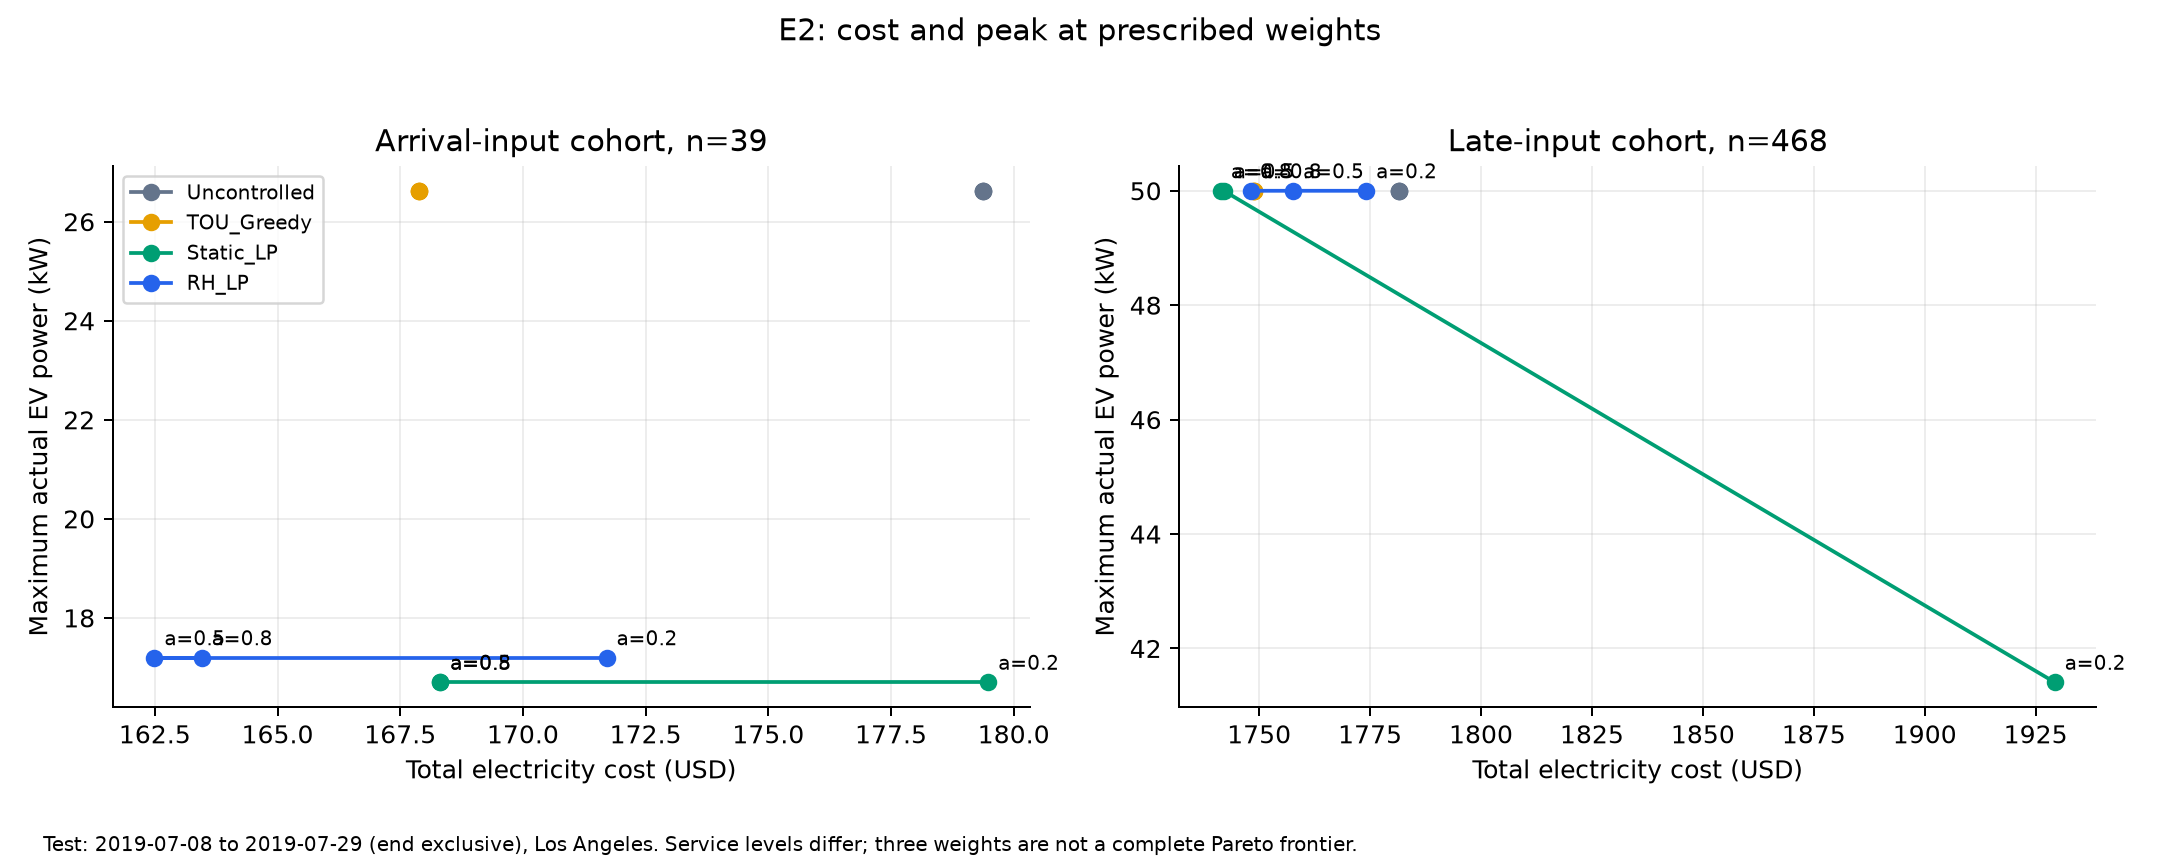

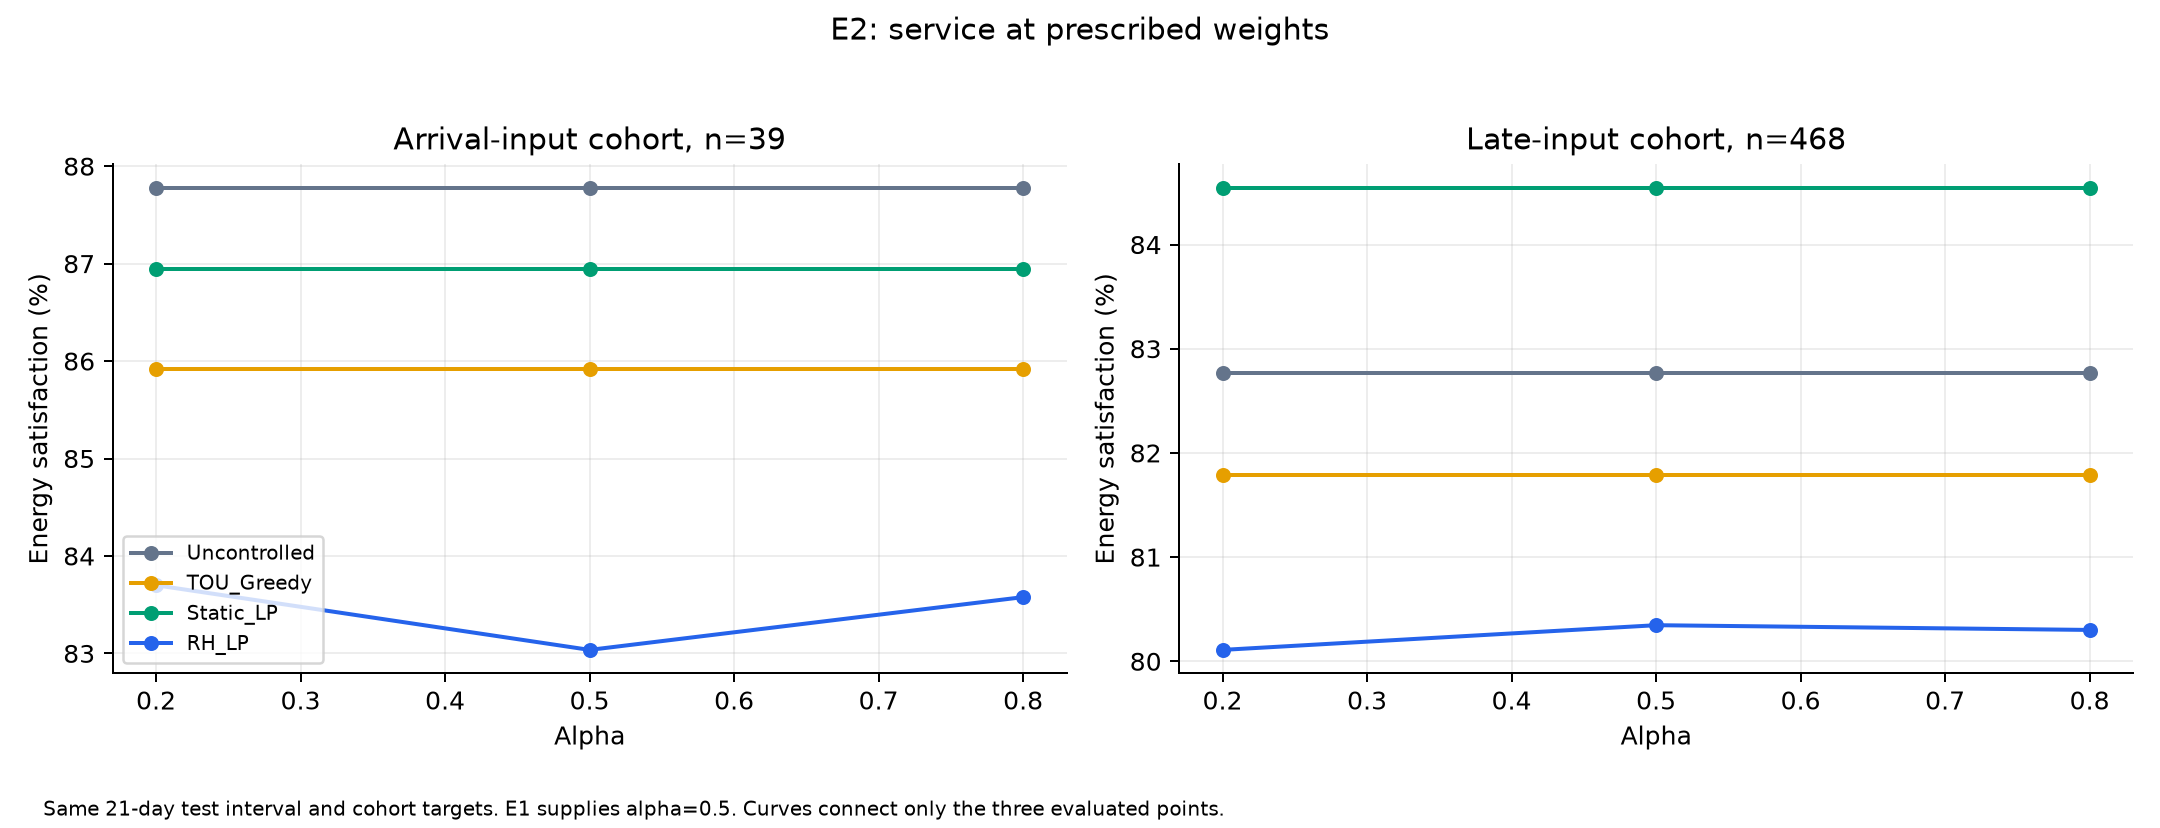

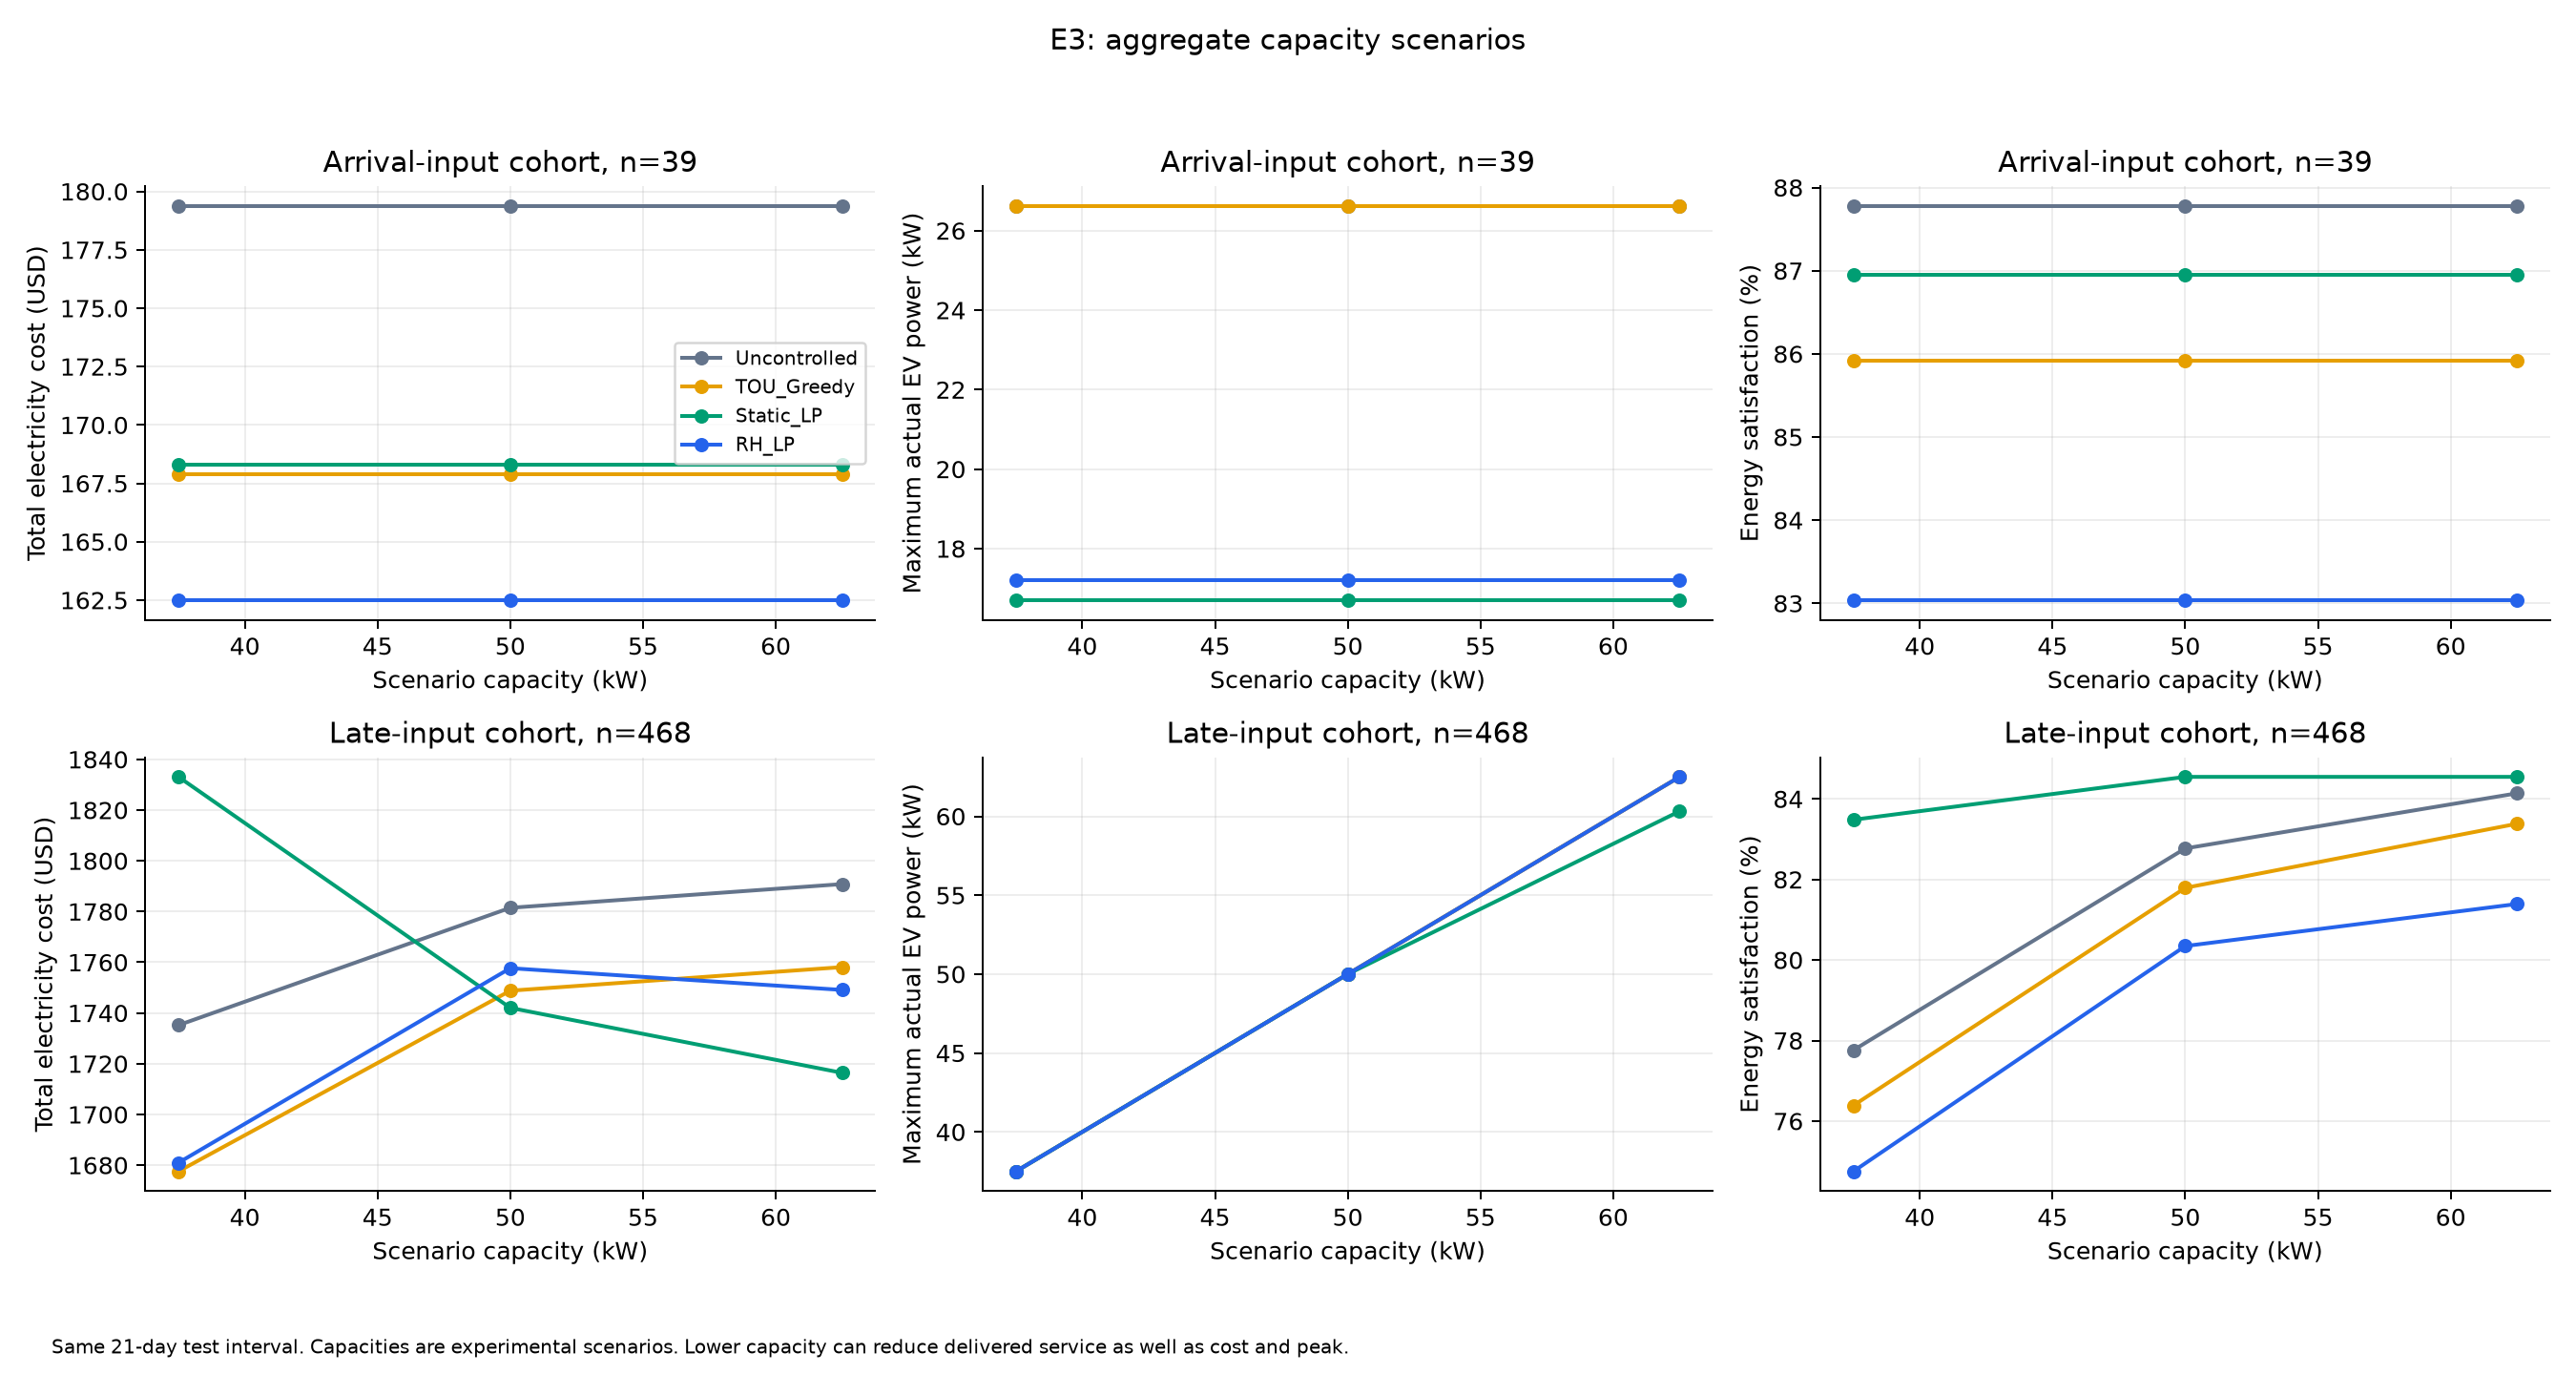

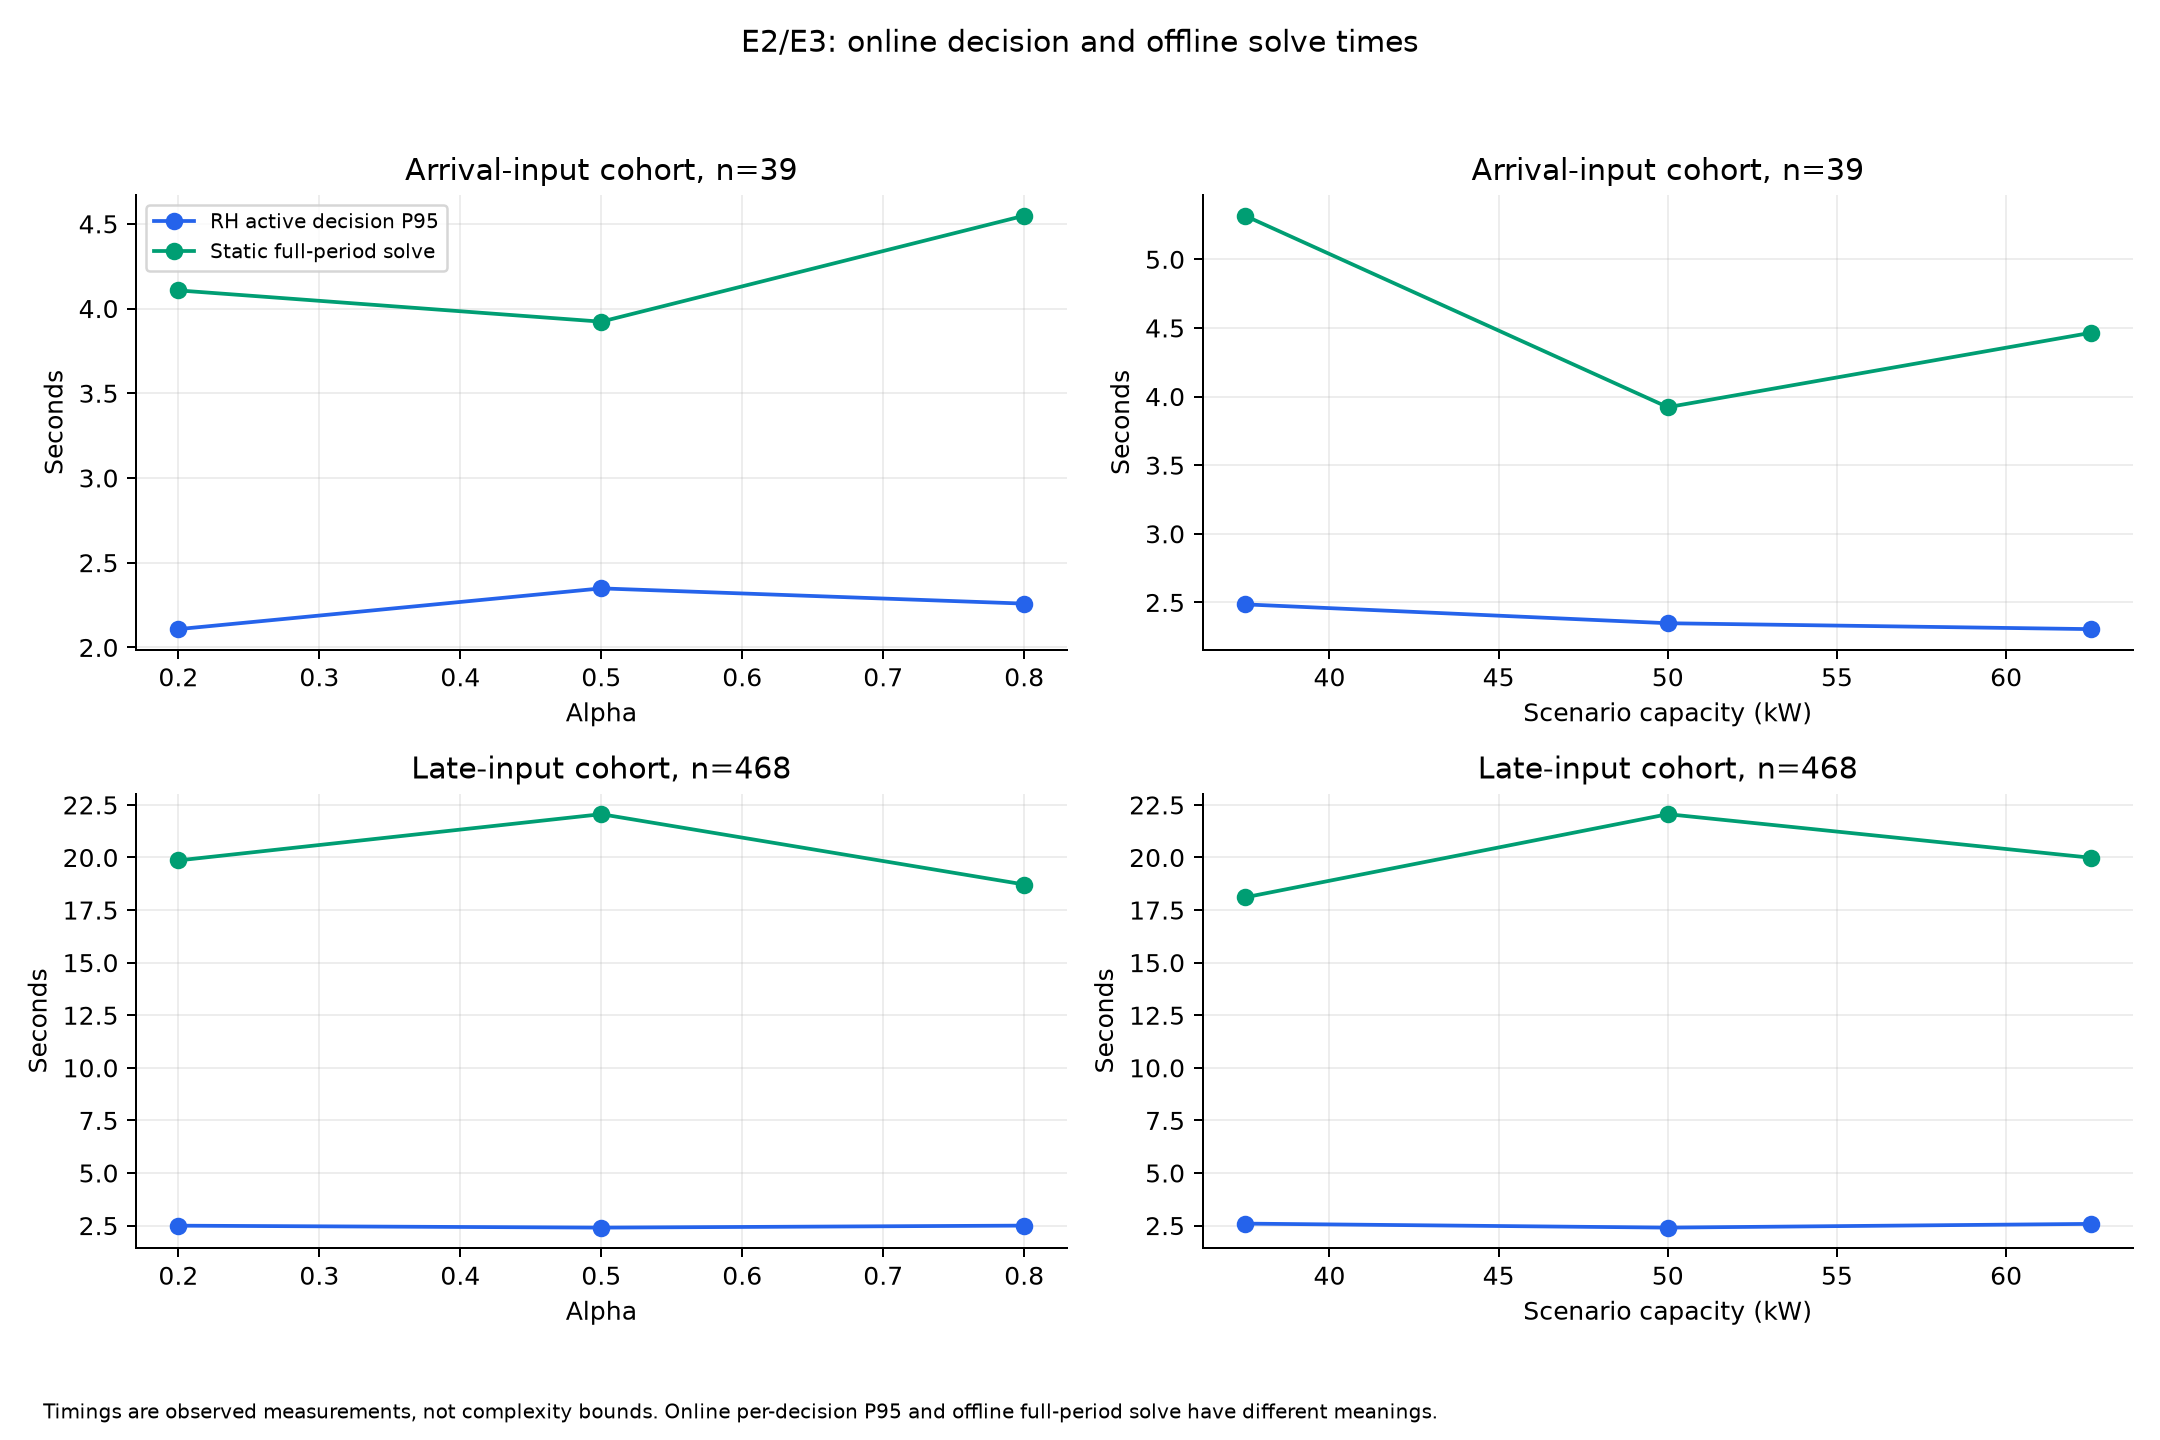


=== E4 所需环境与评价源码 ===

--- src/simulator.py ---
"""Aggregate event replay. Controllers receive view() copies, never this environment."""
import math
import pandas as pd

EPS = 1e-9

def timestamp(value):
    value = pd.Timestamp(value)
    if pd.isna(value) or value.tzinfo is None:
        raise ValueError(f"Expected timezone-aware timestamp: {value}")
    return value.tz_convert("UTC")

def number(value):
    value = float(value)
    if not math.isfinite(value) or value < 0:
        raise ValueError(f"Expected finite nonnegative number: {value}")
    return value

class AggregateEnvironment:
    def __init__(self, sessions, events, updates, start,
                 capacity_kw=50.0, pmax_kw=6.656, executor=None):
        self._executor = executor
        self.now = timestamp(start)
        if self.now != self.now.floor("15min"):
            raise ValueError("Start must be on the 15-minute UTC grid")
        self.capacity = number(capacity_kw)
        self.pmax = number(pmax_kw)
       

In [18]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import subprocess
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
BATCH = ROOT / "results/logs/stage4_sensitivity_20261112T124051538161Z"

summary_source = r'''
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1]
BATCH, OUT = Path(sys.argv[1]).resolve(), Path(sys.argv[2]).resolve()
OUT.mkdir(parents=True, exist_ok=False)

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

batch = json.loads(
    (BATCH / "batch_verification.json").read_text(encoding="utf-8")
)
assert batch["status"] == "passed"
assert batch["design_sha256"] == (
    "7079f7033ae1bfd38d2bbf4a76115cfc1fe002137b779d034b3c4af36d1f23e4"
)
assert digest(BATCH / "sensitivity_results.csv") == batch["results_sha256"]
assert batch["results_sha256"] == (
    "c732274df130a5660d4f94a5a3a996aaf8417a5a6fc0bebb316939a8a3126fee"
)

design_path = ROOT / "configs/sensitivity.yaml"
assert digest(design_path) == batch["design_sha256"]
design = yaml.safe_load(design_path.read_text(encoding="utf-8"))
for rel, expected in design["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel

expected_ids = {s["id"] for s in design["scenarios"]}
assert {s["scenario_id"] for s in batch["scenarios"]} == expected_ids

evidence_hashes = {}
folders = [ROOT / batch["reference_directory"]]
for scenario in batch["scenarios"]:
    assert scenario["status"] == "passed"
    assert scenario["returncode"] == 0
    assert scenario["check_count"] == 48
    folders.append(BATCH / scenario["scenario_id"])

for folder in folders:
    path = folder / "verification.json"
    verification = json.loads(path.read_text(encoding="utf-8"))
    assert verification["status"] == "passed"
    assert verification["requires_review"] is False
    for rel, expected in verification["source_and_input_sha256"].items():
        assert digest(ROOT / rel) == expected, rel
    for rel, expected in verification["output_artifact_sha256"].items():
        assert digest(folder / rel) == expected, rel
    evidence_hashes[str(path.relative_to(ROOT))] = digest(path)

table = pd.read_csv(BATCH / "sensitivity_results.csv")
assert len(table) == 40
assert not table.duplicated(["scenario_id", "cohort", "method"]).any()
assert table["fallback_count"].eq(0).all()
assert table["requires_review"].astype(str).str.lower().eq("false").all()

cohorts = ["main_at_arrival", "supplement_after_submission"]
methods = ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"]
labels = {
    "main_at_arrival": "Arrival-input cohort, n=39",
    "supplement_after_submission": "Late-input cohort, n=468",
}
colors = dict(zip(methods, ["#64748b", "#e69f00", "#009e73", "#2563eb"]))

weights = table[
    table["scenario_id"].isin(["E1_reference", "E2_alpha020", "E2_alpha080"])
].copy()
capacities = table[
    table["scenario_id"].isin(["E1_reference", "E3_cap0375", "E3_cap0625"])
].copy()
assert len(weights) == len(capacities) == 24

# 独立核对：规则方法不受 alpha 影响
for cohort in cohorts:
    for method in ["Uncontrolled", "TOU_Greedy"]:
        frame = weights[
            (weights["cohort"] == cohort) & (weights["method"] == method)
        ]
        for column in [
            "cost_USD", "delivered_kwh", "unmet_kwh",
            "energy_satisfaction", "max_peak_kW"
        ]:
            assert np.ptp(frame[column].to_numpy()) <= 1e-6, (
                cohort, method, column
            )

# 同一静态模型扩大容量不应增加第一层服务最优缺口。
# 此处比较统一执行后、已核验与静态计划一致的总缺口。
for cohort in cohorts:
    static = capacities[
        (capacities["cohort"] == cohort) &
        (capacities["method"] == "Static_LP")
    ].sort_values("capacity_kw")
    assert np.all(np.diff(static["unmet_kwh"].to_numpy()) <= 1e-5)

weights.to_csv(OUT / "weight_sensitivity.csv", index=False)
capacities.to_csv(OUT / "capacity_sensitivity.csv", index=False)

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.hashsalt": "ev-stage4-sensitivity-v1",
})

def save_figure(fig, name):
    fig.tight_layout(rect=(0, 0.06, 1, 0.95))
    fig.savefig(OUT / f"{name}.png", dpi=180)
    fig.savefig(OUT / f"{name}.svg", metadata={"Date": None})
    plt.close(fig)

def panel(ax, frame, cohort, x, y, ylabel):
    for method in methods:
        data = frame[
            (frame["cohort"] == cohort) & (frame["method"] == method)
        ].sort_values(x)
        values = data[y] * (100 if y == "energy_satisfaction" else 1)
        ax.plot(
            data[x], values, marker="o", label=method,
            color=colors[method], linewidth=1.6, markersize=5
        )
    ax.set_xlabel("Alpha" if x == "alpha" else "Scenario capacity (kW)")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.22)

# 1. 费用—峰值点图；标注 alpha，不将有限点解释成完整 Pareto 前沿
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, cohort in zip(axes, cohorts):
    for method in methods:
        data = weights[
            (weights["cohort"] == cohort) & (weights["method"] == method)
        ].sort_values("alpha")
        ax.plot(
            data["cost_USD"], data["max_peak_kW"],
            marker="o", color=colors[method], label=method
        )
        if method in ["Static_LP", "RH_LP"]:
            for row in data.to_dict("records"):
                ax.annotate(
                    f'a={row["alpha"]:g}',
                    (row["cost_USD"], row["max_peak_kW"]),
                    xytext=(4, 5), textcoords="offset points", fontsize=8
                )
    ax.set_title(labels[cohort])
    ax.set_xlabel("Total electricity cost (USD)")
    ax.set_ylabel("Maximum actual EV power (kW)")
    ax.grid(alpha=0.22)
axes[0].legend(fontsize=8)
fig.suptitle("E2: cost and peak at prescribed weights")
fig.text(
    0.02, 0.015,
    "Test: 2019-07-08 to 2019-07-29 (end exclusive), Los Angeles. "
    "Service levels differ; three weights are not a complete Pareto frontier.",
    fontsize=8
)
save_figure(fig, "weight_cost_peak")

# 2. 权重下的服务指标
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, cohort in zip(axes, cohorts):
    panel(ax, weights, cohort, "alpha",
          "energy_satisfaction", "Energy satisfaction (%)")
    ax.set_title(labels[cohort])
axes[0].legend(fontsize=8)
fig.suptitle("E2: service at prescribed weights")
fig.text(
    0.02, 0.015,
    "Same 21-day test interval and cohort targets. "
    "E1 supplies alpha=0.5. Curves connect only the three evaluated points.",
    fontsize=8
)
save_figure(fig, "weight_service")

# 3. 容量下同时报告费用、峰值、服务
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
columns = [
    ("cost_USD", "Total electricity cost (USD)"),
    ("max_peak_kW", "Maximum actual EV power (kW)"),
    ("energy_satisfaction", "Energy satisfaction (%)"),
]
for row_index, cohort in enumerate(cohorts):
    for column_index, (metric, ylabel) in enumerate(columns):
        ax = axes[row_index, column_index]
        panel(ax, capacities, cohort, "capacity_kw", metric, ylabel)
        ax.set_title(labels[cohort])
axes[0, 0].legend(fontsize=8)
fig.suptitle("E3: aggregate capacity scenarios")
fig.text(
    0.02, 0.015,
    "Same 21-day test interval. Capacities are experimental scenarios. "
    "Lower capacity can reduce delivered service as well as cost and peak.",
    fontsize=8
)
save_figure(fig, "capacity_service_cost_peak")

# 4. 计算时间：在线 P95 与离线全期求解分别标记
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row_index, cohort in enumerate(cohorts):
    for column_index, (frame, x) in enumerate([
        (weights, "alpha"), (capacities, "capacity_kw")
    ]):
        ax = axes[row_index, column_index]
        for method, field, label in [
            ("RH_LP", "active_P95_seconds", "RH active decision P95"),
            ("Static_LP", "offline_solve_wall_seconds", "Static full-period solve"),
        ]:
            data = frame[
                (frame["cohort"] == cohort) & (frame["method"] == method)
            ].sort_values(x)
            ax.plot(data[x], data[field], marker="o",
                    label=label, color=colors[method])
        ax.set_title(labels[cohort])
        ax.set_xlabel("Alpha" if x == "alpha" else "Scenario capacity (kW)")
        ax.set_ylabel("Seconds")
        ax.grid(alpha=0.22)
axes[0, 0].legend(fontsize=8)
fig.suptitle("E2/E3: online decision and offline solve times")
fig.text(
    0.02, 0.015,
    "Timings are observed measurements, not complexity bounds. "
    "Online per-decision P95 and offline full-period solve have different meanings.",
    fontsize=8
)
save_figure(fig, "computation_time")

notes = [
    "# E2/E3 汇总与验收",
    "",
    "预设权重与容量实验运行及汇总检查通过；不代表阶段四全部完成。",
    f"原始证据目录：`{BATCH.relative_to(ROOT)}`",
    "测试期：洛杉矶当地 [2019-07-08, 2019-07-29)，21 个自然日。",
    "两个队列分别为 39／468 条会话。",
    "4 个新增情景各 48/48 项检查通过；共享基准点复用 E1。",
    "含基准共 40 行结果；按实验轴展开的两张表各 24 行，不能视为独立重复实验。",
    "",
    "## 解释边界",
    "",
    "- RH 的费用、缺口及峰值不随权重简单单调变化；需联合解释服务指标。",
    "- 费用—峰值仅有三个预设权重点，不宣称完整 Pareto 前沿。",
    "- 主队列在本次容量网格下结果不变，不推断所有负荷下均对容量不敏感。",
    "- 补充队列容量增加时服务改善；较低容量下低费用不能直接称为节费。",
    "- Static LP 是完整信息离线参考，在线与离线耗时口径分开标示。",
    "- 未根据测试结果修改 E1 主参数，未开展新的参数搜索。",
    "- 控制间隔、窗口与电价扩展本次未运行；E4 信息误差实验仍待实施。",
]
(OUT / "acceptance.md").write_text(
    "\n".join(notes) + "\n", encoding="utf-8"
)
artifacts = {
    p.name: digest(p) for p in sorted(OUT.iterdir()) if p.is_file()
}
result = {
    "status": "passed",
    "scope": "required E2/E3 grid summary; not whole stage 4",
    "scenario_count_new": 4,
    "comparison_rows_including_reference": 40,
    "checks": [
        "frozen design and source hashes",
        "all five run evidence and trajectory hashes",
        "40 unique method/cohort/scenario combinations",
        "zero fallback and no review flags",
        "rule baselines invariant to alpha",
        "Static LP shortfall nonincreasing with capacity",
    ],
    "source_evidence_sha256": evidence_hashes,
    "summary_script_sha256": digest(Path(__file__)),
    "output_artifact_sha256": artifacts,
}
(OUT / "verification.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(result, ensure_ascii=False, indent=2))
print("Summary directory:", OUT)
'''

ast.parse(summary_source)
script = ROOT / "experiments/summarize_sensitivity.py"
if script.exists():
    assert script.read_text(encoding="utf-8") == summary_source, (
        "汇总脚本已存在且内容不同，未覆盖。"
    )
else:
    script.write_text(summary_source, encoding="utf-8")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
SUMMARY_OUT = BATCH / f"summary_{stamp}"
completed = subprocess.run(
    [sys.executable, "-u", str(script), str(BATCH), str(SUMMARY_OUT)],
    cwd=ROOT, capture_output=True, text=True,
)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
assert completed.returncode == 0, "汇总未通过，请回传完整输出。"

# 展示四张图，便于核对是否清晰、完整
from IPython.display import display, Image
for name in [
    "weight_cost_peak",
    "weight_service",
    "capacity_service_cost_peak",
    "computation_time",
]:
    display(Image(filename=str(SUMMARY_OUT / f"{name}.png")))

# E4 实现需要核对环境如何处理请求、剩余需求与中途离站
print("\n=== E4 所需环境与评价源码 ===")
for rel in ["src/simulator.py", "src/metrics.py"]:
    path = ROOT / rel
    print(f"\n--- {rel} ---")
    print(path.read_text(encoding="utf-8-sig"))

path = ROOT / "src/baselines.py"
text = path.read_text(encoding="utf-8-sig")
tree = ast.parse(text)
print("\n--- src/baselines.py：状态与规则接口 ---")
for node in tree.body:
    if isinstance(node, ast.FunctionDef) and node.name in {
        "_state", "uncontrolled", "tou_greedy"
    }:
        print(ast.get_source_segment(text, node))

In [19]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import importlib.util
import json
import sys
import pandas as pd

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
sys.path.insert(0, str(ROOT))

module_source = r'''
"""Controlled synthetic errors; original evaluation targets remain separate."""
import hashlib
import math
import pandas as pd

def factor_for(session_id, amplitude, seed):
    amplitude = float(amplitude)
    if not math.isfinite(amplitude) or not 0 <= amplitude < 1:
        raise ValueError("Amplitude must be finite and in [0, 1)")
    if int(seed) != seed or seed < 0:
        raise ValueError("Seed must be a nonnegative integer")
    payload = f"ev-e4-v1|{int(seed)}|{session_id}".encode("utf-8")
    sign = 1 if hashlib.sha256(payload).digest()[0] & 1 else -1
    return 1.0 + sign * amplitude

def perturb_requests(sessions, releases, amplitude, seed):
    """Copy operational inputs; never alter their release times."""
    selected = sessions.copy(deep=True)
    updates = releases.copy(deep=True)
    factors = {
        str(sid): factor_for(str(sid), amplitude, seed)
        for sid in sessions["sessionID"]
    }
    if float(amplitude) == 0:
        return selected, updates, factors

    main = selected["cohort"].eq("main_at_arrival")
    selected.loc[main, "initial_kWhRequested"] = (
        pd.to_numeric(selected.loc[main, "initial_kWhRequested"], errors="raise")
        * selected.loc[main, "sessionID"].astype(str).map(factors)
    )
    supplemental_ids = set(
        selected.loc[~main, "sessionID"].astype(str)
    )
    valid = updates["valid"].astype(str).str.strip().str.lower().isin(
        ["true", "1", "1.0"]
    )
    mask = updates["sessionID"].astype(str).isin(supplemental_ids) & valid
    updates.loc[mask, "kWhRequested"] = (
        pd.to_numeric(updates.loc[mask, "kWhRequested"], errors="raise")
        * updates.loc[mask, "sessionID"].astype(str).map(factors)
    )
    return selected, updates, factors

def advance_departures(events, minutes):
    """Change only environment departure events; retain every session."""
    minutes = float(minutes)
    if not math.isfinite(minutes) or minutes < 0:
        raise ValueError("Advance must be finite and nonnegative")
    result = events.copy(deep=True)
    parsed = pd.to_datetime(
        events["event_time"], utc=True, format="ISO8601", errors="raise"
    )
    frame = events.copy(deep=True)
    frame["sessionID"] = frame["sessionID"].astype(str)
    frame["event_time"] = parsed
    if frame.duplicated(["sessionID", "event_type"]).any():
        raise ValueError("Duplicate boundary events")
    bounds = frame.pivot(
        index="sessionID", columns="event_type", values="event_time"
    )
    if not {"arrival", "departure"}.issubset(bounds.columns):
        raise ValueError("Missing boundary event")
    if bounds[["arrival", "departure"]].isna().any().any():
        raise ValueError("Incomplete session boundaries")

    shifted, audit = {}, []
    for sid, row in bounds.iterrows():
        arrival, departure = row["arrival"], row["departure"]
        if not departure > arrival:
            raise ValueError("Invalid original duration")
        proposed = departure - pd.Timedelta(minutes=minutes)
        new_departure = max(proposed, arrival + pd.Timedelta(nanoseconds=1))
        shifted[sid] = new_departure
        audit.append({
            "sessionID": sid,
            "original_departure": departure,
            "scenario_departure": new_departure,
            "requested_advance_minutes": minutes,
            "effective_advance_minutes":
                (departure - new_departure).value / 60_000_000_000,
            "clipped_to_positive_duration": proposed <= arrival,
        })
    if minutes > 0:
        result["event_time"] = parsed
        mask = result["event_type"].eq("departure")
        result.loc[mask, "event_time"] = (
            result.loc[mask, "sessionID"].astype(str).map(shifted)
        )
    return result, pd.DataFrame(audit)
'''

ast.parse(module_source)
module_path = ROOT / "experiments/robustness_protocol.py"
if module_path.exists():
    assert module_path.read_text(encoding="utf-8") == module_source, (
        "已有同名模块内容不同，未覆盖。"
    )
else:
    module_path.write_text(module_source, encoding="utf-8")

spec = importlib.util.spec_from_file_location("ev_robustness_protocol", module_path)
protocol = importlib.util.module_from_spec(spec)
spec.loader.exec_module(protocol)

from src.simulator import AggregateEnvironment
from src.metrics import evaluate_run

checks = []
def check(name, condition):
    assert condition, name
    checks.append(name)

t = pd.Timestamp("2020-01-01T00:00:00Z")
sessions = pd.DataFrame([
    {
        "sessionID": "M", "stationID": "A", "cohort": "main_at_arrival",
        "connectionTime": t, "initial_kWhRequested": 1.0,
        "initial_requestedDeparture": t + pd.Timedelta(hours=1),
    },
    {
        "sessionID": "S", "stationID": "B",
        "cohort": "supplement_after_submission",
        "connectionTime": t, "initial_kWhRequested": None,
        "initial_requestedDeparture": None,
    },
])
events = pd.DataFrame([
    {"sessionID": sid, "event_type": kind, "event_time": when}
    for sid in ["M", "S"]
    for kind, when in [
        ("arrival", t), ("departure", t + pd.Timedelta(hours=1))
    ]
])
releases = pd.DataFrame([{
    "sessionID": "S", "valid": True, "input_order": 0,
    "modifiedAt": t + pd.Timedelta(minutes=45),
    "kWhRequested": 2.0,
    "requestedDeparture": t + pd.Timedelta(hours=1),
}])
original_sessions = sessions.copy(deep=True)
original_releases = releases.copy(deep=True)
original_events = events.copy(deep=True)

zero_s, zero_u, _ = protocol.perturb_requests(sessions, releases, 0, 0)
check("zero-error session inputs exactly unchanged", zero_s.equals(sessions))
check("zero-error release inputs exactly unchanged", zero_u.equals(releases))
zero_e, _ = protocol.advance_departures(events, 0)
check("zero-advance events exactly unchanged", zero_e.equals(events))

seed = next(
    n for n in range(100)
    if protocol.factor_for("M", 0.2, n) > 1
)
runtime_s, runtime_u, factors = protocol.perturb_requests(
    sessions, releases, 0.2, seed
)
check("positive error scales visible main request",
      abs(runtime_s.iloc[0]["initial_kWhRequested"] - 1.2) < 1e-12)
check("release time unchanged",
      runtime_u["modifiedAt"].equals(releases["modifiedAt"]))
check("expected departure unchanged",
      runtime_u["requestedDeparture"].equals(releases["requestedDeparture"]))
check("supplement update uses its fixed session factor",
      abs(runtime_u.iloc[0]["kWhRequested"] - 2 * factors["S"]) < 1e-12)

a_s, a_u, a_f = protocol.perturb_requests(sessions, releases, 0.2, seed)
check("paired methods receive identical perturbed inputs",
      a_s.equals(runtime_s) and a_u.equals(runtime_u) and a_f == factors)

shifted, departure_audit = protocol.advance_departures(events, 30)
check("no session or event removed", len(shifted) == len(events))
check("all departures advanced by 30 minutes",
      departure_audit["effective_advance_minutes"].eq(30).all())

env = AggregateEnvironment(
    runtime_s, shifted, runtime_u, start=t, capacity_kw=50, pmax_kw=6.656
)
visible = {v["id"]: v for v in env.view()["vehicles"]}
check("future supplemental request is not visible",
      visible["S"]["target_kwh"] is None)

# 此处操作目标为估计值；原始评价目标在下面单独提供
env.step({"M": 4.8})
for _ in range(3):
    env.step({})
check("late input cannot reactivate departed session",
      not env.view()["vehicles"] and len(env.completed) == 2)
check("post-departure input is not released",
      not env.update_audit)

station_rows, vehicle_rows = [], []
for segment in env.ledger:
    station_rows.append({
        "start": segment["start"], "end": segment["end"],
        "total_kw": segment["total_kw"],
        "energy_kwh": sum(segment["energy_kwh"].values()),
    })
    for sid, energy in segment["energy_kwh"].items():
        vehicle_rows.append({
            "sessionID": sid, "start": segment["start"],
            "end": segment["end"],
            "actual_kw": segment["power_kw"][sid], "energy_kwh": energy,
        })

evaluation = pd.DataFrame([
    {
        "sessionID": sid, "connectionTime": t,
        "disconnectTime": t + pd.Timedelta(minutes=30),
        "evaluation_target_kwh": target, "pmax_kw": 6.656,
    }
    for sid, target in [("M", 1.0), ("S", 2.0)]
])
summary, _, _ = evaluate_run(
    pd.DataFrame(station_rows), pd.DataFrame(vehicle_rows),
    evaluation, t, t + pd.Timedelta(hours=1),
    lambda _: 0.2, capacity_kw=50,
)
check("overestimate excess reported separately",
      abs(summary["excess_kwh"] - 0.2) < 1e-5)
check("excess does not offset another session's shortfall",
      abs(summary["unmet_kwh"] - 2.0) < 1e-5)
check("satisfaction uses per-session capped delivery",
      abs(summary["energy_satisfaction"] - 1 / 3) < 1e-5)
check("synthetic physical and energy audits",
      summary["max_power_violation_kW"] <= 1e-6
      and summary["max_energy_residual_kwh"] <= 1e-5
      and summary["connection_violation_segments"] == 0)

short_events = events[events["sessionID"].eq("M")].copy()
short_events.loc[
    short_events["event_type"].eq("departure"), "event_time"
] = t + pd.Timedelta(minutes=5)
_, short_audit = protocol.advance_departures(short_events, 30)
check("short connection retained with explicit clipping",
      short_audit.iloc[0]["scenario_departure"] > t
      and bool(short_audit.iloc[0]["clipped_to_positive_duration"]))

check("source inputs never mutated",
      sessions.equals(original_sessions)
      and releases.equals(original_releases)
      and events.equals(original_events))

# 对正式输入做零误差一致性检查，不运行调度
DATA = ROOT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"
real_sessions = pd.read_csv(DATA / "sessions_with_split.csv",
                            dtype={"sessionID": str})
real_sessions = real_sessions[real_sessions["split"].eq("test")].copy()
real_releases = pd.read_csv(DATA / "input_release_events.csv",
                            dtype={"sessionID": str})
real_releases = real_releases[
    real_releases["sessionID"].isin(real_sessions["sessionID"])
].copy()
zs, zu, _ = protocol.perturb_requests(real_sessions, real_releases, 0, 0)
check("full-test zero-error inputs exactly unchanged",
      zs.equals(real_sessions) and zu.equals(real_releases))
check("full-test cohort retained", len(real_sessions) == 507)

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
PROTOCOL_OUT = ROOT / "results/logs" / f"stage4_robustness_protocol_{stamp}"
PROTOCOL_OUT.mkdir(parents=True, exist_ok=False)

result = {
    "status": "passed",
    "scope": "E4 input transformation and evaluator synthetic checks only",
    "check_count": len(checks),
    "checks": checks,
    "module_sha256": hashlib.sha256(module_path.read_bytes()).hexdigest(),
    "long_experiments_started": False,
}
(PROTOCOL_OUT / "verification.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
draft = {
    "status": "draft_not_frozen",
    "error_type": "controlled_synthetic_request_estimation_error",
    "random_mechanism": "per-session fixed Rademacher sign from SHA-256",
    "amplitudes": [0.1, 0.2],
    "seeds": list(range(10)),
    "sign_shared_between_amplitudes": True,
    "factor_shared_across_session_updates": True,
    "online_methods": ["Uncontrolled", "TOU_Greedy", "RH_LP"],
    "early_departure_minutes": [15, 30],
    "early_departure_policy": "clip at arrival plus 1 ns; retain and audit",
    "evaluation_target_policy": "retain E1 evaluation targets",
    "zero_error_reference": "E1, subject to runner-level equivalence audit",
    "positive_error_excess": "report separately; do not offset unmet demand",
    "new_long_scenarios": 22,
}
(PROTOCOL_OUT / "design_draft.json").write_text(
    json.dumps(draft, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(result, ensure_ascii=False, indent=2))
print("证据目录：", PROTOCOL_OUT)

# 补取最近一次敏感性汇总验收记录
BATCH = ROOT / "results/logs/stage4_sensitivity_20261112T124051538161Z"
summaries = sorted(BATCH.glob("summary_*/verification.json"))
if summaries:
    path = summaries[-1]
    print("\n=== 敏感性汇总验收记录 ===")
    print("路径：", path)
    print(path.read_text(encoding="utf-8"))
else:
    print("\n未找到敏感性汇总验收记录，请回传此前汇总单元输出。")

{
  "status": "passed",
  "scope": "E4 input transformation and evaluator synthetic checks only",
  "check_count": 21,
  "checks": [
    "zero-error session inputs exactly unchanged",
    "zero-error release inputs exactly unchanged",
    "zero-advance events exactly unchanged",
    "positive error scales visible main request",
    "release time unchanged",
    "expected departure unchanged",
    "supplement update uses its fixed session factor",
    "paired methods receive identical perturbed inputs",
    "no session or event removed",
    "all departures advanced by 30 minutes",
    "future supplemental request is not visible",
    "late input cannot reactivate departed session",
    "post-departure input is not released",
    "overestimate excess reported separately",
    "excess does not offset another session's shortfall",
    "satisfaction uses per-session capped delivery",
    "synthetic physical and energy audits",
    "short connection retained with explicit clipping",
    "so

{
  "status": "passed",
  "scope": "required E2/E3 grid summary; not whole stage 4",
  "scenario_count_new": 4,
  "comparison_rows_including_reference": 40,
  "checks": [
    "frozen design and source hashes",
    "all five run evidence and trajectory hashes",
    "40 unique method/cohort/scenario combinations",
    "zero fallback and no review flags",
    "rule baselines invariant to alpha",
    "Static LP shortfall nonincreasing with capacity"
  ],
  "source_evidence_sha256": {
    "results/logs/stage4_main_test_20261112T102930606571Z/verification.json": "dfe2f57572a60254326cbd25d020f33e27efede87908b91b43ad19bc2ea052f7",
    "results/logs/stage4_sensitivity_20261112T124051538161Z/E2_alpha020/verification.json": "4adb5a5f65d02b8c0deadf4d96ad49e55350b7d57361cd5dd2f4ab44c61ca54a",
    "results/logs/stage4_sensitivity_20261112T124051538161Z/E2_alpha080/verification.json": "aab83b183746bd2d7620d6bec5d153c7b2b775fe902957b267e779cf372a6475",
    "results/logs/stage4_sensitivity_20261112T124

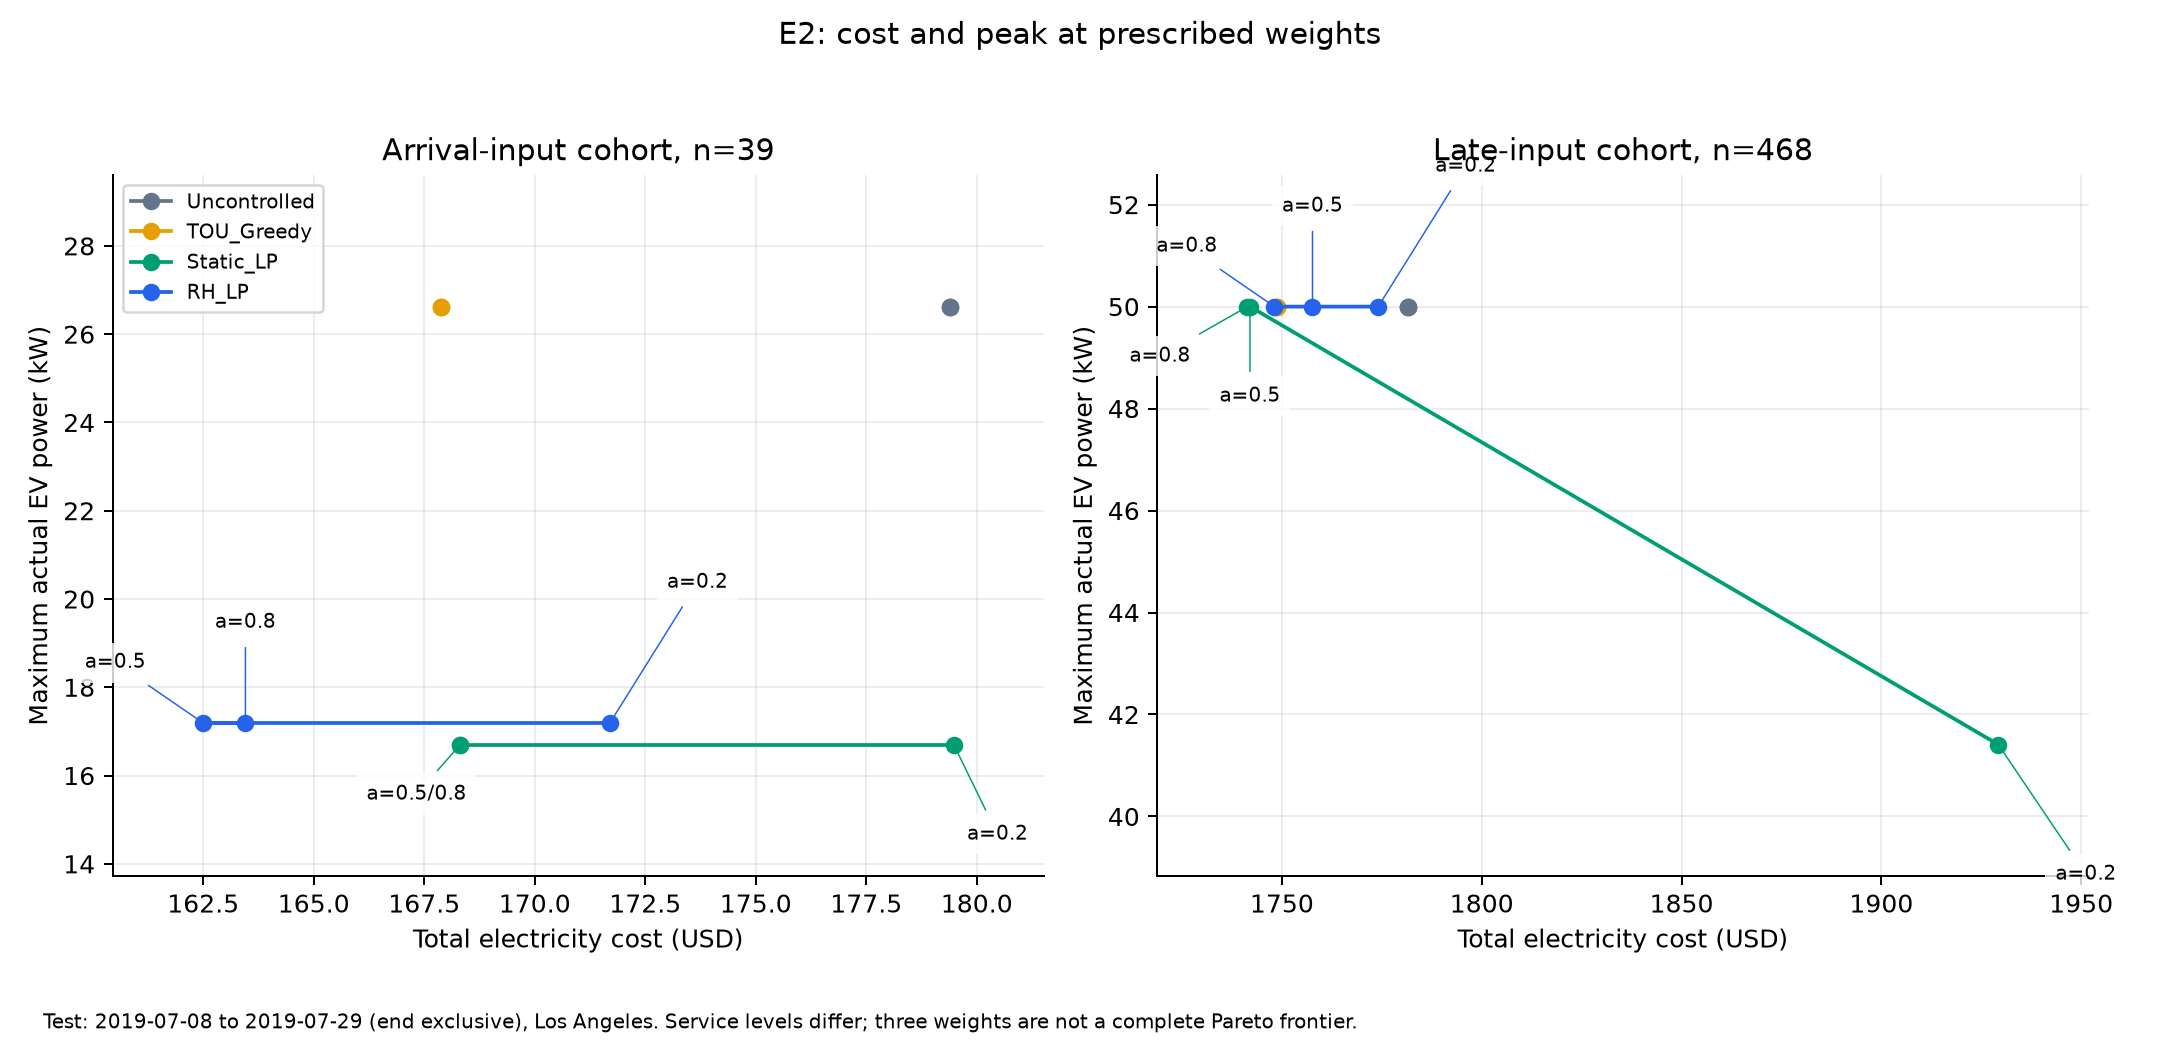

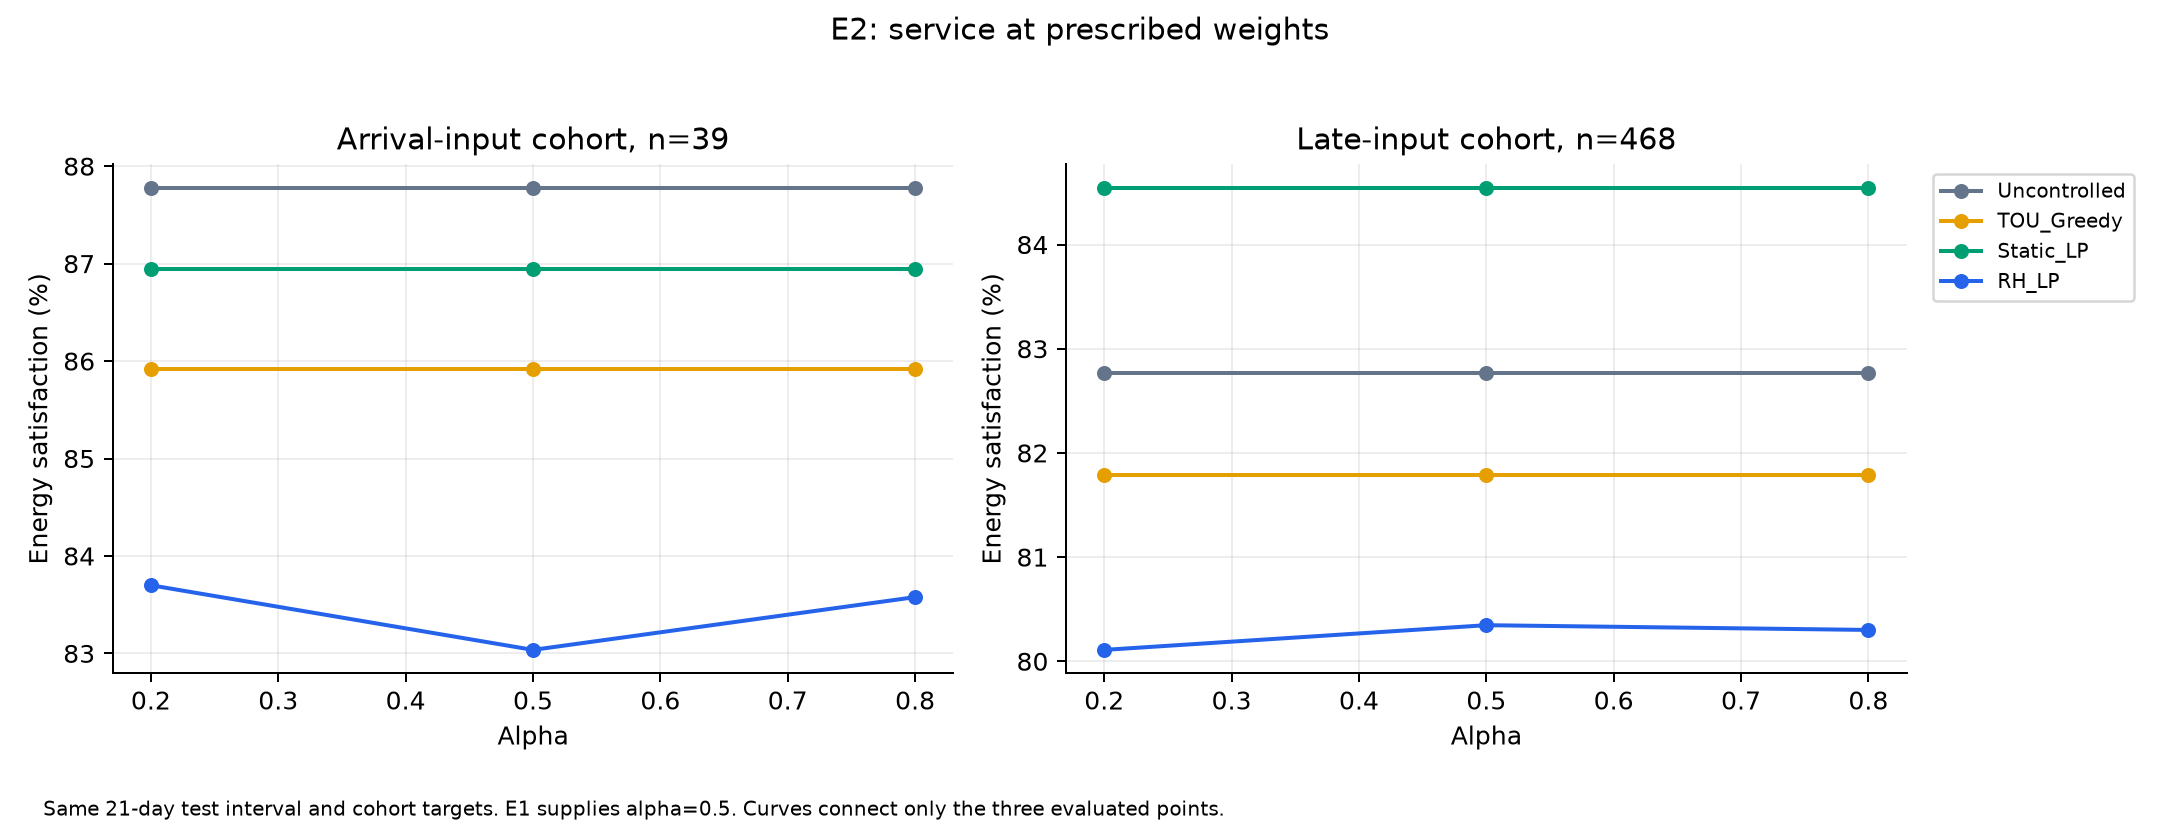

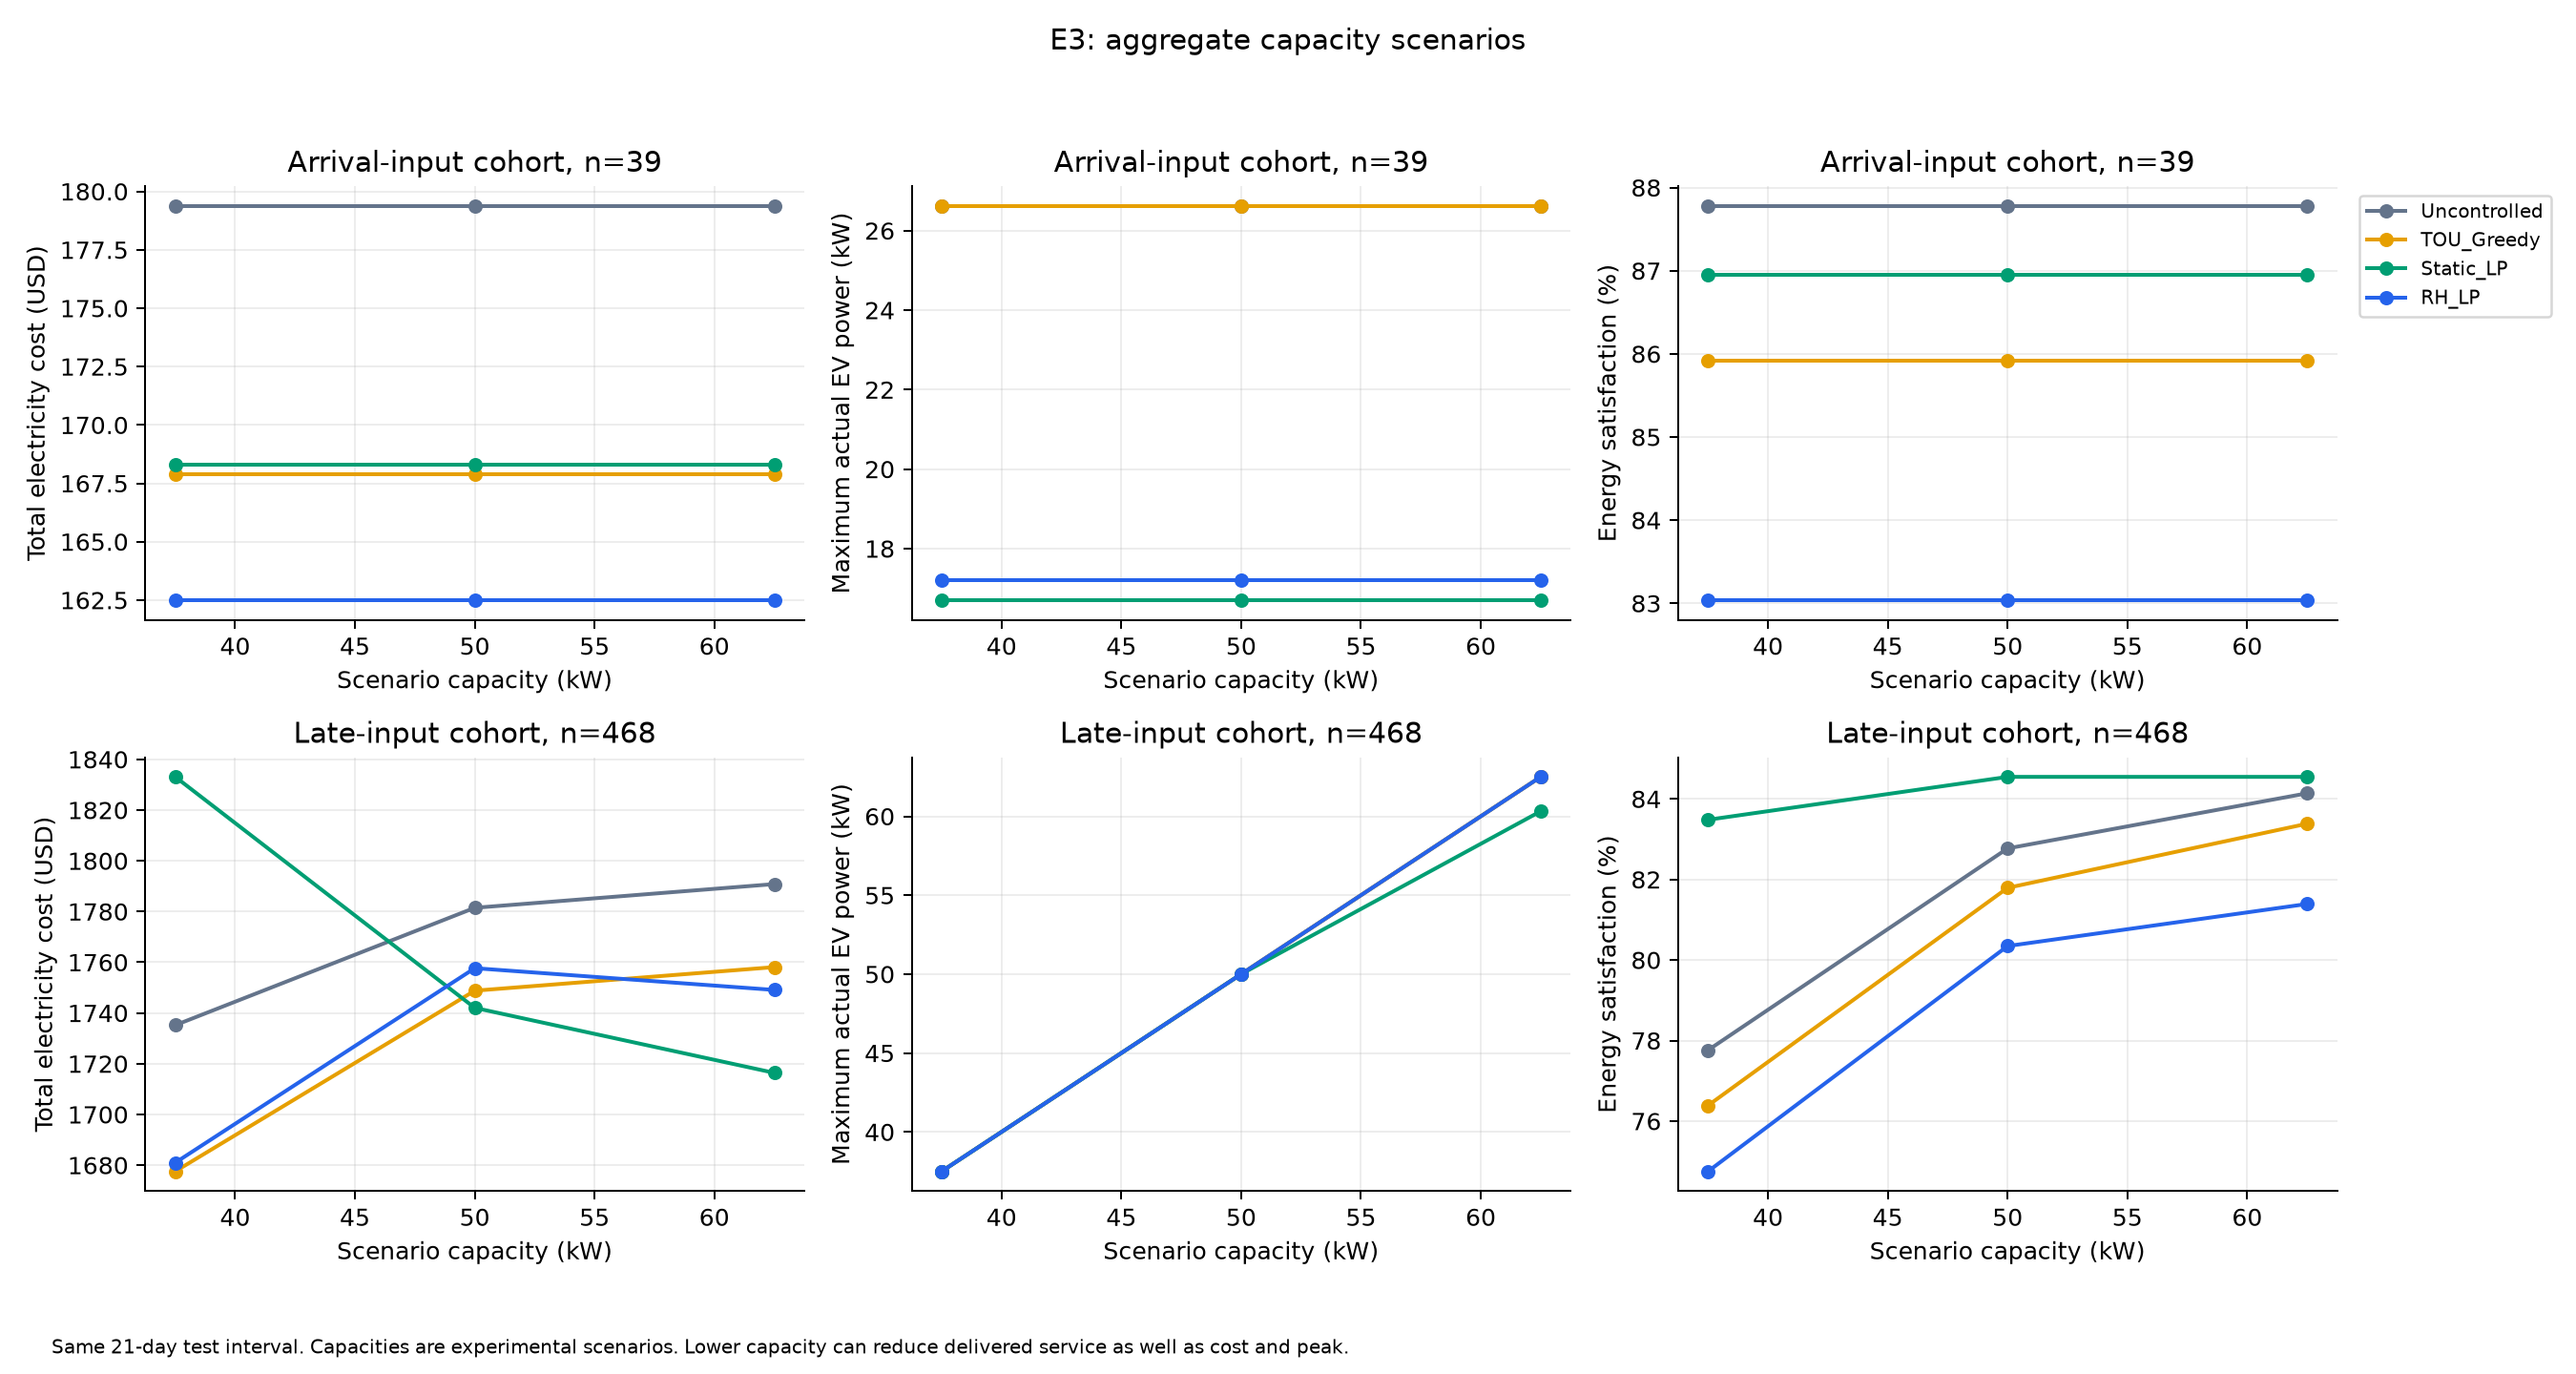

In [20]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import subprocess
import sys
from IPython.display import display, Image

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
BATCH = ROOT / "results/logs/stage4_sensitivity_20261112T124051538161Z"
old_script = ROOT / "experiments/summarize_sensitivity.py"
assert hashlib.sha256(old_script.read_bytes()).hexdigest() == (
    "b18f56c5da116a67fa70b45beeff6ee82149db1cc4ecc7fbec006993b5dd6cf8"
)
text = old_script.read_text(encoding="utf-8")

# 合并重合点的标签；不同位置采用错开的标签与引线
a = text.index('            for row in data.to_dict("records"):')
b = text.index('    ax.set_title(labels[cohort])', a)
text = text[:a] + '''            groups = {}
            for row in data.to_dict("records"):
                key = (round(row["cost_USD"], 6), round(row["max_peak_kW"], 6))
                groups.setdefault(key, []).append(row["alpha"])
            for index, ((cost, peak), alphas) in enumerate(sorted(groups.items())):
                label = "a=" + "/".join(f"{value:g}" for value in alphas)
                direction = 1 if method == "RH_LP" else -1
                dx = (index - (len(groups) - 1) / 2) * 35
                dy = direction * (22 + 16 * index)
                ax.annotate(
                    label, (cost, peak), xytext=(dx, dy),
                    textcoords="offset points", ha="center", fontsize=8,
                    arrowprops={"arrowstyle": "-", "lw": 0.6,
                                "color": colors[method]},
                    bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8},
                )
    ax.margins(x=0.12, y=0.30)
''' + text[b:]

text = text.replace(
    'figsize=(12, 4.8)', 'figsize=(12, 5.8)', 1
)
a = text.index("# 2. 权重下的服务指标")
b = text.index("# 3. 容量下", a)
section = text[a:b]
assert section.count("axes[0].legend(fontsize=8)") == 1
section = section.replace(
    "axes[0].legend(fontsize=8)",
    'axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))'
)
text = text[:a] + section + text[b:]

# 容量图图例也移出曲线区域
assert text.count("axes[0, 0].legend(fontsize=8)") == 2
text = text.replace(
    "axes[0, 0].legend(fontsize=8)",
    'axes[0, 2].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))',
    1
)
ast.parse(text)
new_script = ROOT / "experiments/summarize_sensitivity_v2.py"
if new_script.exists():
    assert new_script.read_text(encoding="utf-8") == text
else:
    new_script.write_text(text, encoding="utf-8")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
DISPLAY_OUT = BATCH / f"summary_{stamp}_displayfix"
process = subprocess.run(
    [sys.executable, "-u", str(new_script), str(BATCH), str(DISPLAY_OUT)],
    cwd=ROOT, capture_output=True, text=True
)
print(process.stdout)
if process.stderr:
    print(process.stderr)
assert process.returncode == 0, "图表修正未完成，请回传日志。"

for name in ["weight_cost_peak", "weight_service", "capacity_service_cost_peak"]:
    display(Image(filename=str(DISPLAY_OUT / f"{name}.png")))

In [21]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import json
import subprocess
import sys
import yaml

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
E1 = ROOT / "results/logs/stage4_main_test_20261112T102930606571Z"
PROTO = ROOT / "results/logs/stage4_robustness_protocol_20261113T083943861871Z"

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def save_new(path, text):
    if path.exists():
        assert path.read_text(encoding="utf-8") == text, (
            f"已有文件内容不同，未覆盖：{path}"
        )
    else:
        path.write_text(text, encoding="utf-8")

protocol_module = ROOT / "experiments/robustness_protocol.py"
assert digest(protocol_module) == (
    "387507fbc0464c045b48233284cbb70bdaf60d12f0eae00b2f7a3676e0fe61c4"
)
short_check = json.loads(
    (PROTO / "verification.json").read_text(encoding="utf-8")
)
assert short_check["status"] == "passed"
assert short_check["check_count"] == 21

e1_verification = json.loads(
    (E1 / "verification.json").read_text(encoding="utf-8")
)
assert e1_verification["status"] == "passed"
assert not e1_verification["requires_review"]
for rel, expected in e1_verification["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel
for rel, expected in e1_verification["output_artifact_sha256"].items():
    assert digest(E1 / rel) == expected, rel

# ---------- 生成独立 E4 入口 ----------
original = ROOT / "experiments/run_test_evaluation.py"
assert digest(original) == (
    "0f55c322fae5e58469438145b5bbaa491a9c0991737215265edf5bacedee167d"
)
source = original.read_text(encoding="utf-8")
source = "import importlib.util\n" + source

def replace_once(old, new):
    global source
    assert source.count(old) == 1, f"替换位置不唯一：{old[:100]!r}"
    source = source.replace(old, new, 1)

replace_once(
    "args = parser.parse_args()",
    '''parser.add_argument("--protocol-config", required=True)
parser.add_argument("--protocol-sha256", required=True)
parser.add_argument("--scenario-id", required=True)
parser.add_argument("--smoke", action="store_true")
parser.add_argument("--bypass-transform", action="store_true")
args = parser.parse_args()'''
)

gate = '''
protocol_path = Path(args.protocol_config).resolve()
assert digest(protocol_path) == args.protocol_sha256
protocol_config = yaml.safe_load(protocol_path.read_text(encoding="utf-8"))
assert protocol_config["status"] == (
    "validation_only" if args.smoke else "frozen"
)
assert protocol_config["e1_config_sha256"] == args.frozen_config_sha256
matches = [
    item for item in protocol_config["scenarios"]
    if item["id"] == args.scenario_id
]
assert len(matches) == 1
scenario = matches[0]
if args.bypass_transform:
    assert args.smoke
    assert scenario["amplitude"] == 0
    assert scenario["advance_minutes"] == 0
for rel, expected in protocol_config["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel
helper_path = ROOT / "experiments/robustness_protocol.py"
spec = importlib.util.spec_from_file_location("ev_e4_protocol", helper_path)
e4_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(e4_module)

'''
replace_once(
    "station, splits, norm = (",
    gate + "station, splits, norm = ("
)
replace_once(
    '    ROOT / "configs/final.yaml",',
    '    ROOT / "configs/final.yaml", protocol_path, helper_path,'
)
replace_once(
    '    check(cohort + ": fixed shared selection", len(selected) == expected_count)',
    '''    check(cohort + ": fixed shared selection", len(selected) == expected_count)
    if args.smoke:
        selected = selected.sort_values(
            ["connectionTime", "sessionID"]
        ).head(2).copy()
        expected_count = len(selected)
        check(cohort + ": smoke selection nonempty", expected_count > 0)
    cohort_arrival_end = (
        selected["connectionTime"].max().floor("15min") +
        pd.Timedelta(minutes=15)
        if args.smoke else arrival_end
    )'''
)
replace_once(
    '    end = max(arrival_end, max(departures.values()).ceil("15min"))',
    '    end = max(cohort_arrival_end, max(departures.values()).ceil("15min"))'
)

# 先用原始输入建立评价目标，再变换运行输入。
# 提前离站后的检查点只使用实际生效的输入，最终评价电量仍固定。
transform = '''
    base_evaluation = evaluation.copy(deep=True)
    reference_service = pd.read_csv(
        ROOT / protocol_config["e1_directory"] /
        cohort / "RH_LP/session_service.csv",
        dtype={"sessionID": str}
    ).set_index("sessionID")
    for row in evaluation.to_dict("records"):
        assert abs(
            row["evaluation_target_kwh"] -
            float(reference_service.loc[
                str(row["sessionID"]), "evaluation_target_kwh"
            ])
        ) <= 1e-8

    selected_before = selected.copy(deep=True)
    rel_before = rel.copy(deep=True)
    ev_before = ev.copy(deep=True)

    if args.bypass_transform:
        factors = {str(sid): 1.0 for sid in selected["sessionID"]}
        departure_audit = pd.DataFrame()
    else:
        selected, rel, factors = e4_module.perturb_requests(
            selected, rel, scenario["amplitude"], scenario["seed"]
        )
        ev, departure_audit = e4_module.advance_departures(
            ev, scenario["advance_minutes"]
        )
    if scenario["amplitude"] == 0 and scenario["advance_minutes"] == 0:
        assert selected.equals(selected_before)
        assert rel.equals(rel_before)
        assert ev.equals(ev_before)

    departures = dict(ev.loc[
        ev["event_type"] == "departure",
        ["sessionID", "event_time"]
    ].itertuples(index=False, name=None))

    for index, row in evaluation.iterrows():
        sid = row["sessionID"]
        times, targets = histories[sid]
        retained = [
            (when, target)
            for when, target in zip(times, targets)
            if when < pd.Timestamp(departures[sid]).value
        ]
        true_times = [item[0] for item in retained]
        true_targets = [item[1] for item in retained]
        histories[sid] = (
            true_times,
            [value * factors[str(sid)] for value in true_targets]
        )
        if scenario["advance_minutes"] > 0:
            evaluation.at[index, "disconnectTime"] = departures[sid]
            if true_times:
                deadline = pd.Timestamp(row["first_expected_departure"])
                checkpoint = bisect_right(true_times, deadline.value) - 1
                evaluation.at[index, "first_input_time"] = pd.Timestamp(
                    true_times[0], tz="UTC"
                )
                evaluation.at[index, "expected_checkpoint_target_kwh"] = (
                    true_targets[checkpoint] if checkpoint >= 0 else None
                )
            else:
                evaluation.at[index, "first_input_time"] = pd.NaT
                evaluation.at[index, "first_expected_departure"] = pd.NaT
                evaluation.at[index, "expected_checkpoint_target_kwh"] = None

    assert evaluation["evaluation_target_kwh"].equals(
        base_evaluation["evaluation_target_kwh"]
    )
    if scenario["advance_minutes"] == 0:
        assert evaluation.equals(base_evaluation)

    base_evaluation.to_csv(
        cohort_dir / "base_evaluation_sessions.csv", index=False
    )
    selected.to_csv(cohort_dir / "runtime_sessions.csv", index=False)
    rel.to_csv(cohort_dir / "runtime_input_release_events.csv", index=False)
    ev.to_csv(cohort_dir / "scenario_environment_events.csv", index=False)
    pd.DataFrame([
        {"sessionID": sid, "factor": value}
        for sid, value in sorted(factors.items())
    ]).to_csv(cohort_dir / "request_factors.csv", index=False)
    departure_audit.to_csv(cohort_dir / "departure_audit.csv", index=False)
'''
replace_once(
    '    evaluation.to_csv(cohort_dir / "shared_evaluation_sessions.csv", index=False)',
    transform +
    '\n    evaluation.to_csv(cohort_dir / "shared_evaluation_sessions.csv", index=False)'
)
replace_once(
    'for method in ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"]:',
    'for method in ["Uncontrolled", "TOU_Greedy", "RH_LP"]:'
)
replace_once(
    '            split=args.split, run_id=OUT.name,',
    '''            split=args.split, run_id=OUT.name,
            experiment="E4", scenario_id=args.scenario_id,
            amplitude=scenario["amplitude"], seed=scenario["seed"],
            advance_minutes=scenario["advance_minutes"],
            smoke=args.smoke, bypass_transform=args.bypass_transform,'''
)
replace_once(
    'check("all eight method/cohort combinations completed", len(comparisons) == 8)',
    'check("all six online method/cohort combinations completed", len(comparisons) == 6)'
)

# 将输入变换记录也纳入输出哈希
replace_once(
    'check("all tracked source and input files unchanged",',
    '''for path in OUT.rglob("*.csv"):
    artifact_hashes[str(path.relative_to(OUT))] = digest(path)
check("all tracked source and input files unchanged",'''
)
source = source.replace(
    "formal test E1; frozen default configuration",
    "E4 controlled synthetic errors; smoke status recorded in run_config"
).replace(
    "Formal test comparison", "E4 online comparison"
)
a = source.index('policy = """')
b = source.index('(OUT / "integration_policy.md")', a)
source = source[:a] + '''policy = """# E4 controlled synthetic information errors

Three online methods receive paired inputs in each scenario.
Final evaluation energy targets retain E1 definitions.
Demand errors modify operational estimates at their original release times.
Positive-error excess is reported separately and cannot offset other deficits.
Early departure changes environment events, not visible expected departures.
Inputs at or after scenario departure do not apply.
Expected-departure service uses unperturbed targets actually released before
scenario departure. Sessions without released inputs remain in final evaluation.

Smoke runs select the earliest two sessions per cohort and are not final results.
Static LP remains the E1 offline reference and is not a paired online competitor.
"""
''' + source[b:]

ast.parse(source)
runner = ROOT / "experiments/run_robustness.py"
save_new(runner, source)

# ---------- 可独立重跑的零误差对照驱动 ----------
driver_source = r'''
from pathlib import Path
import hashlib
import json
import subprocess
import sys
import pandas as pd
import yaml

ROOT = Path(__file__).resolve().parents[1]
config_path, config_hash, OUT = Path(sys.argv[1]), sys.argv[2], Path(sys.argv[3])

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def write_json(path, value):
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )

assert digest(config_path) == config_hash
config = yaml.safe_load(config_path.read_text(encoding="utf-8"))
for rel, expected in config["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel

for variant in ["bypass", "zero"]:
    folder = OUT / variant
    folder.mkdir(exist_ok=False)
    write_json(OUT / "progress.json", {"variant": variant, "state": "running"})
    command = [
        sys.executable, "-u", str(ROOT / "experiments/run_robustness.py"),
        str(folder), "--split", "test",
        "--frozen-config-sha256", config["e1_config_sha256"],
        "--protocol-config", str(config_path),
        "--protocol-sha256", config_hash,
        "--scenario-id", "zero_equivalence", "--smoke",
    ]
    if variant == "bypass":
        command.append("--bypass-transform")
    write_json(folder / "launch.json", {"command": command})
    with (folder / "stdout_stderr.txt").open("w", encoding="utf-8") as stream:
        process = subprocess.run(
            command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT
        )
    write_json(folder / "process_exit.json", {"returncode": process.returncode})
    assert process.returncode == 0, f"{variant}: process failed"
    verification = json.loads(
        (folder / "verification.json").read_text(encoding="utf-8")
    )
    assert verification["status"] == "passed"
    assert verification["requires_review"] is False
    for rel, expected in verification["source_and_input_sha256"].items():
        assert digest(ROOT / rel) == expected, rel
    for rel, expected in verification["output_artifact_sha256"].items():
        assert digest(folder / rel) == expected, rel
    print(f"{variant}: completed, six combinations audited", flush=True)

checks = []
for cohort in ["main_at_arrival", "supplement_after_submission"]:
    for method in ["Uncontrolled", "TOU_Greedy", "RH_LP"]:
        left = OUT / "bypass" / cohort / method
        right = OUT / "zero" / cohort / method
        for name in [
            "station_trajectory.csv", "session_trajectory.csv",
            "session_service.csv", "daily_metrics.csv"
        ]:
            a = pd.read_csv(left / name, dtype={"sessionID": str})
            b = pd.read_csv(right / name, dtype={"sessionID": str})
            pd.testing.assert_frame_equal(
                a, b, check_dtype=False, check_exact=False,
                rtol=0, atol=1e-6,
            )
            checks.append(f"{cohort}/{method}/{name}")

    # 求解时间预算的微小墙钟差异不属于模型输入差异
    aroot = OUT / "bypass" / cohort / "RH_LP/rh_decisions"
    broot = OUT / "zero" / cohort / "RH_LP/rh_decisions"
    afiles = {str(p.relative_to(aroot)): p for p in aroot.glob("*/case.json")}
    bfiles = {str(p.relative_to(broot)): p for p in broot.glob("*/case.json")}
    assert afiles and afiles.keys() == bfiles.keys()
    for key in afiles:
        a = json.loads(afiles[key].read_text(encoding="utf-8"))
        b = json.loads(bfiles[key].read_text(encoding="utf-8"))
        a.pop("time_limit_seconds", None)
        b.pop("time_limit_seconds", None)
        assert a == b, f"LP input mismatch: {cohort}/{key}"
    checks.append(f"{cohort}: identical LP cases except wall-clock budget")

for rel, expected in config["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel
assert digest(config_path) == config_hash

result = {
    "status": "passed",
    "scope": "E4 runner small-sample zero-error equivalence only",
    "check_count": len(checks),
    "checks": checks,
    "protocol_sha256": config_hash,
    "long_experiments_started": False,
    "run_verification_sha256": {
        variant: digest(OUT / variant / "verification.json")
        for variant in ["bypass", "zero"]
    },
}
write_json(OUT / "smoke_verification.json", result)
write_json(OUT / "progress.json", {"state": "finished"})
print(json.dumps(result, ensure_ascii=False, indent=2), flush=True)
'''
ast.parse(driver_source)
driver = ROOT / "experiments/check_robustness_zero.py"
save_new(driver, driver_source)

# 仅为入口验证保存配置，未冻结正式 E4 网格
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
E4_SMOKE_OUT = ROOT / "results/logs" / f"stage4_robustness_zero_{stamp}"
E4_SMOKE_OUT.mkdir(parents=True, exist_ok=False)

sources = dict(e1_verification["source_and_input_sha256"])
for path in [protocol_module, runner, driver, PROTO / "verification.json"]:
    sources[str(path.relative_to(ROOT))] = digest(path)

smoke_config = {
    "status": "validation_only",
    "scope": "E4 zero-error runner equivalence",
    "e1_directory": str(E1.relative_to(ROOT)),
    "e1_config_sha256": digest(ROOT / "configs/final.yaml"),
    "scenarios": [{
        "id": "zero_equivalence",
        "amplitude": 0.0, "seed": 0, "advance_minutes": 0,
    }],
    "source_and_input_sha256": sources,
}
smoke_path = E4_SMOKE_OUT / "smoke_config.yaml"
smoke_path.write_text(
    yaml.safe_dump(smoke_config, allow_unicode=True, sort_keys=False),
    encoding="utf-8"
)
command = [
    sys.executable, "-u", str(driver),
    str(smoke_path), digest(smoke_path), str(E4_SMOKE_OUT),
]
with (E4_SMOKE_OUT / "stdout_stderr.txt").open("w", encoding="utf-8") as stream:
    E4_SMOKE_PROCESS = subprocess.Popen(
        command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT
    )
(E4_SMOKE_OUT / "launch.json").write_text(
    json.dumps({"command": command, "pid": E4_SMOKE_PROCESS.pid}, indent=2),
    encoding="utf-8"
)

print("E4 入口语法检查通过。")
print("零误差对照已启动，PID：", E4_SMOKE_PROCESS.pid)
print("证据目录：", E4_SMOKE_OUT)
print("只运行小样本对照，未启动 22 个正式鲁棒性情景。")

E4 入口语法检查通过。
零误差对照已启动，PID： 1172684
证据目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_robustness_zero_20261113T085102841093Z
只运行小样本对照，未启动 22 个正式鲁棒性情景。


In [24]:
import json

code = E4_SMOKE_PROCESS.poll()
print("证据目录：", E4_SMOKE_OUT)
print("状态：", "运行中" if code is None else f"已退出，退出码={code}")

path = E4_SMOKE_OUT / "progress.json"
if path.exists():
    try:
        progress = json.loads(path.read_text(encoding="utf-8"))
        print(progress)
        variant = progress.get("variant")
        if variant:
            child = E4_SMOKE_OUT / variant / "stdout_stderr.txt"
            if child.exists():
                print("\n=== 当前对照日志末尾 ===")
                print("\n".join(
                    child.read_text(encoding="utf-8").splitlines()[-12:]
                ))
    except json.JSONDecodeError:
        print("进度正在更新，稍后重查即可。")

if code is not None:
    print("\n=== 驱动日志末尾 ===")
    print("\n".join(
        (E4_SMOKE_OUT / "stdout_stderr.txt").read_text(
            encoding="utf-8"
        ).splitlines()[-40:]
    ))
    result = E4_SMOKE_OUT / "smoke_verification.json"
    if result.exists():
        print("\n=== 零误差对照审计 ===")
        print(result.read_text(encoding="utf-8"))

证据目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_robustness_zero_20261113T085102841093Z
状态： 已退出，退出码=0
{'state': 'finished'}

=== 驱动日志末尾 ===
zero: completed, six combinations audited
{
  "status": "passed",
  "scope": "E4 runner small-sample zero-error equivalence only",
  "check_count": 26,
  "checks": [
    "main_at_arrival/Uncontrolled/station_trajectory.csv",
    "main_at_arrival/Uncontrolled/session_trajectory.csv",
    "main_at_arrival/Uncontrolled/session_service.csv",
    "main_at_arrival/Uncontrolled/daily_metrics.csv",
    "main_at_arrival/TOU_Greedy/station_trajectory.csv",
    "main_at_arrival/TOU_Greedy/session_trajectory.csv",
    "main_at_arrival/TOU_Greedy/session_service.csv",
    "main_at_arrival/TOU_Greedy/daily_metrics.csv",
    "main_at_arrival/RH_LP/station_trajectory.csv",
    "main_at_arrival/RH_LP/session_trajectory.csv",
    "main_at_arrival/RH_LP/session_service.csv",
    "main_at_arrival/RH_LP/daily_metrics.csv",
    "main_

{
  "status": "generated_for_visual_review",
  "source_sha256": "c732274df130a5660d4f94a5a3a996aaf8417a5a6fc0bebb316939a8a3126fee",
  "script_sha256": "a77c12e5cc73917ef39a1c15645848c72d39a4a436f29ed3057dc080c1e5caed",
  "artifacts": {
    "weight_cost_peak.png": "d3682699ce988cee921b1160e2542a802b9ba37df90a939781164a0af62b84c6",
    "weight_cost_peak.svg": "35a044b55f721dbad8a7a8506863e9cb8d0ab347d8356b24af907c1383883492"
  }
}
Figure directory: /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_sensitivity_20261112T124051538161Z/weight_plot_20261113T090431403581Z



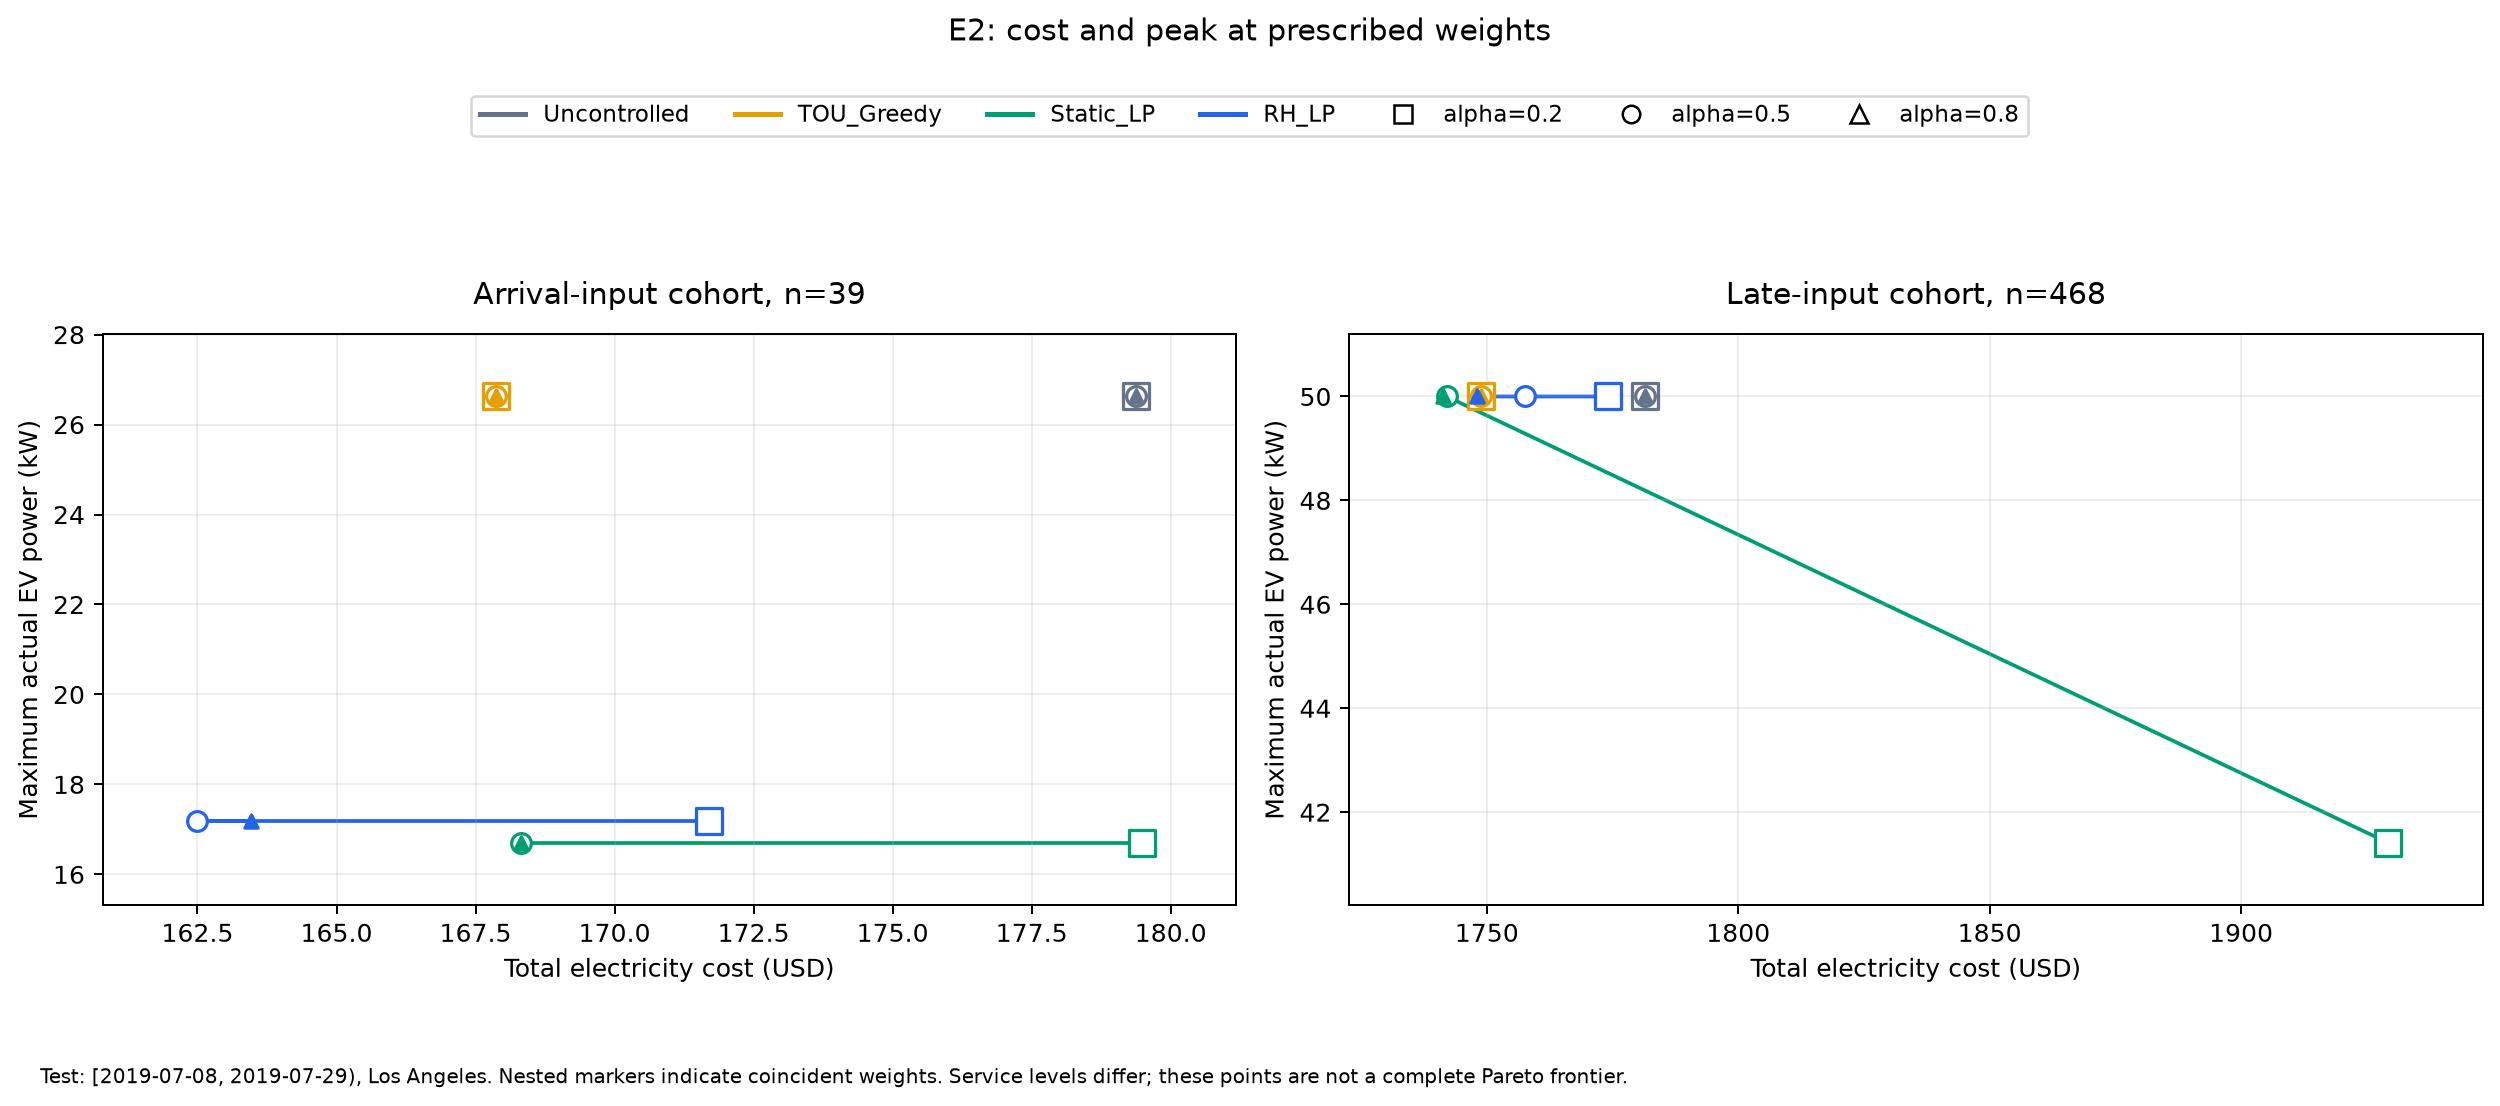

In [25]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import subprocess
import sys
from IPython.display import display, Image

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
BATCH = ROOT / "results/logs/stage4_sensitivity_20261112T124051538161Z"

plot_source = r'''
from pathlib import Path
import hashlib
import json
import sys
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

BATCH, OUT = Path(sys.argv[1]), Path(sys.argv[2])
OUT.mkdir(parents=True, exist_ok=False)
source = BATCH / "sensitivity_results.csv"
assert hashlib.sha256(source.read_bytes()).hexdigest() == (
    "c732274df130a5660d4f94a5a3a996aaf8417a5a6fc0bebb316939a8a3126fee"
)
table = pd.read_csv(source)
table = table[table["scenario_id"].isin(
    ["E1_reference", "E2_alpha020", "E2_alpha080"]
)]
methods = ["Uncontrolled", "TOU_Greedy", "Static_LP", "RH_LP"]
colors = dict(zip(methods, ["#64748b", "#e69f00", "#009e73", "#2563eb"]))
markers = {0.2: "s", 0.5: "o", 0.8: "^"}
sizes = {0.2: 105, 0.5: 62, 0.8: 28}
cohorts = ["main_at_arrival", "supplement_after_submission"]
titles = ["Arrival-input cohort, n=39", "Late-input cohort, n=468"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, cohort, title in zip(axes, cohorts, titles):
    for method in methods:
        data = table[
            (table["cohort"] == cohort) & (table["method"] == method)
        ].sort_values("alpha")
        ax.plot(data["cost_USD"], data["max_peak_kW"],
                color=colors[method], linewidth=1.5, zorder=1)
        for level in [0.2, 0.5, 0.8]:
            row = data[data["alpha"].eq(level)].iloc[0]
            ax.scatter(
                row["cost_USD"], row["max_peak_kW"],
                marker=markers[level], s=sizes[level],
                facecolors=("white" if level != 0.8 else colors[method]),
                edgecolors=colors[method], linewidths=1.3,
                zorder=2 + [0.2, 0.5, 0.8].index(level),
            )
    ax.set_title(title, pad=12)
    ax.set_xlabel("Total electricity cost (USD)")
    ax.set_ylabel("Maximum actual EV power (kW)")
    ax.grid(alpha=0.22)
    ax.margins(x=0.10, y=0.14)

handles = [
    Line2D([0], [0], color=colors[m], lw=2, label=m)
    for m in methods
] + [
    Line2D([0], [0], color="black", linestyle="None",
           marker=markers[a], markerfacecolor="white",
           label=f"alpha={a:g}", markersize=7)
    for a in [0.2, 0.5, 0.8]
]
fig.suptitle("E2: cost and peak at prescribed weights", y=0.98)
fig.legend(handles=handles, loc="upper center",
           bbox_to_anchor=(0.5, 0.92), ncol=7, fontsize=9)
fig.text(
    0.02, 0.025,
    "Test: [2019-07-08, 2019-07-29), Los Angeles. "
    "Nested markers indicate coincident weights. Service levels differ; "
    "these points are not a complete Pareto frontier.",
    fontsize=8,
)
fig.tight_layout(rect=(0, 0.09, 1, 0.82))
for extension in ["png", "svg"]:
    fig.savefig(OUT / f"weight_cost_peak.{extension}",
                dpi=180, bbox_inches="tight")
plt.close(fig)
result = {
    "status": "generated_for_visual_review",
    "source_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
    "script_sha256": hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
    "artifacts": {
        p.name: hashlib.sha256(p.read_bytes()).hexdigest()
        for p in OUT.iterdir() if p.is_file()
    },
}
(OUT / "verification.json").write_text(
    json.dumps(result, indent=2), encoding="utf-8"
)
print(json.dumps(result, indent=2))
print("Figure directory:", OUT)
'''
ast.parse(plot_source)
plot_script = ROOT / "experiments/plot_weight_cost_peak_markers.py"
if plot_script.exists():
    assert plot_script.read_text(encoding="utf-8") == plot_source
else:
    plot_script.write_text(plot_source, encoding="utf-8")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
MARKER_OUT = BATCH / f"weight_plot_{stamp}"
process = subprocess.run(
    [sys.executable, str(plot_script), str(BATCH), str(MARKER_OUT)],
    cwd=ROOT, capture_output=True, text=True,
)
print(process.stdout)
if process.stderr:
    print(process.stderr)
assert process.returncode == 0
display(Image(filename=str(MARKER_OUT / "weight_cost_peak.png")))

In [26]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import hashlib
import importlib.util
import json
import subprocess
import sys
import pandas as pd
import yaml

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
E1 = ROOT / "results/logs/stage4_main_test_20261112T102930606571Z"
ZERO = ROOT / "results/logs/stage4_robustness_zero_20261113T085102841093Z"

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def save_new(path, text):
    if path.exists():
        assert path.read_text(encoding="utf-8") == text, (
            f"已有文件不同，未覆盖：{path}"
        )
    else:
        path.write_text(text, encoding="utf-8")

# ---------- 核验入口等价证据 ----------
zero_config_path = ZERO / "smoke_config.yaml"
assert digest(zero_config_path) == (
    "d9f0e9f785a03c54646d19fe766919a10087d2b5d85a5e83b30cad751c06459c"
)
zero_config = yaml.safe_load(zero_config_path.read_text(encoding="utf-8"))
zero_result = json.loads(
    (ZERO / "smoke_verification.json").read_text(encoding="utf-8")
)
assert zero_result["status"] == "passed"
assert zero_result["check_count"] == 26
assert zero_result["long_experiments_started"] is False

for rel, expected in zero_config["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel

for variant, expected in {
    "bypass": "697461ab01946cff9421331b89d246045f0b1e95829a44b19928f0a49561b6c0",
    "zero": "ce75da671ff0bedd513e78530d4fc64f2e35f98b3f56d79c6dbcabff27577967",
}.items():
    path = ZERO / variant / "verification.json"
    assert digest(path) == expected
    record = json.loads(path.read_text(encoding="utf-8"))
    assert record["status"] == "passed"
    assert record["requires_review"] is False
    for rel, value in record["output_artifact_sha256"].items():
        assert digest(path.parent / rel) == value, rel

e1_record = json.loads(
    (E1 / "verification.json").read_text(encoding="utf-8")
)
assert e1_record["status"] == "passed"
assert not e1_record["requires_review"]
for rel, expected in e1_record["output_artifact_sha256"].items():
    assert digest(E1 / rel) == expected, rel

print("E1 与 E4 零误差对照证据核验通过。")

# ---------- 可独立运行的批处理器 ----------
worker_source = r'''
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import subprocess
import sys
import traceback
import numpy as np
import pandas as pd
import yaml

ROOT = Path(__file__).resolve().parents[1]
config_path, expected_hash, OUT = (
    Path(sys.argv[1]).resolve(), sys.argv[2], Path(sys.argv[3]).resolve()
)

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def write_json(path, value):
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )

assert digest(config_path) == expected_hash
config = yaml.safe_load(config_path.read_text(encoding="utf-8"))
assert config["status"] == "frozen"
assert len(config["scenarios"]) == 22

def check_sources():
    assert digest(config_path) == expected_hash
    for rel, value in config["source_and_input_sha256"].items():
        assert digest(ROOT / rel) == value, rel

check_sources()
E1 = ROOT / config["e1_directory"]
factor_manifest = pd.read_csv(
    ROOT / config["factor_manifest"], dtype={"sessionID": str}
)
methods = ["Uncontrolled", "TOU_Greedy", "RH_LP"]
cohorts = ["main_at_arrival", "supplement_after_submission"]

reference = pd.read_csv(E1 / "comparison.csv")
reference = reference[reference["method"].isin(methods)].copy()
assert len(reference) == 6
reference["scenario_id"] = "E1_reference"
reference["experiment"] = "E4_reference"
reference["amplitude"] = 0.0
reference["seed"] = None
reference["advance_minutes"] = 0
reference["scenario_type"] = "zero_reference_reused"
reference["evidence_directory"] = str(E1.relative_to(ROOT))
frames, outcomes = [reference], []

true_targets = {}
for cohort in cohorts:
    service = pd.read_csv(
        E1 / cohort / "RH_LP/session_service.csv", dtype={"sessionID": str}
    )
    true_targets[cohort] = service.set_index("sessionID")["evaluation_target_kwh"]

for index, scenario in enumerate(config["scenarios"], start=1):
    check_sources()
    folder = OUT / scenario["id"]
    folder.mkdir(exist_ok=False)
    write_json(OUT / "progress.json", {
        "state": "running",
        "current_scenario": scenario["id"],
        "scenario_index": index,
        "scenario_count": 22,
        "completed_count": len(outcomes),
        "outcomes": outcomes,
    })
    command = [
        sys.executable, "-u", str(ROOT / "experiments/run_robustness.py"),
        str(folder), "--split", "test",
        "--alpha", "0.5", "--capacity-kw", "50",
        "--base-hours", "24", "--static-time-limit", "120",
        "--frozen-config-sha256", config["e1_config_sha256"],
        "--protocol-config", str(config_path),
        "--protocol-sha256", expected_hash,
        "--scenario-id", scenario["id"],
    ]
    write_json(folder / "launch.json", {
        "command": command,
        "launched_at_utc": datetime.now(timezone.utc).isoformat(),
    })
    outcome = {
        "scenario_id": scenario["id"],
        "scenario_type": scenario["type"],
        "status": "failed",
    }
    try:
        with (folder / "stdout_stderr.txt").open("w", encoding="utf-8") as log:
            process = subprocess.run(
                command, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT
            )
        outcome["returncode"] = process.returncode
        write_json(folder / "process_exit.json", {
            "returncode": process.returncode
        })
        assert process.returncode == 0, "Scenario process failed"
        record = json.loads(
            (folder / "verification.json").read_text(encoding="utf-8")
        )
        assert record["status"] == "passed"
        for rel, value in record["source_and_input_sha256"].items():
            assert digest(ROOT / rel) == value, rel
        for rel, value in record["output_artifact_sha256"].items():
            assert digest(folder / rel) == value, rel

        frame = pd.read_csv(folder / "comparison.csv")
        assert len(frame) == 6
        assert set(zip(frame["cohort"], frame["method"])) == {
            (c, m) for c in cohorts for m in methods
        }
        for cohort in cohorts:
            expected = factor_manifest[
                (factor_manifest["scenario_id"] == scenario["id"]) &
                (factor_manifest["cohort"] == cohort)
            ].set_index("sessionID")["factor"].sort_index()
            actual = pd.read_csv(
                folder / cohort / "request_factors.csv",
                dtype={"sessionID": str}
            ).set_index("sessionID")["factor"].sort_index()
            assert actual.index.equals(expected.index)
            assert np.max(np.abs(
                actual.to_numpy() - expected.to_numpy()
            )) <= 1e-12

            targets = true_targets[cohort].sort_index()
            for method in methods:
                service = pd.read_csv(
                    folder / cohort / method / "session_service.csv",
                    dtype={"sessionID": str}
                )
                current = service.set_index(
                    "sessionID"
                )["evaluation_target_kwh"].sort_index()
                assert current.index.equals(targets.index)
                assert np.max(np.abs(
                    current.to_numpy() - targets.to_numpy()
                )) <= 1e-8

        check_sources()
        frame["scenario_type"] = scenario["type"]
        frame["evidence_directory"] = str(folder.relative_to(ROOT))
        frames.append(frame)
        outcome.update(
            status=("requires_review" if record["requires_review"] else "passed"),
            check_count=record["check_count"],
            wall_seconds=record["wall_seconds"],
        )
    except Exception:
        outcome["error"] = traceback.format_exc()

    outcomes.append(outcome)
    write_json(folder / "scenario_outcome.json", outcome)
    write_json(OUT / "outcomes.json", outcomes)
    pd.concat(frames, ignore_index=True).to_csv(
        OUT / "robustness_results.csv", index=False
    )
    print(json.dumps(outcome, ensure_ascii=False), flush=True)

check_sources()
passed = all(item["status"] == "passed" for item in outcomes)
result = {
    "status": "passed" if passed else "requires_review",
    "scope": "E4 prescribed 22 scenarios; E1 zero reference reused",
    "config_sha256": expected_hash,
    "scenarios": outcomes,
    "reference_directory": str(E1.relative_to(ROOT)),
    "reference_policy": (
        "E1 online runs reused; zero-transform equivalence was checked "
        "on a small sample, not by a full zero-error rerun."
    ),
    "results_sha256": digest(OUT / "robustness_results.csv"),
}
write_json(OUT / "batch_verification.json", result)
write_json(OUT / "progress.json", {
    "state": "finished", "completed_count": len(outcomes),
    "outcomes": outcomes,
})
print(json.dumps(result, ensure_ascii=False, indent=2), flush=True)
sys.exit(0 if passed else 1)
'''
ast.parse(worker_source)
worker = ROOT / "experiments/run_robustness_batch.py"
save_new(worker, worker_source)

# ---------- 冻结 22 个单因素情景 ----------
# 先运行两个确定性提前离站情景，再依次运行各种子的配对误差幅度。
scenarios = [
    {
        "id": f"E4_early{minutes}",
        "type": "early_departure",
        "amplitude": 0.0, "seed": 0, "advance_minutes": minutes,
    }
    for minutes in [15, 30]
]
for seed in range(10):
    for amplitude in [0.1, 0.2]:
        scenarios.append({
            "id": f"E4_req{round(amplitude * 100):02d}_seed{seed:02d}",
            "type": "demand_estimation_error",
            "amplitude": amplitude, "seed": seed, "advance_minutes": 0,
        })
assert len(scenarios) == 22

DATA = ROOT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"
sessions = pd.read_csv(DATA / "sessions_with_split.csv",
                       dtype={"sessionID": str})
sessions = sessions[sessions["split"].eq("test")].copy()
assert sessions["cohort"].value_counts().to_dict() == {
    "supplement_after_submission": 468, "main_at_arrival": 39
}

helper = ROOT / "experiments/robustness_protocol.py"
spec = importlib.util.spec_from_file_location("ev_e4_factors", helper)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
E4_OUT = ROOT / "results/logs" / f"stage4_robustness_{stamp}"
E4_OUT.mkdir(parents=True, exist_ok=False)

factor_rows = []
for scenario in scenarios:
    for row in sessions[["sessionID", "cohort"]].to_dict("records"):
        factor_rows.append({
            "scenario_id": scenario["id"],
            **row,
            "factor": module.factor_for(
                row["sessionID"], scenario["amplitude"], scenario["seed"]
            ),
        })
factor_path = E4_OUT / "factor_manifest.csv"
pd.DataFrame(factor_rows).to_csv(factor_path, index=False)
pd.DataFrame(scenarios).to_csv(E4_OUT / "scenario_manifest.csv", index=False)

sources = dict(zero_config["source_and_input_sha256"])
for path in [
    worker, factor_path,
    ZERO / "smoke_config.yaml", ZERO / "smoke_verification.json",
    ZERO / "bypass/verification.json", ZERO / "zero/verification.json",
    E1 / "verification.json", E1 / "comparison.csv",
]:
    sources[str(path.relative_to(ROOT))] = digest(path)

config = {
    "status": "frozen",
    "scope": "E4_controlled_synthetic_information_errors",
    "frozen_at_utc": datetime.now(timezone.utc).isoformat(),
    "e1_directory": str(E1.relative_to(ROOT)),
    "e1_config_sha256": digest(ROOT / "configs/final.yaml"),
    "methods": ["Uncontrolled", "TOU_Greedy", "RH_LP"],
    "seeds": list(range(10)),
    "amplitudes": [0.1, 0.2],
    "error_distribution": "per-session fixed sign, values minus/plus amplitude",
    "pairing": "same sign across amplitudes, updates and online methods",
    "evaluation_targets": "fixed E1 targets; excess reported separately",
    "early_departure_policy": "clip at arrival plus 1 ns; retain all sessions",
    "zero_reference": "reuse E1; small-sample runner equivalence passed",
    "no_test_based_parameter_selection": True,
    "factor_manifest": str(factor_path.relative_to(ROOT)),
    "scenarios": scenarios,
    "source_and_input_sha256": sources,
}
config_path = ROOT / "configs/robustness.yaml"
assert not config_path.exists(), (
    "robustness.yaml 已存在，未覆盖、未重复启动；请回传提示。"
)
with config_path.open("x", encoding="utf-8") as stream:
    yaml.safe_dump(config, stream, allow_unicode=True, sort_keys=False)
config_hash = digest(config_path)
(E4_OUT / "robustness.yaml").write_bytes(config_path.read_bytes())

command = [
    sys.executable, "-u", str(worker),
    str(config_path), config_hash, str(E4_OUT),
]
with (E4_OUT / "stdout_stderr.txt").open("w", encoding="utf-8") as stream:
    E4_PROCESS = subprocess.Popen(
        command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT,
        start_new_session=True,
    )
(E4_OUT / "launch.json").write_text(
    json.dumps({
        "command": command, "pid": E4_PROCESS.pid,
        "config_sha256": config_hash,
        "launched_at_utc": datetime.now(timezone.utc).isoformat(),
    }, ensure_ascii=False, indent=2),
    encoding="utf-8"
)
print("E4 正式配置已冻结，SHA-256：", config_hash)
print("22 个情景已顺序启动，PID：", E4_PROCESS.pid)
print("证据目录：", E4_OUT)
print("这是启动记录，尚未登记正式鲁棒性实验通过。")

E1 与 E4 零误差对照证据核验通过。
E4 正式配置已冻结，SHA-256： 5c52d926f1f94598f9f285babd0cacf0365db4b7fc085029f70d7be2618aa5e8
22 个情景已顺序启动，PID： 1186228
证据目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_robustness_20261113T090451907487Z
这是启动记录，尚未登记正式鲁棒性实验通过。


In [39]:
import json

code = E4_PROCESS.poll()
print("证据目录：", E4_OUT)
print("批处理状态：", "运行中" if code is None else f"已退出，退出码={code}")

progress_path = E4_OUT / "progress.json"
if progress_path.exists():
    try:
        progress = json.loads(progress_path.read_text(encoding="utf-8"))
        print("阶段：", progress.get("state"))
        print("已完成：", progress.get("completed_count", 0), "/ 22")
        current = progress.get("current_scenario")
        if current:
            print("当前情景：", current)
            child = E4_OUT / current / "progress.json"
            if child.exists():
                print(child.read_text(encoding="utf-8"))
            log = E4_OUT / current / "stdout_stderr.txt"
            if log.exists():
                print("\n=== 当前情景日志末尾 ===")
                print("\n".join(
                    log.read_text(encoding="utf-8").splitlines()[-8:]
                ))
        if progress.get("outcomes"):
            print("\n=== 已完成情景 ===")
            for outcome in progress["outcomes"]:
                print(json.dumps(outcome, ensure_ascii=False))
    except json.JSONDecodeError:
        print("进度文件正在更新，稍后重查即可。")

if code is not None:
    print("\n=== 批处理日志末尾 ===")
    print("\n".join(
        (E4_OUT / "stdout_stderr.txt").read_text(
            encoding="utf-8"
        ).splitlines()[-45:]
    ))
    result = E4_OUT / "batch_verification.json"
    if result.exists():
        print("\n=== 正式 E4 审计 ===")
        print(result.read_text(encoding="utf-8"))

证据目录： /home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization/results/logs/stage4_robustness_20261113T090451907487Z
批处理状态： 已退出，退出码=0
阶段： finished
已完成： 22 / 22

=== 已完成情景 ===
{"scenario_id": "E4_early15", "scenario_type": "early_departure", "status": "passed", "returncode": 0, "check_count": 38, "wall_seconds": 4299.164494899102}
{"scenario_id": "E4_early30", "scenario_type": "early_departure", "status": "passed", "returncode": 0, "check_count": 38, "wall_seconds": 3179.7814378449693}
{"scenario_id": "E4_req10_seed00", "scenario_type": "demand_estimation_error", "status": "passed", "returncode": 0, "check_count": 38, "wall_seconds": 2627.87377907522}
{"scenario_id": "E4_req20_seed00", "scenario_type": "demand_estimation_error", "status": "passed", "returncode": 0, "check_count": 38, "wall_seconds": 2621.757287156768}
{"scenario_id": "E4_req10_seed01", "scenario_type": "demand_estimation_error", "status": "passed", "returncode": 0, "check_count": 38, "wall_seconds": 2665.0444407588802

Audited 1/23: E1_reference
Audited 2/23: E4_early15
Audited 3/23: E4_early30
Audited 4/23: E4_req10_seed00
Audited 5/23: E4_req20_seed00
Audited 6/23: E4_req10_seed01
Audited 7/23: E4_req20_seed01
Audited 8/23: E4_req10_seed02
Audited 9/23: E4_req20_seed02
Audited 10/23: E4_req10_seed03
Audited 11/23: E4_req20_seed03
Audited 12/23: E4_req10_seed04
Audited 13/23: E4_req20_seed04
Audited 14/23: E4_req10_seed05
Audited 15/23: E4_req20_seed05
Audited 16/23: E4_req10_seed06
Audited 17/23: E4_req20_seed06
Audited 18/23: E4_req10_seed07
Audited 19/23: E4_req20_seed07
Audited 20/23: E4_req10_seed08
Audited 21/23: E4_req20_seed08
Audited 22/23: E4_req10_seed09
Audited 23/23: E4_req20_seed09

=== E4 SUMMARY AUDIT ===
{
  "status": "passed",
  "scope": "E4 result audit and descriptive summary; not whole stage 4",
  "formal_scenarios": 22,
  "new_method_cohort_results": 132,
  "reused_reference_results": 6,
  "seed_groups": 12,
  "daily_paired_rows": 1932,
  "zero_fallback": true
}

=== TEN-SEED S

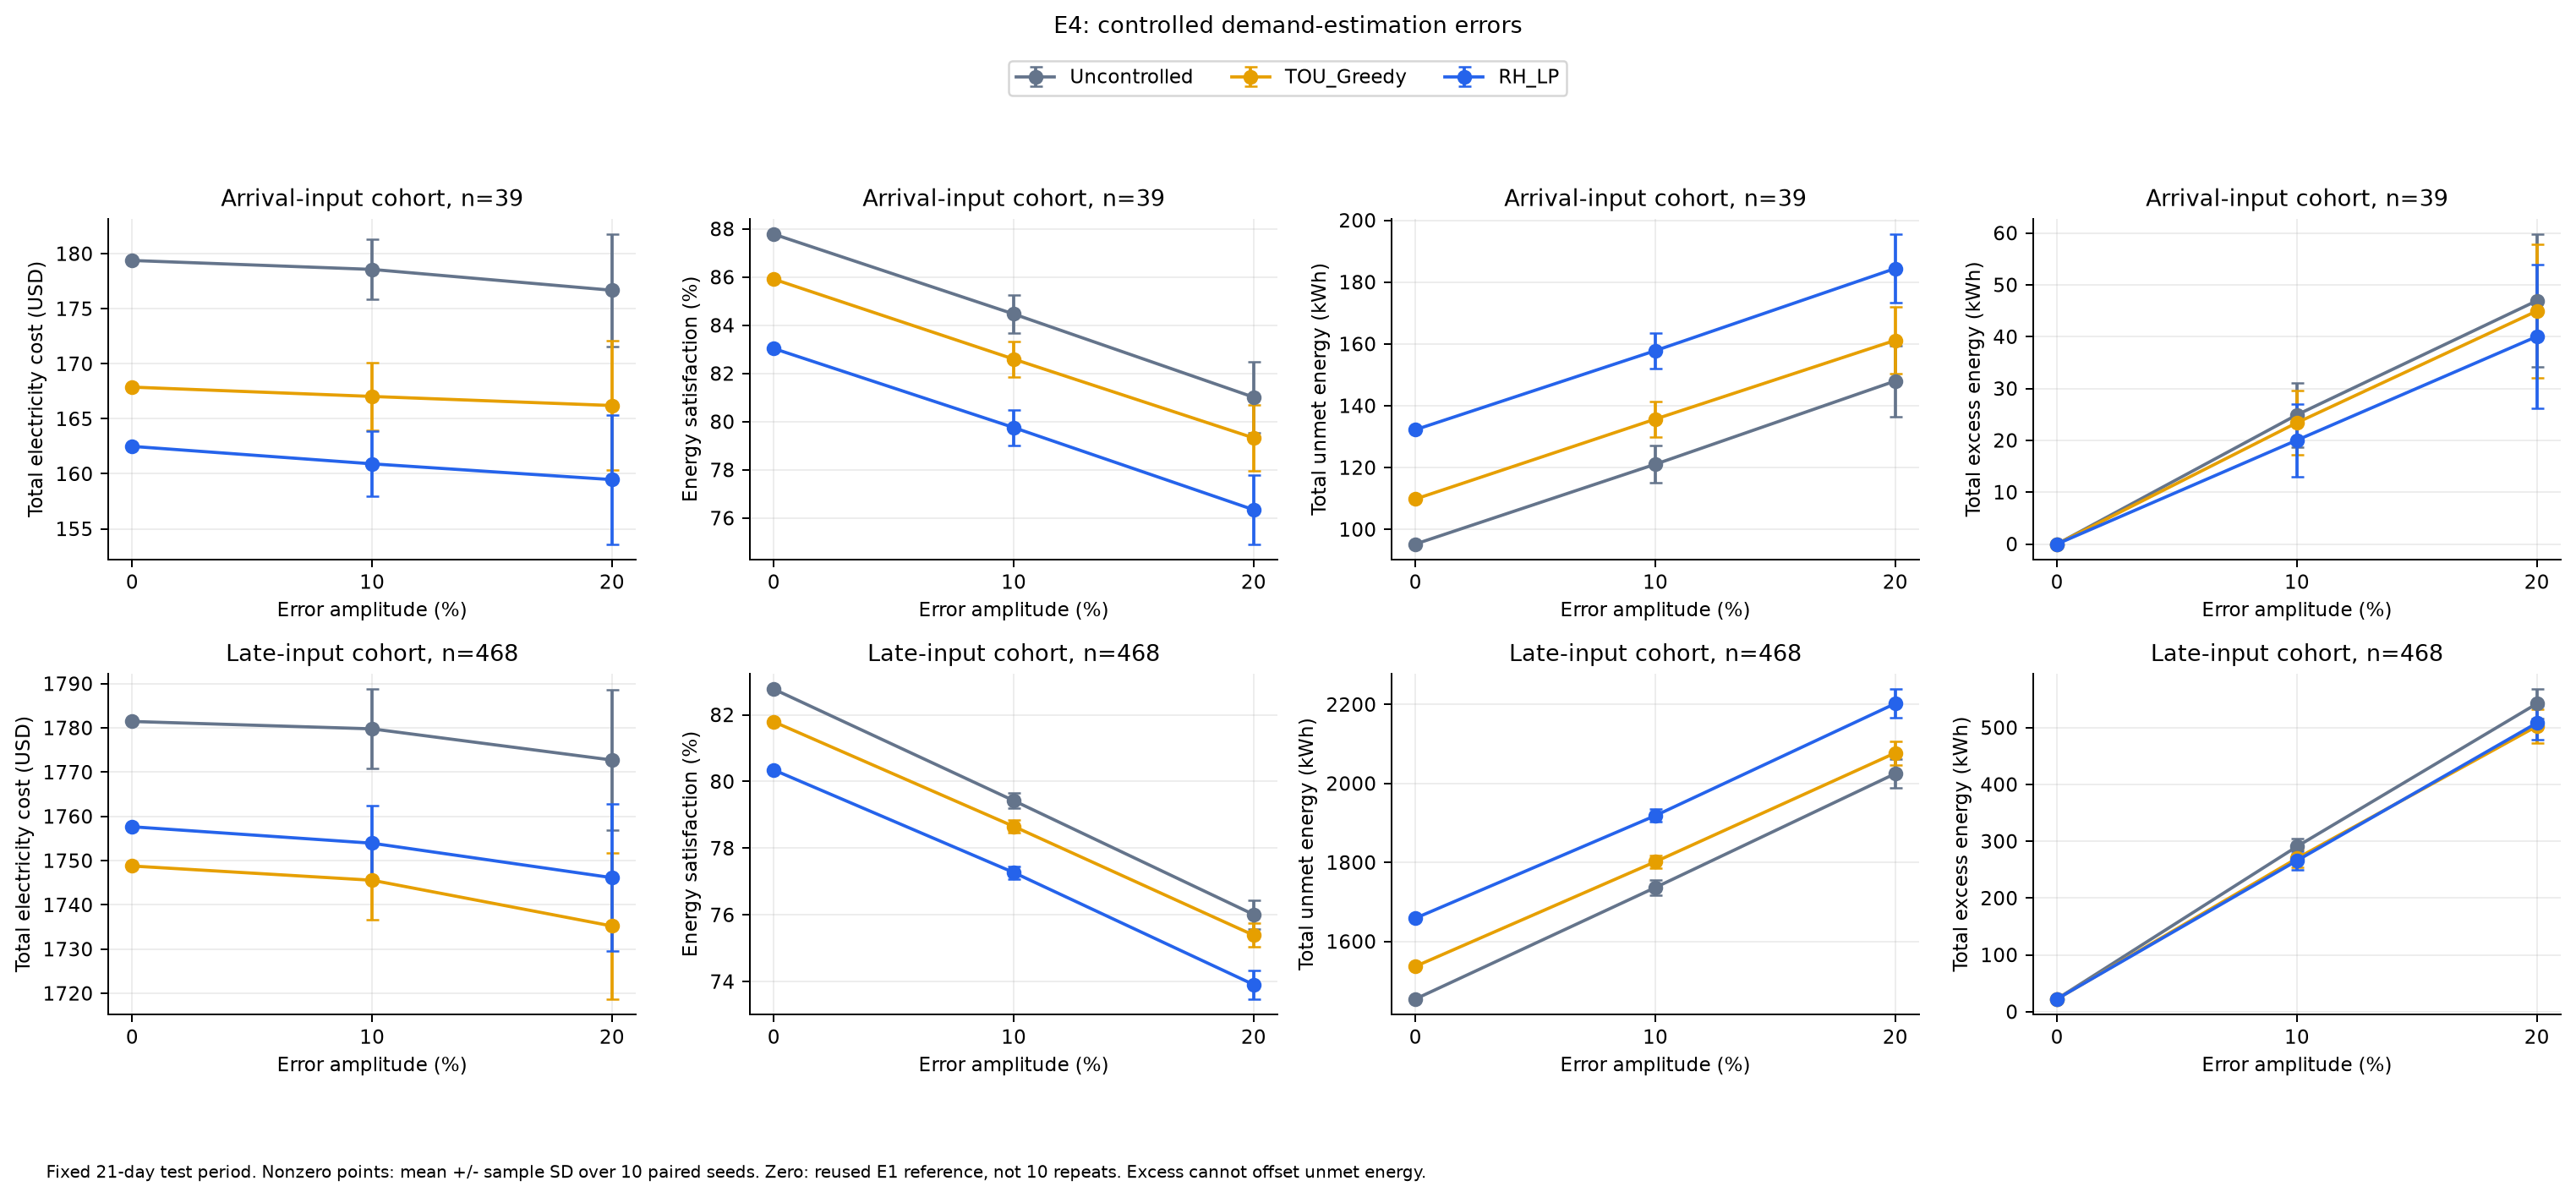

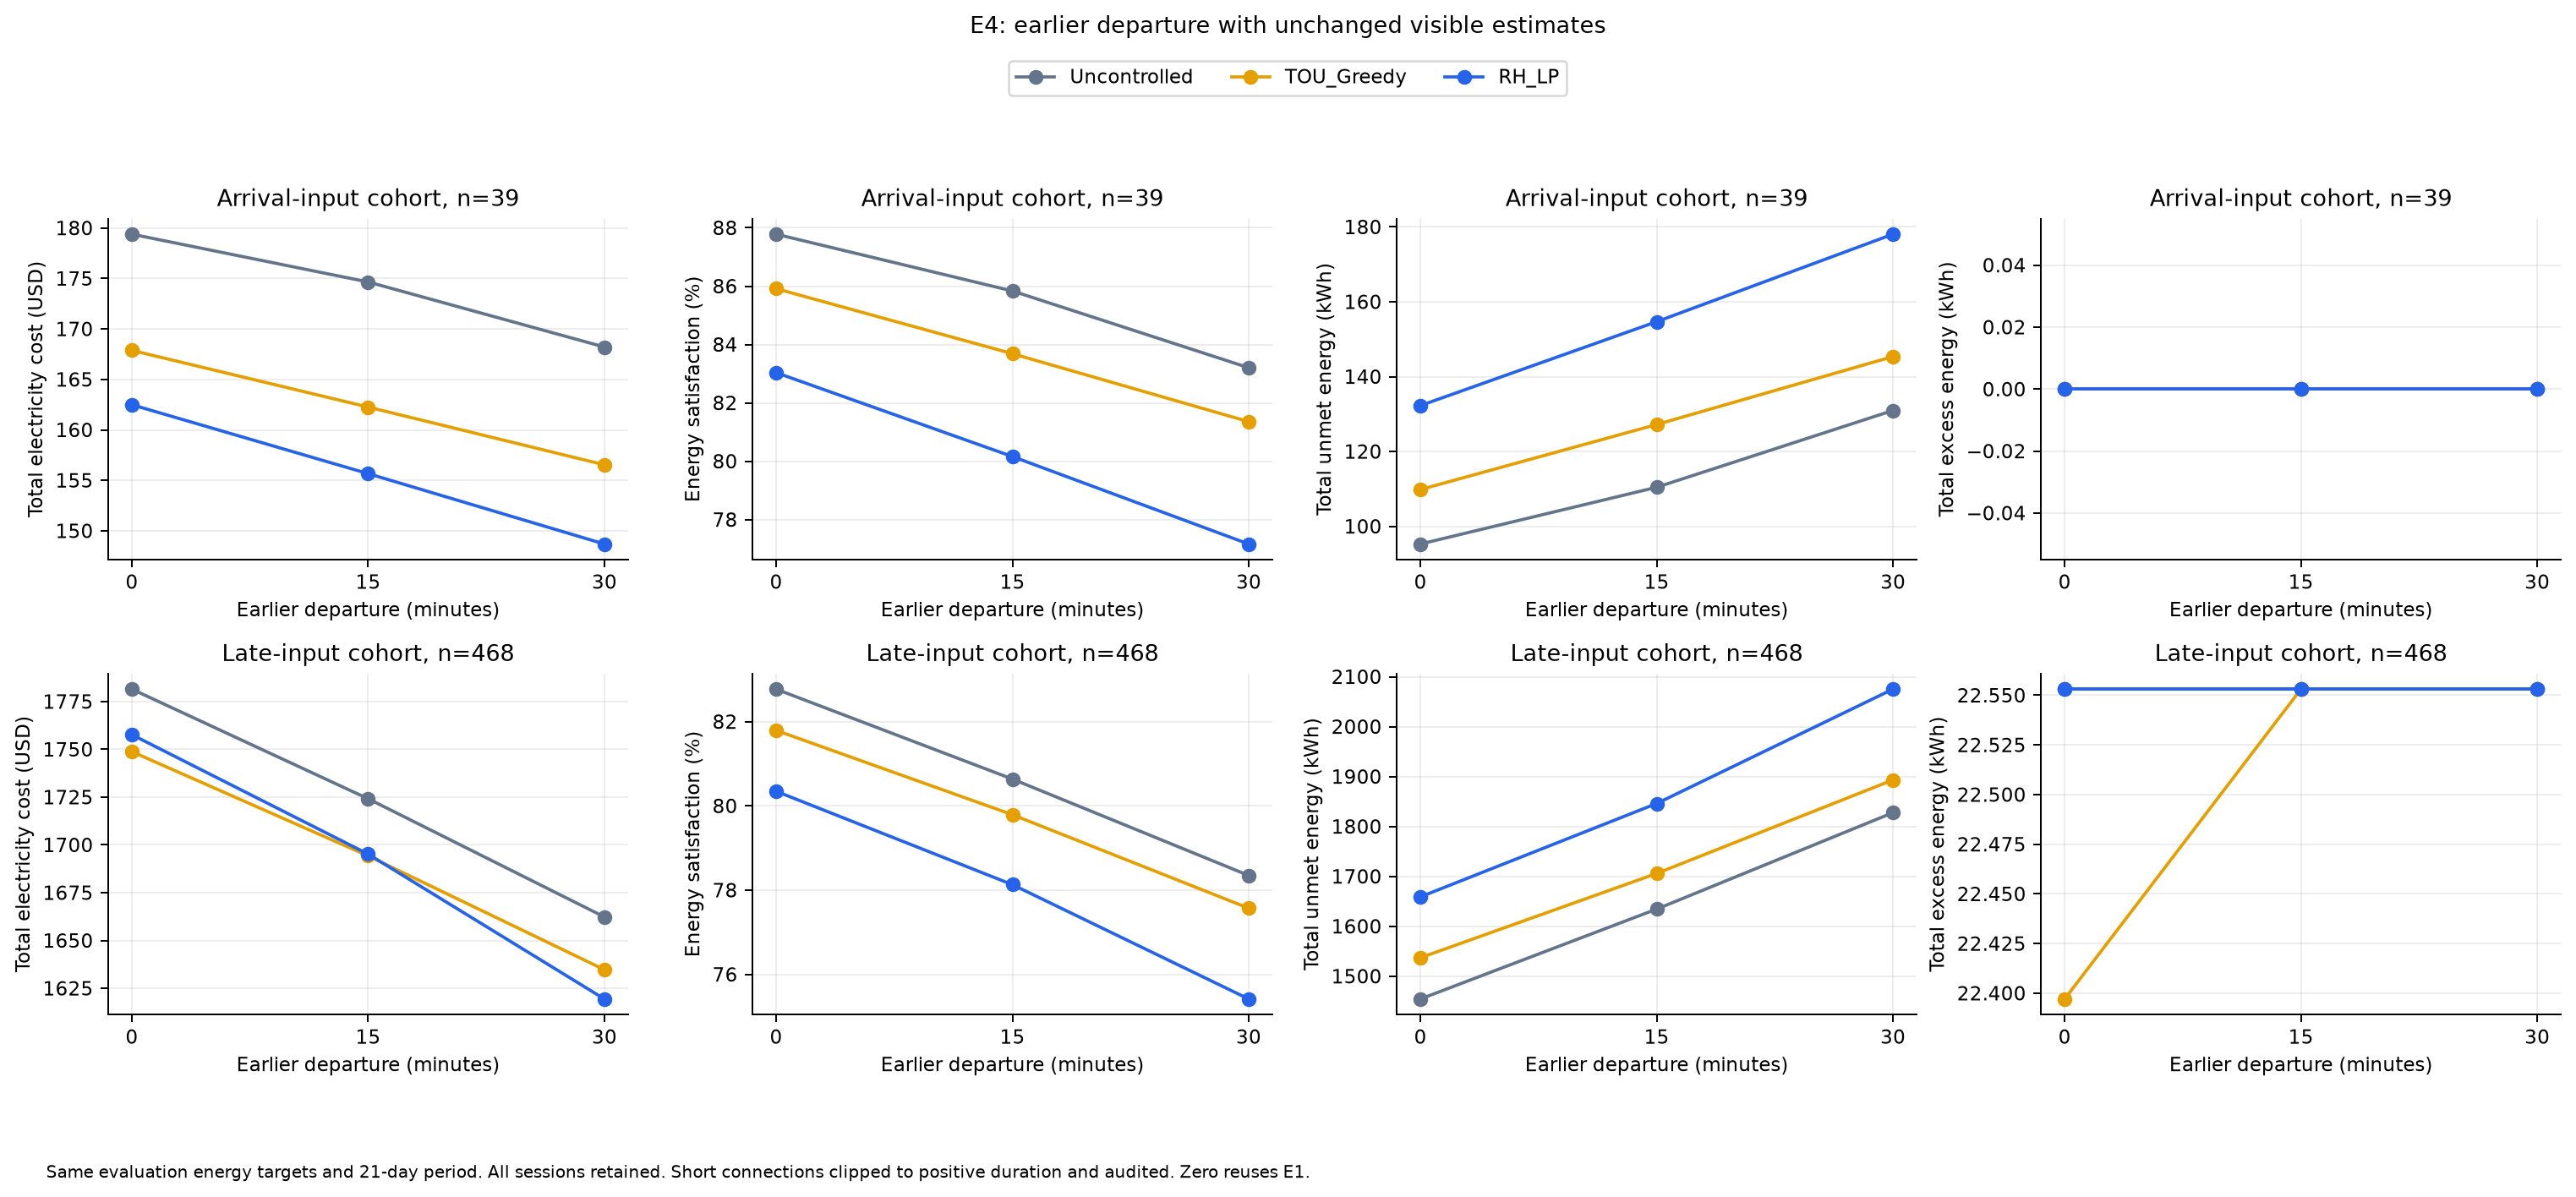

In [40]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import subprocess
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
BATCH = ROOT / "results/logs/stage4_robustness_20261113T090451907487Z"

summary_source = r'''
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1]
BATCH, OUT = Path(sys.argv[1]).resolve(), Path(sys.argv[2]).resolve()
OUT.mkdir(parents=True, exist_ok=False)

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def write_json(path, value):
    path.write_text(
        json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8"
    )

batch = json.loads(
    (BATCH / "batch_verification.json").read_text(encoding="utf-8")
)
assert batch["status"] == "passed"
assert len(batch["scenarios"]) == 22
assert all(
    s["status"] == "passed" and s["returncode"] == 0
    and s["check_count"] == 38
    for s in batch["scenarios"]
)
assert batch["config_sha256"] == (
    "5c52d926f1f94598f9f285babd0cacf0365db4b7fc085029f70d7be2618aa5e8"
)
assert batch["results_sha256"] == (
    "285dc3972c5702146ea508b46cd7f7e89f3f78b8647e175a3a0571d026129c3f"
)
assert digest(BATCH / "robustness_results.csv") == batch["results_sha256"]

config_path = ROOT / "configs/robustness.yaml"
assert digest(config_path) == batch["config_sha256"]
config = yaml.safe_load(config_path.read_text(encoding="utf-8"))
assert config["status"] == "frozen"
for rel, expected in config["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel

registered = {s["id"]: s for s in config["scenarios"]}
assert len(registered) == 22
assert set(registered) == {s["scenario_id"] for s in batch["scenarios"]}

E1 = ROOT / config["e1_directory"]
table = pd.read_csv(BATCH / "robustness_results.csv")
methods = ["Uncontrolled", "TOU_Greedy", "RH_LP"]
cohorts = ["main_at_arrival", "supplement_after_submission"]
metrics = [
    "cost_USD", "delivered_kwh", "unmet_kwh", "excess_kwh",
    "energy_satisfaction", "max_peak_kW",
    "actual_departure_uncompleted_rate", "active_P95_seconds",
]
assert len(table) == 138
assert not table.duplicated(["scenario_id", "cohort", "method"]).any()
assert table["fallback_count"].eq(0).all()
assert table["requires_review"].astype(str).str.lower().eq("false").all()
assert set(table["scenario_id"]) == set(registered) | {"E1_reference"}

base = table[table["scenario_id"].eq("E1_reference")].copy()
assert len(base) == 6
base_services = {
    (cohort, method): pd.read_csv(
        E1 / cohort / method / "session_service.csv",
        dtype={"sessionID": str}
    ).set_index("sessionID")
    for cohort in cohorts for method in methods
}
factor_manifest = pd.read_csv(
    ROOT / config["factor_manifest"], dtype={"sessionID": str}
)
expected_dates = list(pd.date_range(
    "2019-07-08", "2019-07-29", inclusive="left", freq="D"
).strftime("%Y-%m-%d"))

daily_frames, case_frames, evidence = [], [], {}
runs = [("E1_reference", E1)] + [
    (s["id"], BATCH / s["id"]) for s in config["scenarios"]
]

for index, (scenario_id, folder) in enumerate(runs, start=1):
    verification_path = folder / "verification.json"
    verification = json.loads(verification_path.read_text(encoding="utf-8"))
    assert verification["status"] == "passed"
    assert verification["requires_review"] is False
    for rel, expected in verification["source_and_input_sha256"].items():
        assert digest(ROOT / rel) == expected, rel
    for rel, expected in verification["output_artifact_sha256"].items():
        assert digest(folder / rel) == expected, rel
    evidence[str(verification_path.relative_to(ROOT))] = digest(verification_path)

    current = pd.read_csv(folder / "comparison.csv")
    current = current[current["method"].isin(methods)]
    exported = table[table["scenario_id"].eq(scenario_id)]
    assert len(current) == len(exported) == 6
    current = current.set_index(["cohort", "method"]).sort_index()
    exported = exported.set_index(["cohort", "method"]).sort_index()
    pd.testing.assert_frame_equal(
        current[metrics], exported[metrics],
        check_dtype=False, check_exact=False, rtol=0, atol=1e-8
    )

    if scenario_id != "E1_reference":
        scenario = registered[scenario_id]
        assert exported["amplitude"].eq(scenario["amplitude"]).all()
        assert exported["seed"].eq(scenario["seed"]).all()
        assert exported["advance_minutes"].eq(scenario["advance_minutes"]).all()

    for cohort in cohorts:
        if scenario_id != "E1_reference":
            wanted = factor_manifest[
                factor_manifest["scenario_id"].eq(scenario_id) &
                factor_manifest["cohort"].eq(cohort)
            ].set_index("sessionID")["factor"].sort_index()
            actual = pd.read_csv(
                folder / cohort / "request_factors.csv",
                dtype={"sessionID": str}
            ).set_index("sessionID")["factor"].sort_index()
            assert wanted.index.equals(actual.index)
            assert np.allclose(wanted, actual, rtol=0, atol=1e-12)

        for method in methods:
            item = folder / cohort / method
            service = pd.read_csv(
                item / "session_service.csv", dtype={"sessionID": str}
            ).set_index("sessionID")
            original = base_services[(cohort, method)]
            assert set(service.index) == set(original.index)
            service = service.reindex(original.index)
            assert np.allclose(
                service["evaluation_target_kwh"],
                original["evaluation_target_kwh"], rtol=0, atol=1e-8
            )

            daily = pd.read_csv(item / "daily_metrics.csv")
            daily = daily.sort_values("local_date").reset_index(drop=True)
            assert daily["local_date"].astype(str).tolist() == expected_dates
            row = exported.loc[(cohort, method)]
            assert abs(daily["cost_USD"].sum() - row["cost_USD"]) <= 1e-5
            assert abs(daily["energy_kwh"].sum() - row["delivered_kwh"]) <= 1e-5
            assert abs(daily["peak_kW"].max() - row["max_peak_kW"]) <= 1e-6
            daily = daily.assign(
                scenario_id=scenario_id, cohort=cohort, method=method
            )
            daily_frames.append(daily)

            if scenario_id != "E1_reference":
                changed = service[[
                    "evaluation_target_kwh", "delivered_kwh",
                    "unmet_kwh", "excess_kwh", "satisfaction"
                ]].copy()
                changed["baseline_unmet_kwh"] = original["unmet_kwh"]
                changed["delta_unmet_kwh"] = (
                    changed["unmet_kwh"] - original["unmet_kwh"]
                )
                changed["delta_excess_kwh"] = (
                    changed["excess_kwh"] - original["excess_kwh"]
                )
                changed = changed.reset_index().assign(
                    scenario_id=scenario_id,
                    scenario_type=registered[scenario_id]["type"],
                    cohort=cohort, method=method,
                    evidence_directory=str(item.relative_to(ROOT)),
                )
                case_frames.append(changed)

    print(f"Audited {index}/23: {scenario_id}", flush=True)

daily = pd.concat(daily_frames, ignore_index=True)
daily.to_csv(OUT / "daily_metrics_all.csv", index=False)

# 1. 原始情景结果与相对各方法自身 E1 基准的变化
reference = base[["cohort", "method"] + metrics]
degradation = table.merge(
    reference, on=["cohort", "method"],
    suffixes=("", "_reference"), validate="many_to_one"
)
for column in ["cost_USD", "unmet_kwh", "excess_kwh", "max_peak_kW"]:
    degradation["delta_" + column] = (
        degradation[column] - degradation[column + "_reference"]
    )
degradation["delta_satisfaction_pp"] = 100 * (
    degradation["energy_satisfaction"] -
    degradation["energy_satisfaction_reference"]
)
degradation.to_csv(OUT / "scenario_changes_vs_E1.csv", index=False)

# 2. 十种子统计；零误差参考不伪装成十次独立重复
errors = table[
    table["scenario_type"].eq("demand_estimation_error")
].copy()
assert len(errors) == 120
errors["seed"] = errors["seed"].astype(int)
for _, group in errors.groupby(["cohort", "method", "amplitude"]):
    assert len(group) == 10
    assert set(group["seed"]) == set(range(10))

seed_stats = errors.groupby(
    ["cohort", "method", "amplitude"]
)[metrics].agg(["count", "mean", "median", "std", "min", "max"])
seed_stats.columns = [
    f"{column}__{statistic}" for column, statistic in seed_stats.columns
]
seed_stats = seed_stats.reset_index()
seed_stats.to_csv(OUT / "seed_statistics.csv", index=False)

# 3. 同种子下 20% 与 10% 的配对差异
low = errors[errors["amplitude"].eq(0.1)]
high = errors[errors["amplitude"].eq(0.2)]
strength = high.merge(
    low, on=["cohort", "method", "seed"],
    suffixes=("_20", "_10"), validate="one_to_one"
)
strength_out = strength[["cohort", "method", "seed"]].copy()
for column in ["cost_USD", "unmet_kwh", "excess_kwh", "max_peak_kW"]:
    strength_out["delta_" + column] = (
        strength[column + "_20"] - strength[column + "_10"]
    )
strength_out["delta_satisfaction_pp"] = 100 * (
    strength["energy_satisfaction_20"] -
    strength["energy_satisfaction_10"]
)
assert len(strength_out) == 60
strength_out.to_csv(OUT / "paired_20_minus_10.csv", index=False)

# 4. 提前离站是确定性单因素情景，不复制成十种子
early = degradation[
    degradation["scenario_type"].eq("early_departure") |
    degradation["scenario_id"].eq("E1_reference")
].sort_values(["cohort", "method", "advance_minutes"])
assert len(early) == 18
early.to_csv(OUT / "early_departure_comparison.csv", index=False)

# 5. RH 与同情景规则基线配对，差值定义为 RH 减基线
indexed = table.set_index(["scenario_id", "cohort", "method"])
method_pairs = []
for row in table[table["method"].eq("RH_LP")].to_dict("records"):
    for baseline_method in ["Uncontrolled", "TOU_Greedy"]:
        baseline = indexed.loc[
            (row["scenario_id"], row["cohort"], baseline_method)
        ]
        method_pairs.append({
            "scenario_id": row["scenario_id"],
            "scenario_type": row["scenario_type"],
            "cohort": row["cohort"],
            "amplitude": row["amplitude"], "seed": row["seed"],
            "baseline_method": baseline_method,
            "delta_cost_USD": row["cost_USD"] - baseline["cost_USD"],
            "delta_unmet_kwh": row["unmet_kwh"] - baseline["unmet_kwh"],
            "delta_excess_kwh": row["excess_kwh"] - baseline["excess_kwh"],
            "delta_peak_kW": row["max_peak_kW"] - baseline["max_peak_kW"],
            "delta_satisfaction_pp": 100 * (
                row["energy_satisfaction"] - baseline["energy_satisfaction"]
            ),
        })
method_pairs = pd.DataFrame(method_pairs)
assert len(method_pairs) == 92
method_pairs.to_csv(OUT / "RH_paired_method_differences.csv", index=False)

random_pairs = method_pairs[
    method_pairs["scenario_type"].eq("demand_estimation_error")
]
pair_columns = [
    "delta_cost_USD", "delta_unmet_kwh", "delta_excess_kwh",
    "delta_peak_kW", "delta_satisfaction_pp"
]
pair_stats = random_pairs.groupby(
    ["cohort", "amplitude", "baseline_method"]
)[pair_columns].agg(["mean", "std", "min", "max"])
pair_stats.columns = [f"{c}__{s}" for c, s in pair_stats.columns]
pair_stats = pair_stats.reset_index()
pair_stats.to_csv(OUT / "RH_paired_seed_statistics.csv", index=False)

# 6. 日级配对保留全部 21 天，包括零负荷日
daily_pairs = []
for baseline_method in ["Uncontrolled", "TOU_Greedy"]:
    rh = daily[daily["method"].eq("RH_LP")]
    rule = daily[daily["method"].eq(baseline_method)]
    joined = rh.merge(
        rule, on=["scenario_id", "cohort", "local_date"],
        suffixes=("_RH", "_baseline"), validate="one_to_one"
    )
    frame = joined[["scenario_id", "cohort", "local_date"]].copy()
    frame["baseline_method"] = baseline_method
    frame["delta_cost_USD"] = (
        joined["cost_USD_RH"] - joined["cost_USD_baseline"]
    )
    frame["delta_daily_peak_kW"] = (
        joined["peak_kW_RH"] - joined["peak_kW_baseline"]
    )
    daily_pairs.append(frame)
daily_pairs = pd.concat(daily_pairs, ignore_index=True)
assert len(daily_pairs) == 1932
daily_pairs.to_csv(OUT / "daily_RH_paired_differences.csv", index=False)

daily_stats = []
for keys, group in daily_pairs.groupby(
    ["scenario_id", "cohort", "baseline_method"]
):
    assert len(group) == 21
    row = dict(zip(["scenario_id", "cohort", "baseline_method"], keys))
    row["days"] = 21
    for column in ["delta_cost_USD", "delta_daily_peak_kW"]:
        values = group[column]
        row.update({
            column + "__mean": float(values.mean()),
            column + "__median": float(values.median()),
            column + "__q25": float(values.quantile(0.25)),
            column + "__q75": float(values.quantile(0.75)),
            column + "__days_lower": int((values < -1e-8).sum()),
            column + "__days_higher": int((values > 1e-8).sum()),
            column + "__days_equal": int((values.abs() <= 1e-8).sum()),
        })
    daily_stats.append(row)
pd.DataFrame(daily_stats).to_csv(
    OUT / "daily_paired_descriptive_statistics.csv", index=False
)

# 7. 保存全部逐车变化及预先固定排序的案例候选
cases = pd.concat(case_frames, ignore_index=True)
cases.to_csv(OUT / "session_changes_vs_E1.csv", index=False)
candidates = cases.sort_values(
    ["delta_unmet_kwh", "scenario_id", "sessionID"],
    ascending=[False, True, True], kind="mergesort"
).groupby(
    ["cohort", "method", "scenario_type"], sort=False
).head(3)
candidates.to_csv(OUT / "largest_shortfall_change_candidates.csv", index=False)

# 8. 图表：误差条是十种子的样本标准差
colors = {
    "Uncontrolled": "#64748b",
    "TOU_Greedy": "#e69f00",
    "RH_LP": "#2563eb",
}
titles = {
    "main_at_arrival": "Arrival-input cohort, n=39",
    "supplement_after_submission": "Late-input cohort, n=468",
}
plt.rcParams.update({
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False
})
columns = [
    ("cost_USD", "Total electricity cost (USD)", 1),
    ("energy_satisfaction", "Energy satisfaction (%)", 100),
    ("unmet_kwh", "Total unmet energy (kWh)", 1),
    ("excess_kwh", "Total excess energy (kWh)", 1),
]
stats_index = seed_stats.set_index(["cohort", "method", "amplitude"])
base_index = base.set_index(["cohort", "method"])

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for i, cohort in enumerate(cohorts):
    for j, (metric, ylabel, scale) in enumerate(columns):
        ax = axes[i, j]
        for method in methods:
            means = [float(base_index.loc[(cohort, method), metric])]
            deviations = [0.0]
            for amplitude in [0.1, 0.2]:
                row = stats_index.loc[(cohort, method, amplitude)]
                means.append(float(row[metric + "__mean"]))
                deviations.append(float(row[metric + "__std"]))
            ax.errorbar(
                [0, 10, 20], np.array(means) * scale,
                yerr=np.array(deviations) * scale,
                marker="o", capsize=3, color=colors[method], label=method
            )
        ax.set_title(titles[cohort])
        ax.set_xlabel("Error amplitude (%)")
        ax.set_xticks([0, 10, 20])
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.22)
fig.suptitle("E4: controlled demand-estimation errors")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           bbox_to_anchor=(0.5, 0.95), ncol=3)
fig.text(
    0.02, 0.025,
    "Fixed 21-day test period. Nonzero points: mean +/- sample SD over 10 paired "
    "seeds. Zero: reused E1 reference, not 10 repeats. Excess cannot offset unmet energy.",
    fontsize=8
)
fig.tight_layout(rect=(0, 0.09, 1, 0.89))
for extension in ["png", "svg"]:
    fig.savefig(OUT / f"demand_error_summary.{extension}",
                dpi=180, bbox_inches="tight")
plt.close(fig)

fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for i, cohort in enumerate(cohorts):
    for j, (metric, ylabel, scale) in enumerate(columns):
        ax = axes[i, j]
        for method in methods:
            frame = early[
                early["cohort"].eq(cohort) & early["method"].eq(method)
            ].sort_values("advance_minutes")
            ax.plot(
                frame["advance_minutes"], frame[metric] * scale,
                marker="o", color=colors[method], label=method
            )
        ax.set_title(titles[cohort])
        ax.set_xlabel("Earlier departure (minutes)")
        ax.set_xticks([0, 15, 30])
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.22)
fig.suptitle("E4: earlier departure with unchanged visible estimates")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           bbox_to_anchor=(0.5, 0.95), ncol=3)
fig.text(
    0.02, 0.025,
    "Same evaluation energy targets and 21-day period. All sessions retained. "
    "Short connections clipped to positive duration and audited. Zero reuses E1.",
    fontsize=8
)
fig.tight_layout(rect=(0, 0.09, 1, 0.89))
for extension in ["png", "svg"]:
    fig.savefig(OUT / f"early_departure_summary.{extension}",
                dpi=180, bbox_inches="tight")
plt.close(fig)

notes = [
    "# E4 统计与结果解释准备",
    "",
    "22 个正式情景与 6 组 E1 在线零参考已完成来源、输出与目标一致性核验。",
    "新增 132 组方法／队列结果，共 138 行；零参考未重复运行。",
    "需求误差每幅度 10 个配对种子；提前离站为两个确定性情景。",
    "",
    "## 解释规则",
    "",
    "- 方法配对差值均为 RH 减基线；费用负值表示较低费用，缺口正值表示服务更差。",
    "- 费用与服务、超额同时报告，不能仅由低费用推断节费优势。",
    "- 随机种子统计只描述固定测试期内的受控合成误差，不代表真实预测误差分布。",
    "- 图中误差条为种子样本标准差，不是跨时间、跨站点的置信区间。",
    "- 日级配对保留 21 天，包括零负荷日；仅有三个完整周，不强行宣称显著性。",
    "- 日峰值差与全期最大峰值差口径不同，分别保存。",
    "- 案例按缺口增量确定性排序；候选排序不能直接作为原因解释，仍需逐段轨迹核查。",
    "- 本文件为统计准备，不代表阶段四整体验收。",
]
(OUT / "interpretation_notes.md").write_text(
    "\n".join(notes) + "\n", encoding="utf-8"
)

for rel, expected in config["source_and_input_sha256"].items():
    assert digest(ROOT / rel) == expected, rel
assert digest(config_path) == batch["config_sha256"]
assert digest(BATCH / "robustness_results.csv") == batch["results_sha256"]

artifacts = {p.name: digest(p) for p in sorted(OUT.iterdir()) if p.is_file()}
result = {
    "status": "passed",
    "scope": "E4 result audit and descriptive summary; not whole stage 4",
    "formal_scenarios": 22,
    "new_method_cohort_results": 132,
    "reused_reference_results": 6,
    "seed_groups": len(seed_stats),
    "daily_paired_rows": len(daily_pairs),
    "zero_fallback": True,
    "checks": [
        "frozen configuration, source and run artifact hashes",
        "138 unique scenario/cohort/method rows",
        "registered paired factors match runtime factors",
        "evaluation energy targets fixed to E1",
        "daily metrics reconcile with period cost, energy and maximum peak",
        "10 paired seeds at each nonzero amplitude",
        "all 21 test days retained in daily pairing",
    ],
    "run_evidence_sha256": evidence,
    "script_sha256": digest(Path(__file__)),
    "output_artifact_sha256": artifacts,
}
write_json(OUT / "verification.json", result)

print("\n=== E4 SUMMARY AUDIT ===")
print(json.dumps({
    k: result[k] for k in [
        "status", "scope", "formal_scenarios",
        "new_method_cohort_results", "reused_reference_results",
        "seed_groups", "daily_paired_rows", "zero_fallback"
    ]
}, ensure_ascii=False, indent=2))

view = seed_stats[["cohort", "method", "amplitude"]].copy()
view["cost_mean_USD"] = seed_stats["cost_USD__mean"]
view["satisfaction_mean_pct"] = seed_stats["energy_satisfaction__mean"] * 100
view["satisfaction_SD_pp"] = seed_stats["energy_satisfaction__std"] * 100
view["unmet_mean_kwh"] = seed_stats["unmet_kwh__mean"]
view["excess_mean_kwh"] = seed_stats["excess_kwh__mean"]
print("\n=== TEN-SEED SUMMARY ===")
print(view.round(5).to_string(index=False))

view = early[[
    "cohort", "method", "advance_minutes", "cost_USD",
    "unmet_kwh", "excess_kwh", "energy_satisfaction",
    "max_peak_kW", "delta_satisfaction_pp"
]].copy()
print("\n=== EARLY-DEPARTURE SUMMARY ===")
print(view.round(5).to_string(index=False))

print("\n=== RH MINUS BASELINE: SEED MEANS ===")
print(pair_stats[[
    "cohort", "amplitude", "baseline_method",
    "delta_cost_USD__mean", "delta_unmet_kwh__mean",
    "delta_satisfaction_pp__mean", "delta_excess_kwh__mean",
]].round(5).to_string(index=False))
print("\nSummary directory:", OUT)
'''

ast.parse(summary_source)
script = ROOT / "experiments/summarize_robustness.py"
if script.exists():
    assert script.read_text(encoding="utf-8") == summary_source, (
        "已有汇总脚本不同，未覆盖。"
    )
else:
    script.write_text(summary_source, encoding="utf-8")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
E4_SUMMARY_OUT = BATCH / f"summary_{stamp}"
log_path = BATCH / f"summary_{stamp}.log"

# 输出进度，同时保存日志
with log_path.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        [sys.executable, "-u", str(script), str(BATCH), str(E4_SUMMARY_OUT)],
        cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()
    returncode = process.wait()

print("\n汇总退出码：", returncode)
print("日志：", log_path)
assert returncode == 0, "汇总未通过，请回传日志末尾。"

from IPython.display import display, Image
for name in ["demand_error_summary", "early_departure_summary"]:
    display(Image(filename=str(E4_SUMMARY_OUT / f"{name}.png")))

Checked case01: E1_RH_vs_UC / main_at_arrival
Checked case02: E1_RH_vs_UC / supplement_after_submission
Checked case03: early30 / main_at_arrival
Checked case04: early30 / supplement_after_submission
Checked case05: under20_seed00 / main_at_arrival
Checked case06: under20_seed00 / supplement_after_submission
Checked case07: over20_seed00 / main_at_arrival
Checked case08: over20_seed00 / supplement_after_submission

=== CASE AUDIT ===
case_id           kind                      cohort                              sessionID  factor  delta_unmet_kwh  delta_excess_kwh  baseline_tail_energy_kwh  prefix_delivery_difference_kwh  device_time_shortfall_lower_bound_kwh                                                                                                     observations
 case01    E1_RH_vs_UC             main_at_arrival 2_39_78_366_2019-07-19 01:56:27.769276     1.0        10.592010           0.00000                     0.000                       10.592010                             

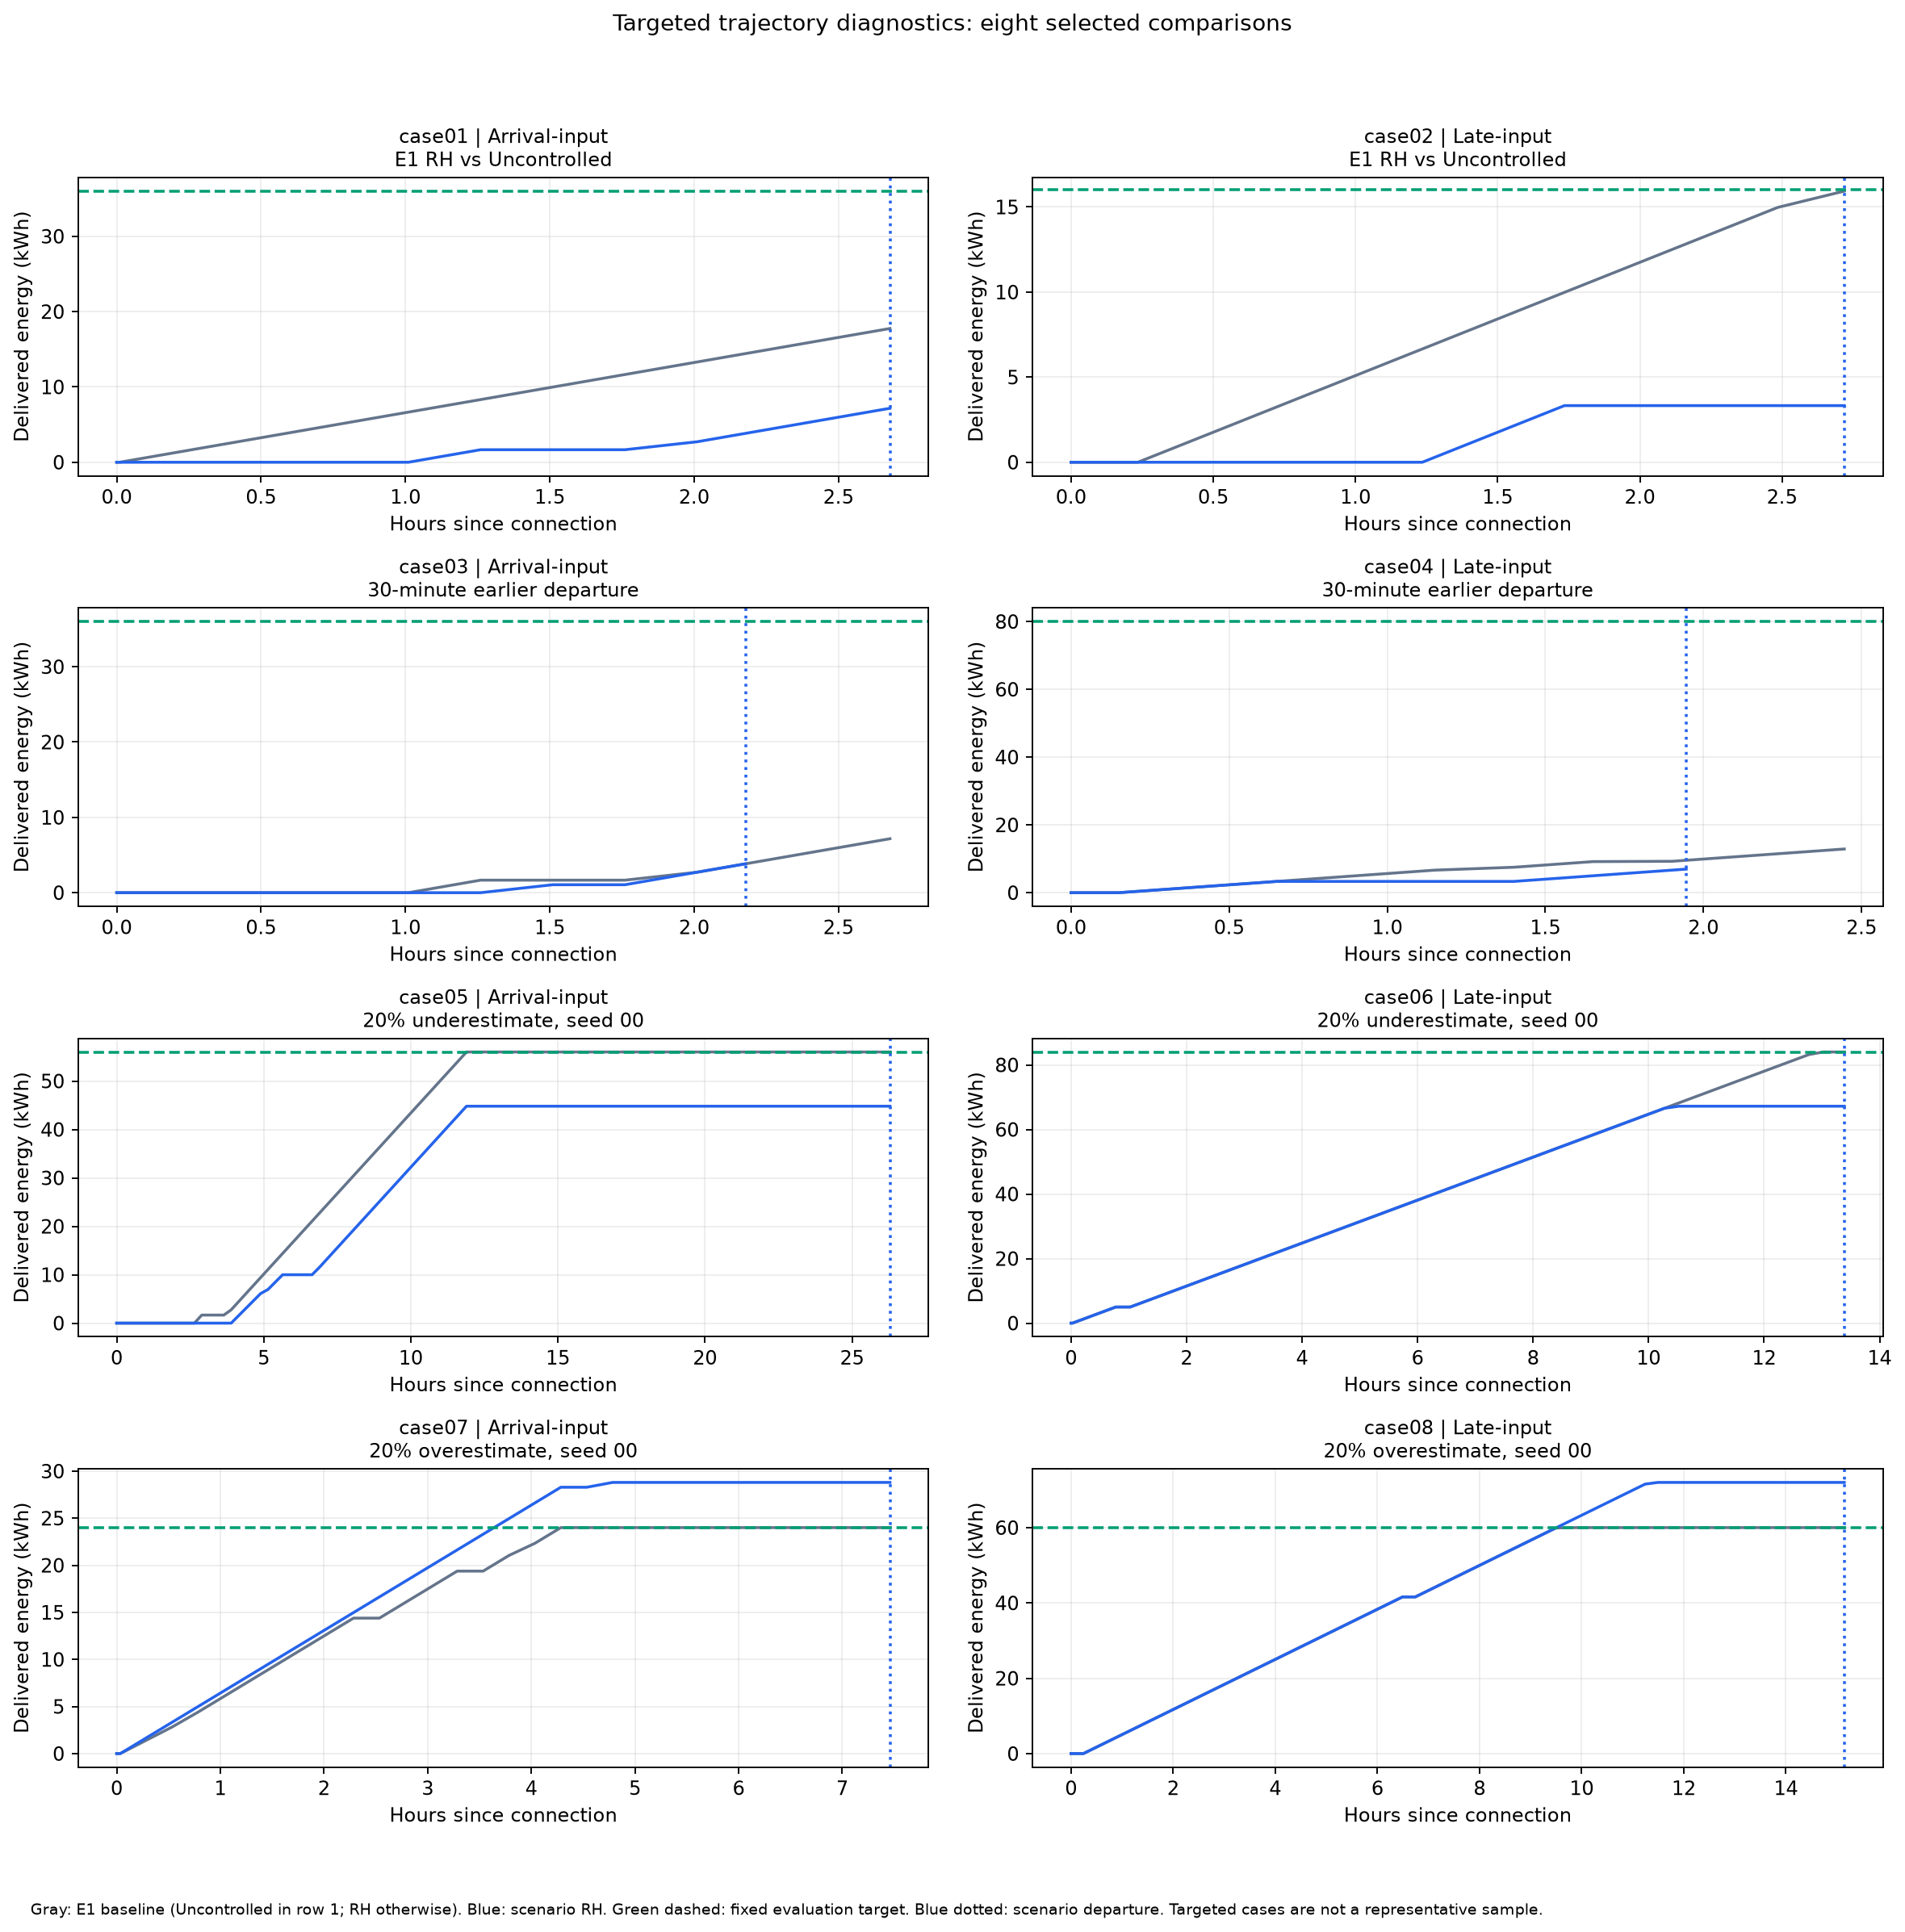

In [41]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import subprocess
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")
BATCH = ROOT / "results/logs/stage4_robustness_20261113T090451907487Z"
SUMMARY = BATCH / "summary_20261114T121318982512Z"

case_source = r'''
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1]
SUMMARY, OUT = Path(sys.argv[1]).resolve(), Path(sys.argv[2]).resolve()
OUT.mkdir(parents=True, exist_ok=False)
BATCH = SUMMARY.parent
E1 = ROOT / "results/logs/stage4_main_test_20261112T102930606571Z"
DATA = ROOT / "data/processed/caltech_12weeks_20261111T143402Z_9b087d"

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

summary_record = json.loads(
    (SUMMARY / "verification.json").read_text(encoding="utf-8")
)
assert summary_record["status"] == "passed"
assert summary_record["formal_scenarios"] == 22

expected = {}
for rel, value in summary_record["output_artifact_sha256"].items():
    path = SUMMARY / rel
    assert digest(path) == value, rel
    expected[path.resolve()] = value

# 实际轨迹使用已有记录中的哈希；
# 未在旧记录中保存哈希的内部诊断文件，仅建立当前快照。
snapshots, csv_cache, run_cache = {}, {}, {}

def checked(path):
    path = path.resolve()
    assert path.is_relative_to(ROOT)
    value = digest(path)
    if path in expected:
        assert value == expected[path], str(path)
    snapshots[path] = {
        "path": str(path.relative_to(ROOT)),
        "sha256": value,
        "integrity": (
            "prior_recorded_hash" if path in expected else "current_snapshot_only"
        ),
    }
    return path

def register_run(folder):
    folder = folder.resolve()
    if folder in run_cache:
        return
    path = folder / "verification.json"
    rel = str(path.relative_to(ROOT))
    assert digest(path) == summary_record["run_evidence_sha256"][rel]
    expected[path] = summary_record["run_evidence_sha256"][rel]
    record = json.loads(checked(path).read_text(encoding="utf-8"))
    assert record["status"] == "passed"
    assert not record["requires_review"]
    for key, value in record["source_and_input_sha256"].items():
        expected[(ROOT / key).resolve()] = value
    for key, value in record["output_artifact_sha256"].items():
        expected[(folder / key).resolve()] = value
    run_cache[folder] = record

register_run(E1)

def read_csv(path):
    path = checked(path)
    if path not in csv_cache:
        csv_cache[path] = pd.read_csv(path, dtype={"sessionID": str})
    return csv_cache[path].copy()

def times(series):
    return pd.to_datetime(
        series, utc=True, format="ISO8601", errors="raise"
    ).astype("datetime64[ns, UTC]")

sessions = read_csv(DATA / "sessions_with_split.csv")
events = read_csv(DATA / "environment_events.csv")
releases = read_csv(DATA / "input_release_events.csv")
station_path = checked(ROOT / "configs/station.yaml")
pmax = float(yaml.safe_load(
    station_path.read_text(encoding="utf-8")
)["evse_max_power_kW"])

def service(folder):
    return read_csv(folder / "session_service.csv").set_index("sessionID")

changes = read_csv(SUMMARY / "session_changes_vs_E1.csv")
cohorts = ["main_at_arrival", "supplement_after_submission"]
choices = []

# 固定排序规则：统计量降序、sessionID 升序。
def choose(frame, column):
    assert len(frame)
    return frame.sort_values(
        [column, "sessionID"], ascending=[False, True], kind="mergesort"
    ).iloc[0]["sessionID"]

for kind in ["E1_RH_vs_UC", "early30", "under20_seed00", "over20_seed00"]:
    for cohort in cohorts:
        if kind == "E1_RH_vs_UC":
            rh = service(E1 / cohort / "RH_LP")
            uc = service(E1 / cohort / "Uncontrolled")
            ranked = (
                rh["unmet_kwh"] - uc["unmet_kwh"]
            ).rename("delta").reset_index()
            sid = choose(ranked, "delta")
            scenario_run, baseline_method = E1, "Uncontrolled"
            factor = 1.0
        else:
            scenario_id = (
                "E4_early30" if kind == "early30" else "E4_req20_seed00"
            )
            scenario_run = BATCH / scenario_id
            register_run(scenario_run)
            ranked = changes[
                changes["scenario_id"].eq(scenario_id) &
                changes["cohort"].eq(cohort) &
                changes["method"].eq("RH_LP")
            ].copy()
            factors = read_csv(
                scenario_run / cohort / "request_factors.csv"
            )
            ranked = ranked.merge(
                factors, on="sessionID", validate="one_to_one"
            )
            if kind == "under20_seed00":
                ranked = ranked[ranked["factor"] < 1]
                sid = choose(ranked, "delta_unmet_kwh")
            elif kind == "over20_seed00":
                ranked = ranked[ranked["factor"] > 1]
                sid = choose(ranked, "delta_excess_kwh")
            else:
                sid = choose(ranked, "delta_unmet_kwh")
            factor = float(
                ranked.set_index("sessionID").loc[sid, "factor"]
            )
            baseline_method = "RH_LP"
        choices.append({
            "kind": kind, "cohort": cohort, "sessionID": sid,
            "scenario_run": scenario_run,
            "baseline_method": baseline_method, "factor": factor,
        })

def connection_inputs(run, cohort, sid):
    if run == E1:
        s, e, u = sessions.copy(), events.copy(), releases.copy()
    else:
        s = read_csv(run / cohort / "runtime_sessions.csv")
        e = read_csv(run / cohort / "scenario_environment_events.csv")
        u = read_csv(run / cohort / "runtime_input_release_events.csv")

    row = s[s["sessionID"].eq(sid)].iloc[0]
    boundary = e[e["sessionID"].eq(sid)].set_index("event_type")
    arrival = pd.Timestamp(boundary.loc["arrival", "event_time"])
    departure = pd.Timestamp(boundary.loc["departure", "event_time"])
    if cohort == "main_at_arrival":
        history = pd.DataFrame([{
            "when": arrival,
            "target_kwh": float(row["initial_kWhRequested"]),
            "expected_departure": pd.Timestamp(row["initial_requestedDeparture"]),
        }])
    else:
        valid = u["valid"].astype(str).str.strip().str.lower().isin(
            ["true", "1", "1.0"]
        )
        selected = u[u["sessionID"].eq(sid) & valid].copy()
        selected["modifiedAt"] = times(selected["modifiedAt"])
        selected = selected.sort_values(["modifiedAt", "input_order"])
        history = pd.DataFrame({
            "when": selected["modifiedAt"],
            "target_kwh": pd.to_numeric(selected["kWhRequested"]),
            "expected_departure": pd.to_datetime(
                selected["requestedDeparture"],
                utc=True, format="ISO8601", errors="raise"
            ),
        }).reset_index(drop=True)
    history["released_before_departure"] = (
        (history["when"] >= arrival) & (history["when"] < departure)
    )
    return arrival, departure, history

def trace(folder, sid, arrival, departure):
    station = read_csv(folder / "station_trajectory.csv")[["start", "end"]]
    vehicle = read_csv(folder / "session_trajectory.csv")
    vehicle = vehicle[vehicle["sessionID"].eq(sid)][
        ["start", "end", "actual_kw"]
    ]
    for frame in [station, vehicle]:
        frame["start"], frame["end"] = times(frame["start"]), times(frame["end"])
    station = station[
        station["start"].ge(arrival) & station["end"].le(departure)
    ].sort_values("start")
    frame = station.merge(
        vehicle, on=["start", "end"], how="left", validate="one_to_one"
    )
    frame["actual_kw"] = frame["actual_kw"].fillna(0.0)
    assert len(frame)
    assert frame.iloc[0]["start"] == arrival
    assert frame.iloc[-1]["end"] == departure
    assert frame["start"].iloc[1:].reset_index(drop=True).equals(
        frame["end"].iloc[:-1].reset_index(drop=True)
    )
    hours = (frame["end"] - frame["start"]).map(
        lambda value: value.value / 3_600_000_000_000
    )
    frame["energy_kwh"] = frame["actual_kw"] * hours
    return frame

def energy_after(frame, boundary):
    return sum(
        row.actual_kw * max(
            0, (row.end - max(row.start, boundary)).value
        ) / 3_600_000_000_000
        for row in frame.itertuples(index=False)
        if row.end > boundary
    )

def first_charge(frame):
    active = frame[frame["actual_kw"] > 1e-6]
    return None if active.empty else active.iloc[0]["start"]

def lp_context(folder, sid, arrival, departure, save_folder, label):
    # 内部文件仅作辅助上下文，历史哈希和当前快照分别记录。
    if not (folder / "decision_summary.csv").is_file():
        return []
    decisions = read_csv(folder / "decision_summary.csv")
    if "step_directory" not in decisions:
        return []
    decisions["time"] = times(decisions["time"])
    decisions = decisions[
        decisions["mode"].eq("lp") &
        decisions["time"].ge(arrival) &
        decisions["time"].lt(departure)
    ].sort_values("time")
    contexts = []
    for position, ordered in [
        ("first", decisions), ("last", decisions.iloc[::-1])
    ]:
        for row in ordered.to_dict("records"):
            step = Path(row["step_directory"]).resolve()
            assert step.is_relative_to(folder.resolve())
            case_path = checked(step / "case.json")
            case = json.loads(case_path.read_text(encoding="utf-8"))
            car = next(
                (c for c in case["sessions"] if str(c["id"]) == sid), None
            )
            if car is None:
                continue
            plan = read_csv(step / "lp/plan.csv")
            plan = plan[plan["sessionID"].eq(sid)].copy()
            slot_times = times(plan["slot"])
            late = sum(
                float(power) * max(
                    0, (slot + pd.Timedelta(minutes=15) -
                        max(slot, departure)).value
                ) / 3_600_000_000_000
                for slot, power in zip(slot_times, plan["power_kW"])
            )
            plan.to_csv(
                save_folder / f"{label}_{position}_vehicle_plan.csv",
                index=False
            )
            contexts.append({
                "side": label, "position": position,
                "time": row["time"],
                "remaining_demand_kwh": car["demand"],
                "available_slots": len(car["available"]),
                "planned_after_actual_departure_kwh": late,
                "case_integrity": snapshots[case_path]["integrity"],
                "plan_integrity": snapshots[
                    (step / "lp/plan.csv").resolve()
                ]["integrity"],
            })
            break
    return contexts

def curve(frame, arrival):
    x = [(frame.iloc[0]["start"] - arrival).value / 3.6e12]
    y = [0.0]
    for row in frame.itertuples(index=False):
        x.append((row.end - arrival).value / 3.6e12)
        y.append(y[-1] + row.energy_kwh)
    return x, y

def power_curve(frame, arrival):
    x, y = [], []
    for row in frame.itertuples(index=False):
        x.extend([
            (row.start - arrival).value / 3.6e12,
            (row.end - arrival).value / 3.6e12,
        ])
        y.extend([row.actual_kw, row.actual_kw])
    return x, y

records, all_contexts = [], []
overview, overview_axes = plt.subplots(4, 2, figsize=(14, 14))
short_names = {
    "E1_RH_vs_UC": "E1 RH vs Uncontrolled",
    "early30": "30-minute earlier departure",
    "under20_seed00": "20% underestimate, seed 00",
    "over20_seed00": "20% overestimate, seed 00",
}

for index, choice in enumerate(choices, start=1):
    sid, cohort, run = (
        choice["sessionID"], choice["cohort"], choice["scenario_run"]
    )
    folder = OUT / f"case{index:02d}"
    folder.mkdir()
    baseline_folder = E1 / cohort / choice["baseline_method"]
    scenario_folder = run / cohort / "RH_LP"
    arrival, departure, history = connection_inputs(run, cohort, sid)
    old_arrival, old_departure, old_history = connection_inputs(E1, cohort, sid)
    assert arrival == old_arrival

    baseline_service = service(baseline_folder).loc[sid]
    scenario_service = service(scenario_folder).loc[sid]
    target = float(scenario_service["evaluation_target_kwh"])
    assert abs(target - baseline_service["evaluation_target_kwh"]) <= 1e-8

    baseline_trace = trace(baseline_folder, sid, arrival, old_departure)
    scenario_trace = trace(scenario_folder, sid, arrival, departure)
    for frame, saved_service in [
        (baseline_trace, baseline_service),
        (scenario_trace, scenario_service)
    ]:
        delivered = float(frame["energy_kwh"].sum())
        assert abs(delivered - saved_service["delivered_kwh"]) <= 1e-5
        assert abs(max(target - delivered, 0) -
                   saved_service["unmet_kwh"]) <= 1e-5
        assert abs(max(delivered - target, 0) -
                   saved_service["excess_kwh"]) <= 1e-5

    baseline_trace.to_csv(folder / "baseline_trace.csv", index=False)
    scenario_trace.to_csv(folder / "scenario_trace.csv", index=False)
    old_history.to_csv(folder / "baseline_inputs.csv", index=False)
    history.to_csv(folder / "scenario_inputs.csv", index=False)

    before = history[history["released_before_departure"]]
    first_input = None if before.empty else before.iloc[0]["when"]
    latest_target = None if before.empty else float(before.iloc[-1]["target_kwh"])
    eligible = None if first_input is None else max(arrival, first_input).ceil("15min")
    available_hours = (
        0.0 if eligible is None else
        max(0, (departure - eligible).value) / 3.6e12
    )
    lower_bound = max(target - pmax * available_hours, 0)

    baseline_tail = energy_after(baseline_trace, departure)
    delivered_loss = (
        float(baseline_service["delivered_kwh"]) -
        float(scenario_service["delivered_kwh"])
    )
    prefix_difference = (
        float(baseline_service["delivered_kwh"]) - baseline_tail -
        float(scenario_service["delivered_kwh"])
    )
    assert abs(
        delivered_loss - baseline_tail - prefix_difference
    ) <= 1e-5

    contexts = []
    if choice["baseline_method"] == "RH_LP":
        contexts += lp_context(
            baseline_folder, sid, arrival, old_departure, folder, "baseline"
        )
    contexts += lp_context(
        scenario_folder, sid, arrival, departure, folder, "scenario"
    )
    for context in contexts:
        context.update(case_id=f"case{index:02d}", sessionID=sid)
    all_contexts.extend(contexts)
    pd.DataFrame(contexts).to_csv(folder / "LP_context.csv", index=False)

    first_b, first_s = first_charge(baseline_trace), first_charge(scenario_trace)
    flags = []
    if before.empty:
        flags.append("no_request_released_before_departure")
    if (first_b is not None and first_s is not None and
            first_s > first_b + pd.Timedelta(minutes=1)):
        flags.append("scenario_first_charge_later")
    if baseline_tail > 0.01:
        flags.append("baseline_charged_in_removed_tail")
    if (choice["factor"] < 1 and latest_target is not None and
            scenario_service["delivered_kwh"] >= latest_target - 0.01 and
            scenario_service["unmet_kwh"] > 0.01):
        flags.append("estimated_target_met_but_evaluation_target_unmet")
    if (choice["factor"] > 1 and
            scenario_service["excess_kwh"] > baseline_service["excess_kwh"] + 0.01):
        flags.append("excess_increased_with_overestimate")
    if any(
        c["side"] == "scenario" and
        c["planned_after_actual_departure_kwh"] > 0.01
        for c in contexts
    ):
        flags.append("LP_context_planned_service_after_actual_departure")

    record = {
        "case_id": f"case{index:02d}", "kind": choice["kind"],
        "cohort": cohort, "sessionID": sid, "factor": choice["factor"],
        "evaluation_target_kwh": target,
        "baseline_delivered_kwh": baseline_service["delivered_kwh"],
        "scenario_delivered_kwh": scenario_service["delivered_kwh"],
        "delta_unmet_kwh":
            scenario_service["unmet_kwh"] - baseline_service["unmet_kwh"],
        "delta_excess_kwh":
            scenario_service["excess_kwh"] - baseline_service["excess_kwh"],
        "baseline_tail_energy_kwh": baseline_tail,
        "prefix_delivery_difference_kwh": prefix_difference,
        "device_time_shortfall_lower_bound_kwh": lower_bound,
        "latest_released_operational_target_kwh": latest_target,
        "inputs_at_or_after_departure": int(
            (~history["released_before_departure"]).sum()
        ),
        "observations": "; ".join(flags) or "no predefined observation flag",
        "scenario_directory": str(scenario_folder.relative_to(ROOT)),
        "baseline_directory": str(baseline_folder.relative_to(ROOT)),
    }
    records.append(record)

    # 每个案例保留功率及累计交付图
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    baseline_label = f'E1 {choice["baseline_method"]}'
    for frame, label, color in [
        (baseline_trace, baseline_label, "#64748b"),
        (scenario_trace, "Scenario RH_LP", "#2563eb"),
    ]:
        x, y = power_curve(frame, arrival)
        axes[0].plot(x, y, color=color, label=label)
        x, y = curve(frame, arrival)
        axes[1].plot(x, y, color=color, label=label)
    for ax in axes:
        ax.axvline((departure - arrival).value / 3.6e12,
                   color="#2563eb", linestyle=":", label="Scenario departure")
        ax.grid(alpha=0.22)
    axes[1].axhline(target, color="#009e73", linestyle="--",
                    label="Fixed evaluation target")
    if not before.empty:
        hx = [(when - arrival).value / 3.6e12 for when in before["when"]]
        hy = before["target_kwh"].tolist()
        hx.append((departure - arrival).value / 3.6e12)
        hy.append(hy[-1])
        axes[1].step(hx, hy, where="post", color="#e69f00",
                     linestyle=":", label="Released operational target")
    axes[0].set_ylabel("Actual power (kW)")
    axes[1].set_ylabel("Cumulative delivery (kWh)")
    axes[1].set_xlabel("Hours since connection")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=8)
    fig.suptitle(f'case{index:02d}: {short_names[choice["kind"]]}')
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(folder / "trajectory.png", dpi=170, bbox_inches="tight")
    plt.close(fig)

    ax = overview_axes.flat[index - 1]
    for frame, label, color in [
        (baseline_trace, baseline_label, "#64748b"),
        (scenario_trace, "Scenario RH_LP", "#2563eb"),
    ]:
        x, y = curve(frame, arrival)
        ax.plot(x, y, color=color, label=label)
    ax.axhline(target, color="#009e73", linestyle="--")
    ax.axvline((departure - arrival).value / 3.6e12,
               color="#2563eb", linestyle=":")
    cohort_label = "Arrival-input" if cohort == "main_at_arrival" else "Late-input"
    ax.set_title(
        f'case{index:02d} | {cohort_label}\n{short_names[choice["kind"]]}',
        fontsize=10
    )
    ax.set_xlabel("Hours since connection")
    ax.set_ylabel("Delivered energy (kWh)")
    ax.grid(alpha=0.22)
    print(f"Checked case{index:02d}: {choice['kind']} / {cohort}", flush=True)

overview.suptitle(
    "Targeted trajectory diagnostics: eight selected comparisons", y=0.995
)
overview.text(
    0.02, 0.005,
    "Gray: E1 baseline (Uncontrolled in row 1; RH otherwise). "
    "Blue: scenario RH. Green dashed: fixed evaluation target. "
    "Blue dotted: scenario departure. Targeted cases are not a representative sample.",
    fontsize=8
)
overview.tight_layout(rect=(0, 0.04, 1, 0.97))
overview.savefig(OUT / "case_overview.png", dpi=170, bbox_inches="tight")
overview.savefig(OUT / "case_overview.svg", bbox_inches="tight")
plt.close(overview)

records = pd.DataFrame(records)
records.to_csv(OUT / "case_audit.csv", index=False)
pd.DataFrame(all_contexts).to_csv(OUT / "LP_context_all.csv", index=False)

# 确认读取期间文件未变化
for path, snapshot in snapshots.items():
    assert digest(path) == snapshot["sha256"], str(path)
pd.DataFrame(snapshots.values()).to_csv(
    OUT / "source_snapshot.csv", index=False
)

notes = [
    "# 定向案例核查",
    "",
    "8 个比较按事先确定的排序选取，不代表随机样本或独立统计重复。",
    "实际交付、缺口、超额均与已审计服务表一致。",
    "提前离站的交付差分解为基准被截去尾段的交付和截断前交付差；",
    "该恒等分解不把重调度、竞争容量等因素单独识别为因果效应。",
    "设备—时间缺口下界是忽略共享容量及后续请求变化的乐观下界。",
    "内部 LP 上下文仅辅助解释；旧哈希验证与当前快照在 source_snapshot.csv 分开记录。",
    "观察标记不是完整因果证明，不据此修改冻结参数。",
]
(OUT / "case_notes.md").write_text(
    "\n".join(notes) + "\n", encoding="utf-8"
)
artifacts = {
    str(path.relative_to(OUT)): digest(path)
    for path in sorted(OUT.rglob("*")) if path.is_file()
}
result = {
    "status": "passed",
    "scope": "eight targeted trajectory diagnostics; not whole stage 4",
    "case_count": 8,
    "checks": [
        "source summary and selected run evidence",
        "continuous case traces and service-table energy reconciliation",
        "fixed evaluation targets",
        "departure-tail delivery decomposition",
        "input visibility and operational-target records",
        "source files unchanged during inspection",
    ],
    "script_sha256": digest(Path(__file__)),
    "output_artifact_sha256": artifacts,
}
(OUT / "verification.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("\n=== CASE AUDIT ===")
print(records[[
    "case_id", "kind", "cohort", "sessionID", "factor",
    "delta_unmet_kwh", "delta_excess_kwh", "baseline_tail_energy_kwh",
    "prefix_delivery_difference_kwh", "device_time_shortfall_lower_bound_kwh",
    "observations",
]].round(6).to_string(index=False))
print("\n=== LP CONTEXT ===")
print(pd.DataFrame(all_contexts).to_string(index=False))
print("\nAudit:", result["status"])
print("Evidence directory:", OUT)
'''

ast.parse(case_source)
script = ROOT / "experiments/inspect_stage4_cases.py"
if script.exists():
    assert script.read_text(encoding="utf-8") == case_source, (
        "已有案例脚本不同，未覆盖。"
    )
else:
    script.write_text(case_source, encoding="utf-8")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
CASE_OUT = BATCH / f"case_audit_{stamp}"
log_path = BATCH / f"case_audit_{stamp}.log"

with log_path.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        [sys.executable, "-u", str(script), str(SUMMARY), str(CASE_OUT)],
        cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()
    code = process.wait()

print("\n退出码：", code)
print("日志：", log_path)
assert code == 0, "案例核查未通过，请回传日志末尾。"

from IPython.display import display, Image
display(Image(filename=str(CASE_OUT / "case_overview.png")))

Bound accepted run 1/27: E1_reference
Bound accepted run 2/27: E2_alpha020
Bound accepted run 3/27: E2_alpha080
Bound accepted run 4/27: E3_cap0375
Bound accepted run 5/27: E3_cap0625
Bound accepted run 6/27: E4_early15
Bound accepted run 7/27: E4_early30
Bound accepted run 8/27: E4_req10_seed00
Bound accepted run 9/27: E4_req20_seed00
Bound accepted run 10/27: E4_req10_seed01
Bound accepted run 11/27: E4_req20_seed01
Bound accepted run 12/27: E4_req10_seed02
Bound accepted run 13/27: E4_req20_seed02
Bound accepted run 14/27: E4_req10_seed03
Bound accepted run 15/27: E4_req20_seed03
Bound accepted run 16/27: E4_req10_seed04
Bound accepted run 17/27: E4_req20_seed04
Bound accepted run 18/27: E4_req10_seed05
Bound accepted run 19/27: E4_req20_seed05
Bound accepted run 20/27: E4_req10_seed06
Bound accepted run 21/27: E4_req20_seed06
Bound accepted run 22/27: E4_req10_seed07
Bound accepted run 23/27: E4_req20_seed07
Bound accepted run 24/27: E4_req10_seed08
Bound accepted run 25/27: E4_req

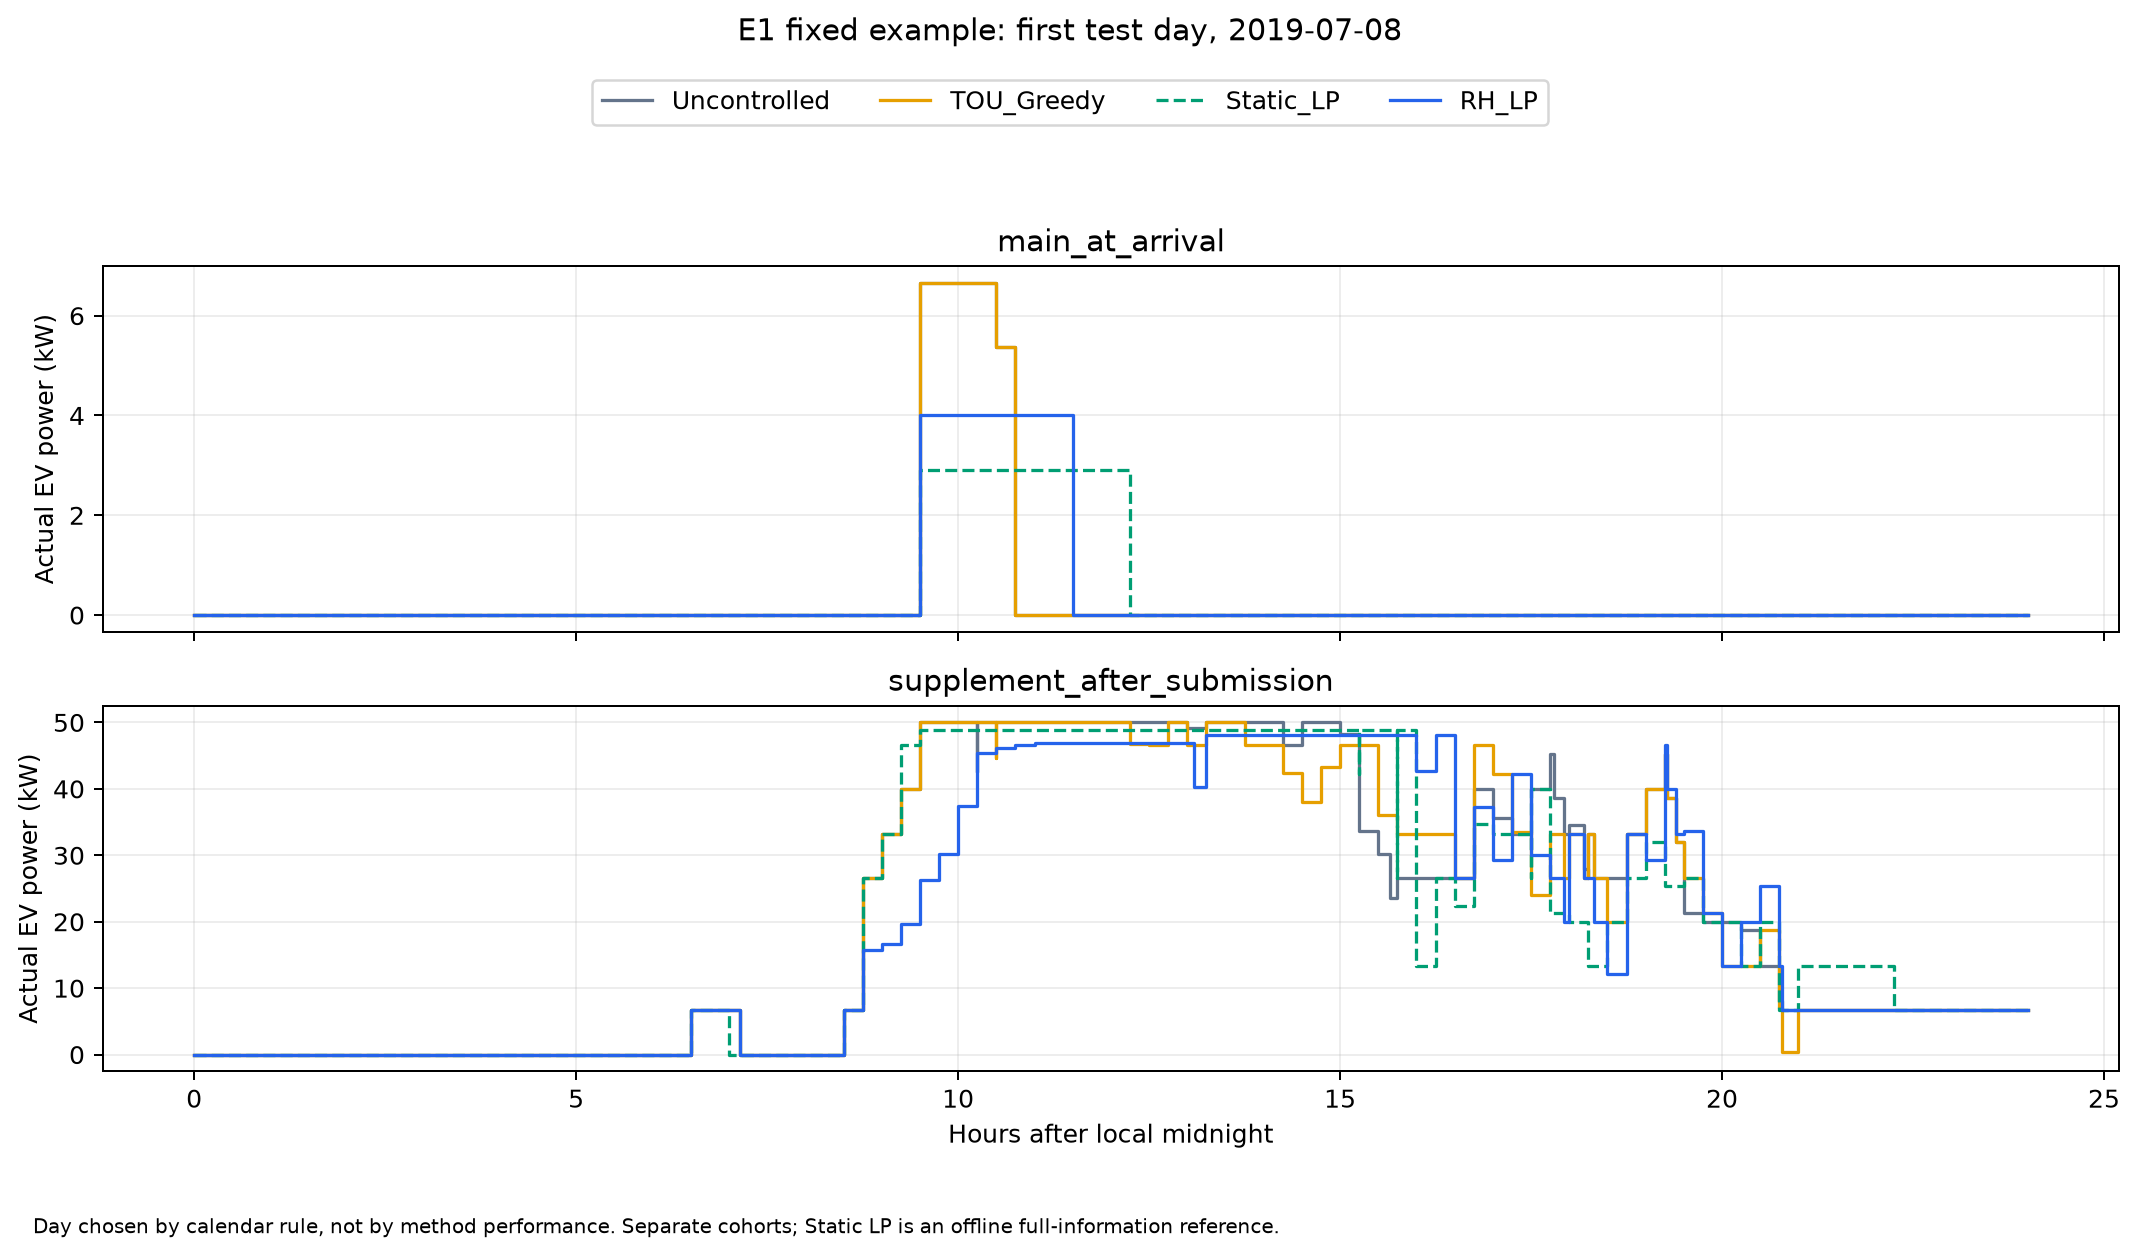

In [42]:
from pathlib import Path
from datetime import datetime, timezone
import ast
import subprocess
import sys

ROOT = Path("/home/jovyan/work/EV_Rolling_Horizon_Charging_Optimization")

archive_source = r'''
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import yaml
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[1]
OUT = Path(sys.argv[1]).resolve()
OUT.mkdir(parents=True, exist_ok=False)

E1 = ROOT / "results/logs/stage4_main_test_20261112T102930606571Z"
SENS = ROOT / "results/logs/stage4_sensitivity_20261112T124051538161Z"
SENS_SUM = SENS / "summary_20261113T083157781711Z"
ROB = ROOT / "results/logs/stage4_robustness_20261113T090451907487Z"
ROB_SUM = ROB / "summary_20261114T121318982512Z"
CASES = ROB / "case_audit_20261114T122830521605Z"

def digest(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

index, frozen_sources = {}, {}

def add_index(path, value=None, kind="artifact", basis="current_file_check"):
    path = path.resolve()
    assert path.is_relative_to(ROOT)
    value = digest(path) if value is None else value
    key = str(path.relative_to(ROOT))
    if key in index:
        assert index[key]["sha256"] == value, key
        if basis not in index[key]["verification_basis"]:
            index[key]["verification_basis"] += "; " + basis
        return
    index[key] = {
        "path": key, "sha256": value,
        "kind": kind, "verification_basis": basis,
    }

def accepted(folder, artifact_key="output_artifact_sha256", allowed=("passed",)):
    path = folder / "verification.json"
    record = json.loads(path.read_text(encoding="utf-8"))
    assert record["status"] in allowed, str(path)
    add_index(path, kind="acceptance_record")
    for rel, expected in record.get(artifact_key, {}).items():
        artifact = folder / rel
        assert digest(artifact) == expected, str(artifact)
        add_index(artifact, expected, "summary_or_case_product",
                  str(path.relative_to(ROOT)))
    return record

# ---------- 已通过的汇总、图表与案例 ----------
sens_summary = accepted(SENS_SUM)
rob_summary = accepted(ROB_SUM)
case_summary = accepted(CASES)
assert rob_summary["formal_scenarios"] == 22
assert rob_summary["new_method_cohort_results"] == 132
assert rob_summary["reused_reference_results"] == 6
assert rob_summary["seed_groups"] == 12
assert rob_summary["daily_paired_rows"] == 1932
assert rob_summary["zero_fallback"] is True
assert case_summary["case_count"] == 8

display_records = sorted(SENS.glob("summary_*_displayfix/verification.json"))
assert display_records, "未找到显示修正版图表。"
DISPLAY = display_records[-1].parent
display_summary = accepted(DISPLAY)
assert digest(ROOT / "experiments/summarize_sensitivity_v2.py") == (
    display_summary["summary_script_sha256"]
)

marker_records = sorted(SENS.glob("weight_plot_*/verification.json"))
assert marker_records, "未找到最终点形权重图。"
MARKERS = marker_records[-1].parent
marker_summary = accepted(
    MARKERS, artifact_key="artifacts",
    allowed=("generated_for_visual_review",)
)
assert digest(ROOT / "experiments/plot_weight_cost_peak_markers.py") == (
    marker_summary["script_sha256"]
)

# 案例来源快照：保留“历史记录哈希”和“当前快照”的区别
snapshots = pd.read_csv(CASES / "source_snapshot.csv")
for row in snapshots.to_dict("records"):
    assert digest(ROOT / row["path"]) == row["sha256"], row["path"]

for relative, expected in {
    "report/stage3_acceptance.md":
        "9a15bcd90ce19a4732e99c69453aa5fc83ba013cfe6acec093c8b0c0f501e980",
    "report/stage3_artifact_index.csv":
        "ffc0a0d13db243c2d302111b6ab4005a450a8b4f238e892c890423419113aa85",
}.items():
    assert digest(ROOT / relative) == expected
    add_index(ROOT / relative, expected, "E0_prior_acceptance")

# ---------- 绑定 27 个已验收运行 ----------
sens_config = yaml.safe_load(
    (ROOT / "configs/sensitivity.yaml").read_text(encoding="utf-8")
)
rob_config = yaml.safe_load(
    (ROOT / "configs/robustness.yaml").read_text(encoding="utf-8")
)
assert digest(ROOT / "configs/sensitivity.yaml") == (
    "7079f7033ae1bfd38d2bbf4a76115cfc1fe002137b779d034b3c4af36d1f23e4"
)
assert digest(ROOT / "configs/robustness.yaml") == (
    "5c52d926f1f94598f9f285babd0cacf0365db4b7fc085029f70d7be2618aa5e8"
)
run_specs = [("E1_reference", "E1", E1, 8)]
run_specs += [
    (s["id"], s["experiment"], SENS / s["id"], 8)
    for s in sens_config["scenarios"]
]
run_specs += [
    (s["id"], "E4", ROB / s["id"], 6)
    for s in rob_config["scenarios"]
]
assert len(run_specs) == 27

accepted_run_hashes = dict(sens_summary["source_evidence_sha256"])
for rel, value in rob_summary["run_evidence_sha256"].items():
    if rel in accepted_run_hashes:
        assert accepted_run_hashes[rel] == value
    accepted_run_hashes[rel] = value

frames = []
for number, (scenario_id, experiment, folder, rows) in enumerate(run_specs, 1):
    path = folder / "verification.json"
    relative = str(path.relative_to(ROOT))
    assert digest(path) == accepted_run_hashes[relative], relative
    record = json.loads(path.read_text(encoding="utf-8"))
    assert record["status"] == "passed"
    assert record.get("requires_review", False) is False
    add_index(path, kind="run_verification")

    # 原始运行产物已在运行及完整汇总中做过全量哈希核验。
    # 索引绑定那些已接受的记录，不把这里称作另一次全量重算。
    for rel, value in record["output_artifact_sha256"].items():
        add_index(
            folder / rel, value, "recorded_run_artifact",
            "accepted run and full-summary audit: " + relative
        )
    for rel, value in record["source_and_input_sha256"].items():
        source_path = (ROOT / rel).resolve()
        if source_path in frozen_sources:
            assert frozen_sources[source_path] == value, rel
        frozen_sources[source_path] = value

    comparison_path = folder / "comparison.csv"
    frame = pd.read_csv(comparison_path)
    assert len(frame) == rows
    assert not frame.duplicated(["cohort", "method"]).any()
    assert frame["fallback_count"].eq(0).all()
    assert frame["requires_review"].astype(str).str.lower().eq("false").all()
    for cohort, count in [
        ("main_at_arrival", 39), ("supplement_after_submission", 468)
    ]:
        assert frame.loc[frame["cohort"].eq(cohort), "sessions"].eq(count).all()
    if experiment == "E4":
        assert frame["smoke"].astype(str).str.lower().eq("false").all()
        assert frame["bypass_transform"].astype(str).str.lower().eq("false").all()

    frame["scenario_id"] = scenario_id
    frame["experiment"] = experiment
    frame["evidence_directory"] = str(folder.relative_to(ROOT))
    frame["run_verification_sha256"] = digest(path)
    frames.append(frame)
    add_index(comparison_path, kind="run_comparison")
    if (folder / "stdout_stderr.txt").exists():
        add_index(folder / "stdout_stderr.txt", kind="run_log")
    print(f"Bound accepted run {number}/27: {scenario_id}", flush=True)

for path, value in frozen_sources.items():
    assert digest(path) == value, str(path)
    add_index(path, value, "frozen_source_or_input", "current frozen-source check")

combined = pd.concat(frames, ignore_index=True)
assert len(combined) == 172
assert not combined.duplicated(["scenario_id", "cohort", "method"]).any()
assert combined.groupby("experiment").size().to_dict() == {
    "E1": 8, "E2": 16, "E3": 16, "E4": 132
}
static = combined["method"].eq("Static_LP")
assert combined.loc[static, "information"].eq(
    "offline_full_information_oracle"
).all()

norm = yaml.safe_load(
    (ROOT / "configs/normalization.yaml").read_text(encoding="utf-8")
)
assert abs(norm["C_ref"] - 2.88) < 1e-12
assert abs(norm["P_ref"] - 6.656) < 1e-12
combined["C_ref_USD"] = norm["C_ref"]
combined["P_ref_kW"] = norm["P_ref"]

# ---------- 固定规则的主实验负荷示例：测试期第一天 ----------
e1_record = json.loads(
    (E1 / "verification.json").read_text(encoding="utf-8")
)
splits = yaml.safe_load(
    (ROOT / "configs/splits.yaml").read_text(encoding="utf-8")
)
day_start = pd.Timestamp(
    splits["splits"]["test"]["start_utc_inclusive"]
).tz_convert("America/Los_Angeles")
day_end = day_start + pd.DateOffset(days=1)
colors = {
    "Uncontrolled": "#64748b", "TOU_Greedy": "#e69f00",
    "Static_LP": "#009e73", "RH_LP": "#2563eb",
}
cohorts = ["main_at_arrival", "supplement_after_submission"]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, cohort in zip(axes, cohorts):
    for method, color in colors.items():
        path = E1 / cohort / method / "station_trajectory.csv"
        key = str(path.relative_to(E1))
        assert digest(path) == e1_record["output_artifact_sha256"][key]
        trace = pd.read_csv(path)
        trace["start"] = pd.to_datetime(trace["start"], utc=True, format="ISO8601")
        trace["end"] = pd.to_datetime(trace["end"], utc=True, format="ISO8601")
        trace = trace[
            trace["end"].gt(day_start) & trace["start"].lt(day_end)
        ]
        x, y = [], []
        for row in trace.itertuples(index=False):
            a, b = max(row.start, day_start), min(row.end, day_end)
            x.extend([
                (a - day_start).value / 3.6e12,
                (b - day_start).value / 3.6e12,
            ])
            y.extend([row.total_kw, row.total_kw])
        ax.plot(
            x, y, color=color, label=method,
            linestyle="--" if method == "Static_LP" else "-", linewidth=1.3
        )
    ax.set_title(cohort)
    ax.set_ylabel("Actual EV power (kW)")
    ax.grid(alpha=0.22)
axes[1].set_xlabel("Hours after local midnight")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           bbox_to_anchor=(0.5, 0.94), ncol=4)
fig.suptitle(f"E1 fixed example: first test day, {day_start.date()}")
fig.text(
    0.02, 0.015,
    "Day chosen by calendar rule, not by method performance. "
    "Separate cohorts; Static LP is an offline full-information reference.",
    fontsize=8
)
fig.tight_layout(rect=(0, 0.06, 1, 0.88))
for extension in ["png", "svg"]:
    fig.savefig(OUT / f"E1_first_test_day.{extension}",
                dpi=180, bbox_inches="tight")
plt.close(fig)

# ---------- 生成可引用的发现与验收报告 ----------
case_table = pd.read_csv(CASES / "case_audit.csv", dtype={"sessionID": str})
assert len(case_table) == 8
unique_sessions = len(case_table[["cohort", "sessionID"]].drop_duplicates())
seed_stats = pd.read_csv(ROB_SUM / "seed_statistics.csv")
early = pd.read_csv(ROB_SUM / "early_departure_comparison.csv")
pair_stats = pd.read_csv(ROB_SUM / "RH_paired_seed_statistics.csv")
sensitivity = pd.read_csv(SENS / "sensitivity_results.csv")
e1 = combined[combined["experiment"].eq("E1")].copy()

def markdown_table(frame):
    columns = list(frame.columns)
    lines = [
        "| " + " | ".join(map(str, columns)) + " |",
        "| " + " | ".join(["---"] * len(columns)) + " |",
    ]
    def format_value(value):
        if pd.isna(value):
            return "NA"
        if isinstance(value, (float, np.floating)):
            return f"{value:.6f}"
        return str(value).replace("|", "/").replace("\n", " ")
    for values in frame.itertuples(index=False, name=None):
        lines.append("| " + " | ".join(format_value(v) for v in values) + " |")
    return "\n".join(lines)

def link(path):
    return "../" + str(path.relative_to(ROOT))

main_view = e1[[
    "cohort", "method", "cost_USD", "delivered_kwh", "unmet_kwh",
    "energy_satisfaction", "max_peak_kW", "active_P95_seconds",
    "offline_solve_wall_seconds"
]].copy()
seed_view = seed_stats[["cohort", "method", "amplitude"]].copy()
for metric in ["cost_USD", "unmet_kwh", "excess_kwh"]:
    seed_view[metric + "_mean"] = seed_stats[metric + "__mean"]
seed_view["satisfaction_mean_pct"] = seed_stats["energy_satisfaction__mean"] * 100
seed_view["satisfaction_SD_pp"] = seed_stats["energy_satisfaction__std"] * 100

lines = [
    "# 阶段四：实验发现",
    "",
    "本阶段完成必做主实验、权重、容量、需求估计误差及提前离站评价。",
    "结果支持特定数据与假设下的权衡和反例，不预设 RH 优势。",
    "",
    "## 实验口径",
    "",
    "- Caltech 单站聚合连续功率情景，两队列分别运行和评价。",
    "- 测试期为洛杉矶当地 [2019-07-08, 2019-07-29)，21 个完整自然日。",
    "- 严格到达输入队列 39 条，晚提交补充队列 468 条，不混合计算为全站结论。",
    "- 主方案 alpha=0.5、容量 50 kW、控制间隔 15 分钟、基础窗口 24 小时并按已知预计离站延伸。",
    "- C_ref=2.88 USD、P_ref=6.656 kW，开发集确定后保持不变。",
    "- Static LP 为完整信息离线参考，真实连接完整时段口径与在线中途离站执行不同；不自动作为在线缺口下界。",
    "- 电价和容量为实验情景；未验证原 Caltech 支路与相位约束，不代表实际账单。",
    "",
    "## E1 主比较",
    "",
    markdown_table(main_view),
    "",
]
for cohort in cohorts:
    group = e1[e1["cohort"].eq(cohort)].set_index("method")
    rh, uc = group.loc["RH_LP"], group.loc["Uncontrolled"]
    lines.append(
        f'- {cohort}：RH 相对 Uncontrolled 的费用差为 '
        f'{100*(rh["cost_USD"]-uc["cost_USD"])/uc["cost_USD"]:.3f}%，'
        f'全期峰值差为 '
        f'{100*(rh["max_peak_kW"]-uc["max_peak_kW"])/uc["max_peak_kW"]:.3f}%，'
        f'满足率差为 '
        f'{100*(rh["energy_satisfaction"]-uc["energy_satisfaction"]):.3f} 个百分点。'
    )
lines += [
    "",
    "费用降低伴随服务差异，不能将这些费用差直接称为同等服务下的节费收益。",
    "",
    "## E2 权重与 E3 容量",
    "",
    "预设 alpha=0.2/0.5/0.8、容量=37.5/50/62.5 kW；共享基准复用 E1。",
    "RH 实际费用与服务未随权重呈简单单调关系；三个权重点不构成完整 Pareto 前沿。",
    "主队列在本容量网格下结果不变；补充队列容量增加时服务改善，低容量下低费用伴随较多缺口。",
    "",
    markdown_table(sensitivity[sensitivity["method"].eq("RH_LP")][[
        "scenario_id", "cohort", "alpha", "capacity_kw",
        "cost_USD", "unmet_kwh", "energy_satisfaction", "max_peak_kW"
    ]]),
    "",
    "## E4 需求估计误差",
    "",
    "每车固定正负号，误差幅度 10%/20%，10 个种子配对，原始评价目标固定。",
    "同一车在两个幅度、后续输入更新及三种在线方法间共享扰动方向。",
    "零误差参考复用 E1，运行入口等价性仅做过小样本对照，不声称全量零组重跑。",
    "",
    markdown_table(seed_view),
    "",
    "误差增大时三方法平均满足率下降，缺口及超额增加。RH 绝对服务较低，不等于相对自身基准的增量退化始终更大。",
    "补充队列中，RH 相对 TOU 的平均费用较高、满足率较低，本情景没有显示费用与服务优势。",
    "超额交付计入电费，但不能抵消其他车辆缺口；请求电量不是电池物理容量，不将超额服务称为真实电池过充。",
    "",
    markdown_table(pair_stats[[
        "cohort", "amplitude", "baseline_method",
        "delta_cost_USD__mean", "delta_unmet_kwh__mean",
        "delta_satisfaction_pp__mean", "delta_excess_kwh__mean"
    ]]),
    "",
    "## E4 提前离站",
    "",
    "实际离站分别提前 15/30 分钟，调度器可见预计离站不变；保留全部会话并审计短连接截断。",
    "",
    markdown_table(early[[
        "cohort", "method", "advance_minutes", "cost_USD",
        "unmet_kwh", "excess_kwh", "energy_satisfaction",
        "delta_satisfaction_pp"
    ]]),
    "",
    "提前 30 分钟时，RH 主/补充满足率分别下降 5.87410/4.93007 个百分点，均大于本次规则基线的降幅。",
    "费用同时降低主要需要结合少交付电量解释，不能单独作为调度收益。",
    "",
    "## 轨迹案例",
    "",
    f"8 个定向比较涉及 {unique_sessions} 个不同会话；同一会话可用于不同对照，不当作独立重复。",
    "",
    markdown_table(case_table[[
        "case_id", "kind", "cohort", "sessionID", "factor",
        "delta_unmet_kwh", "delta_excess_kwh",
        "baseline_tail_energy_kwh", "prefix_delivery_difference_kwh",
        "device_time_shortfall_lower_bound_kwh"
    ]]),
    "",
    "- case01/02：RH 实际较晚开始充电；case01 同时存在约 18.243 kWh 的设备—可用时间缺口下界，不能把全部缺口归因于调度。",
    "- case03：新增缺口约 3.328 kWh，几乎等于被移去尾段中的基准交付。",
    "- case04：新增缺口约 5.937 kWh，由尾段 3.328 kWh 与截断前交付差约 2.609 kWh 组成；恒等分解不是独立因果识别。",
    "- case05/06：低估目标达到后仍存在原始评价缺口，新增缺口分别为 11.2/16.8 kWh。",
    "- case07/08：高估对应新增超额约 4.8/12 kWh，不能用于抵消其他车辆缺口。",
    "- 实际轨迹、输入和服务表为主证据。E1 内部 LP 上下文仅当前快照，相关完整性层级在案例 source_snapshot.csv 中保留。",
    "",
    "## 统计与适用边界",
    "",
    "- 10 种子标准差描述固定测试期内的合成扰动波动，不是跨日期或跨站点置信区间。",
    "- 日级配对保留全部 21 天和零负荷日；只有三个完整周，不强行宣称显著性，也不把 15 分钟点当独立样本。",
    "- 需求误差为受控合成机制，不是真实可部署预测器的验证。",
    "- 严格队列样本仅 39 条且存在选择偏差；两个队列结论分别解释。",
    "- E5 计算网格/窗口扩展、E6 电价/非理想响应扩展未开展，不能声称已覆盖。",
    "- 本阶段没有按测试结果重新选择主参数；报告归档与干净环境复现属于阶段五。",
    "",
    "## 主要证据",
    "",
    f"- [E1 主表]({link(ROOT / 'results/main_comparison.csv')})",
    f"- [E2/E3 汇总]({link(SENS_SUM / 'verification.json')})",
    f"- [最终权重图]({link(MARKERS / 'weight_cost_peak.png')})",
    f"- [E4 汇总]({link(ROB_SUM / 'verification.json')})",
    f"- [日级配对差异]({link(ROB_SUM / 'daily_RH_paired_differences.csv')})",
    f"- [八案例核查]({link(CASES / 'verification.json')})",
    f"- [固定首日负荷示例]({link(OUT / 'E1_first_test_day.png')})",
]

# ---------- 发布派生产物，保护既有文件 ----------
new_paths = [
    ROOT / "results/stage4_all_comparisons.csv",
    ROOT / "report/findings.md",
    ROOT / "report/stage4_acceptance.md",
    ROOT / "report/stage4_artifact_index.csv",
]
for path in new_paths:
    assert not path.exists(), f"归档目标已存在，未覆盖：{path}"

manifest_path = ROOT / "results/run_manifest.csv"
assert manifest_path.resolve() not in frozen_sources
if manifest_path.exists():
    assert manifest_path.read_bytes() == (E1 / "run_manifest.csv").read_bytes(), (
        "现有全局运行清单已变化，未覆盖。"
    )
    (OUT / "previous_run_manifest.csv").write_bytes(manifest_path.read_bytes())

assert digest(ROOT / "results/main_comparison.csv") == digest(E1 / "comparison.csv")

all_path = ROOT / "results/stage4_all_comparisons.csv"
combined.to_csv(all_path, index=False)
manifest_columns = [
    "scenario_id", "experiment", "run_id", "split", "cohort", "method",
    "alpha", "capacity_kw", "base_horizon_hours",
    "evidence_directory", "run_verification_sha256", "requires_review",
]
combined[manifest_columns].to_csv(manifest_path, index=False)
assert len(pd.read_csv(all_path)) == len(pd.read_csv(manifest_path)) == 172

findings_path = ROOT / "report/findings.md"
findings_path.write_text("\n".join(lines) + "\n", encoding="utf-8")

acceptance_text = f"""# 阶段四：实验评价验收

结论：必做范围内通过。归档 UTC 时间：{datetime.now(timezone.utc).isoformat()}。

- E0：引用已通过的阶段三正确性与集成证据；各组检查不简单相加为独立测试总数。
- E1：四方法、两个队列，共 8 组正式主实验结果。
- E2/E3：4 个新增预设情景，共 32 组结果，共享基准复用 E1。
- E4：22 个情景，共 132 组新增结果；6 组在线零参考复用 E1，不重复计入新实验。
- 共 27 个正式运行、172 组方法/队列/情景结果，均无回退或待审查标记。
- E4 固定目标、配对扰动、12 个十种子组、1932 行日级配对及图表已验收。
- 8 个定向案例比较、{unique_sessions} 个不同会话已核对实际交付与服务表。
- 所有方法保留费用、服务、峰值、硬约束及计算时间字段；Static LP 离线身份清楚。
- 结果包括无改进与反例，不以预定节费百分比作为验收条件。
- E5/E6 扩展未开展；阶段五报告与干净环境复现不在本次验收范围。

最终发现见 `findings.md`，证据索引见 `stage4_artifact_index.csv`。
原始运行产物的哈希沿用已接受的运行和完整汇总审计，并绑定记录哈希；
本归档另行核验冻结来源、新发布文件及选定示例轨迹，不声称重新执行全部仿真。

索引不包含索引自身和闭合验收 JSON，二者关系由归档目录的 verification.json 记录。
"""
acceptance_path = ROOT / "report/stage4_acceptance.md"
acceptance_path.write_text(acceptance_text, encoding="utf-8")

for path in [
    all_path, manifest_path, ROOT / "results/main_comparison.csv",
    findings_path, acceptance_path, Path(__file__),
    OUT / "E1_first_test_day.png", OUT / "E1_first_test_day.svg",
]:
    add_index(path, kind="stage4_published_product")
if (OUT / "previous_run_manifest.csv").exists():
    add_index(OUT / "previous_run_manifest.csv", kind="preserved_previous_manifest")

index_path = ROOT / "report/stage4_artifact_index.csv"
pd.DataFrame(index.values()).sort_values("path").to_csv(index_path, index=False)

# 发布派生文件没有改变冻结的模型、输入及配置
for path, value in frozen_sources.items():
    assert digest(path) == value, str(path)

published = [
    all_path, manifest_path, ROOT / "results/main_comparison.csv",
    findings_path, acceptance_path, index_path,
    OUT / "E1_first_test_day.png", OUT / "E1_first_test_day.svg",
]
result = {
    "status": "passed",
    "scope": "stage 4 required experiments and results evaluation",
    "accepted_runs": 27,
    "unique_method_cohort_scenario_rows": 172,
    "rows_by_experiment": {"E1": 8, "E2": 16, "E3": 16, "E4": 132},
    "E4_reused_reference_rows_not_counted_as_new": 6,
    "case_comparisons": 8,
    "unique_case_sessions": unique_sessions,
    "artifact_index_rows": len(index),
    "source_acceptance_record_sha256": {
        str(path.relative_to(ROOT)): digest(path)
        for path in [
            SENS_SUM / "verification.json", DISPLAY / "verification.json",
            MARKERS / "verification.json", ROB_SUM / "verification.json",
            CASES / "verification.json",
        ]
    },
    "published_artifact_sha256": {
        str(path.relative_to(ROOT)): digest(path) for path in published
    },
    "optional_not_run": ["E5", "E6"],
    "stage5_accepted": False,
}
(OUT / "verification.json").write_text(
    json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("\n=== STAGE 4 ACCEPTANCE ===")
print(json.dumps(result, ensure_ascii=False, indent=2))
print("\nArchive directory:", OUT)
print("Findings:", findings_path)
print("Acceptance report:", acceptance_path)
print("Artifact index:", index_path)
'''

ast.parse(archive_source)
script = ROOT / "experiments/compare_results.py"
if script.exists():
    assert script.read_text(encoding="utf-8") == archive_source, (
        "已有 compare_results.py 内容不同，未覆盖。"
    )
else:
    script.write_text(archive_source, encoding="utf-8")

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
STAGE4_OUT = ROOT / "results/logs" / f"stage4_acceptance_{stamp}"
log_path = ROOT / "results/logs" / f"stage4_acceptance_{stamp}.log"

with log_path.open("w", encoding="utf-8") as log:
    process = subprocess.Popen(
        [sys.executable, "-u", str(script), str(STAGE4_OUT)],
        cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
        log.flush()
    code = process.wait()

print("\n归档退出码：", code)
print("日志：", log_path)
assert code == 0, "归档未通过，请回传日志末尾，保留当前文件。"

from IPython.display import display, Image
display(Image(filename=str(STAGE4_OUT / "E1_first_test_day.png")))